
# Stage 2 — Exploratory Analysis

## Research Objective

This notebook explores the historical return behaviour, volatility, leverage effects, drawdowns, and semiconductor-market relationships of SOXL, SOXS, and SOXX.

NASDAQSOX provides additional semiconductor-sector context. VIXCLS provides a broader market-implied volatility measure.

The goal is to understand observed risk characteristics before building the statistical risk models in later stages.

## Research Periods

- **Development:** March 2010–December 2019
- **Walk-forward evaluation:** January 2020–December 2025
- **Final holdout:** January 2026–October 30, 2026

Descriptive exploratory analysis that could influence model design is restricted to the development period. Evaluation and holdout outcomes are reserved for later stages.

## Methodology and Restrictions

1. Reuse the five preserved and validated primary data sources from Notebook 01.
2. Calculate ETF returns from adjusted closing prices.
3. Align financial observations using actual trading dates.
4. Keep original source files unchanged.
5. Account for historical benchmark differences, including predecessor IGW history.
6. Exclude unreliable early SOXS volume from volume-based conclusions.
7. Distinguish descriptive market relationships from predictive evidence.
8. Do not fit forecasting models or optimize trading strategies in this notebook.

## 2.1 — Data Loading and Trading-Date Alignment


In [1]:

# ============================================================
# 2.1.1 — Load preserved market data and verify source identity
# ============================================================

from pathlib import Path
import hashlib
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project root.
# Jupyter may run from the project root or notebooks/ folder.
current_dir = Path.cwd().resolve()

if (current_dir / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot find data/raw. Check the Jupyter working directory."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
MANIFEST_PATH = PROJECT_ROOT / "data" / "manifest.json"

# Match the exact filenames used in Notebook 01.
source_files = {
    "SOXL": ("soxl_yahoo_daily.csv", "Date"),
    "SOXS": ("soxs_yahoo_daily.csv", "Date"),
    "SOXX": ("soxx_yahoo_daily.csv", "Date"),
    "NASDAQSOX": ("nasdaqsox_fred_original.csv", "observation_date"),
    "VIXCLS": ("vix_fred_original.csv", "observation_date"),
}

# Read the existing source manifest.
with open(MANIFEST_PATH, "r", encoding="utf-8") as file:
    manifest = json.load(file)

if manifest.get("errors"):
    raise ValueError("The source manifest contains collection errors.")

# Associate each recorded filename with its original SHA-256 hash.
manifest_hashes = {
    Path(record["file"]).name: record["sha256"]
    for record in manifest["sources"].values()
}

datasets = {}
inventory = []

for name, (filename, date_column) in source_files.items():

    path = DATA_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(f"Missing source file: {path}")

    # Confirm that the original CSV has not changed.
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    expected_hash = manifest_hashes.get(filename)

    if actual_hash != expected_hash:
        raise ValueError(f"Source checksum mismatch: {name}")

    # Load a copy into memory without modifying the source file.
    df = pd.read_csv(path, parse_dates=[date_column])
    datasets[name] = df

    inventory.append({
        "Source": name,
        "Rows": len(df),
        "First Date": df[date_column].min().date(),
        "Last Date": df[date_column].max().date(),
        "Manifest Match": True
    })

print("Project root:", PROJECT_ROOT)
print("\nPreserved source inventory:")

display(pd.DataFrame(inventory))

print("\nAll five original source checksums match.")
print("No raw data files were modified.")


Project root: /Users/nishanthselvakumar/Downloads/Personal Project - SOXL

Preserved source inventory:


,Source,Rows,First Date,Last Date,Manifest Match
0,SOXL,4187,2010-03-11,2026-10-30,True
1,SOXS,4187,2010-03-11,2026-10-30,True
2,SOXX,4195,2010-03-01,2026-10-30,True
3,NASDAQSOX,4350,2010-03-01,2026-10-30,True
4,VIXCLS,4350,2010-03-01,2026-10-30,True



All five original source checksums match.
No raw data files were modified.


In [2]:

# ============================================================
# 2.1.2 — Align trading dates and calculate development returns
# ============================================================

# Keep only the date and adjusted closing price of each ETF.
etf_tables = []

for ticker in ["SOXL", "SOXS", "SOXX"]:
    table = datasets[ticker][["Date", "Adj Close"]].copy()
    table = table.rename(columns={"Adj Close": ticker})
    etf_tables.append(table)

# Inner joins retain dates shared by all three ETFs.
aligned = etf_tables[0]

for table in etf_tables[1:]:
    aligned = aligned.merge(
        table,
        on="Date",
        how="inner",
        validate="one_to_one"
    )

# Prepare historical semiconductor index values.
sector = datasets["NASDAQSOX"][
    ["observation_date", "NASDAQSOX"]
].copy()

sector = sector.rename(
    columns={"observation_date": "Date"}
)

sector["NASDAQSOX"] = pd.to_numeric(
    sector["NASDAQSOX"], errors="coerce"
)

# Prepare historical VIX values.
vix = datasets["VIXCLS"][
    ["observation_date", "VIXCLS"]
].copy()

vix = vix.rename(
    columns={"observation_date": "Date"}
)

vix["VIXCLS"] = pd.to_numeric(
    vix["VIXCLS"], errors="coerce"
)

# Join sector and VIX observations to ETF trading dates.
aligned = aligned.merge(
    sector, on="Date", how="left", validate="one_to_one"
)

aligned = aligned.merge(
    vix, on="Date", how="left", validate="one_to_one"
)

aligned = aligned.sort_values("Date").reset_index(drop=True)

# Restrict exploratory calculations to the development period.
development = aligned.loc[
    (aligned["Date"] >= "2010-03-11") &
    (aligned["Date"] <= "2019-12-31")
].copy()

# Confirm that every development date has all five values.
assert development[
    ["SOXL", "SOXS", "SOXX", "NASDAQSOX", "VIXCLS"]
].notna().all().all(), "Missing development-period values detected."

# Calculate daily percentage returns using adjusted prices.
for ticker in ["SOXL", "SOXS", "SOXX"]:
    development[f"{ticker} Return (%)"] = (
        development[ticker].pct_change(fill_method=None) * 100
    )

# The first date has no preceding aligned price observation.
return_columns = [
    "SOXL Return (%)",
    "SOXS Return (%)",
    "SOXX Return (%)"
]

development_returns = development.dropna(
    subset=return_columns
).copy()

print("Full shared ETF calendar:", len(aligned))
print("Development price observations:", len(development))
print("Development daily-return observations:", len(development_returns))

print("\nFirst usable return date:",
      development_returns["Date"].min().date())

print("Last development date:",
      development_returns["Date"].max().date())

print("\nFirst five calculated daily returns:")

display(
    development_returns[["Date"] + return_columns].head()
)


Full shared ETF calendar: 4187
Development price observations: 2470
Development daily-return observations: 2469

First usable return date: 2010-03-12
Last development date: 2019-12-31

First five calculated daily returns:


,Date,SOXL Return (%),SOXS Return (%),SOXX Return (%)
1,2010-03-12,-2.472817,2.060587,-0.186571
2,2010-03-15,-3.156618,3.624429,-1.079956
3,2010-03-16,8.121851,-8.145545,2.771390
4,2010-03-17,3.607532,0.000000,1.613860
5,2010-03-18,-2.432580,0.000000,-0.924818



### 2.1.3 — Understanding Daily Returns

#### What is a daily return?

A daily return measures the percentage change in an investment's value between two consecutive trading days.

For this project, ETF returns are calculated using **adjusted closing prices** (`Adj Close`). These prices account for historical stock splits and dividend adjustments recorded by the data provider.

Using adjusted closing prices helps us compare investment returns over time without treating recorded corporate actions as ordinary market-price movements.

The daily percentage return formula is:

$$
R_t = \left(\frac{P_t}{P_{t-1}} - 1\right) \times 100
$$

Where:

- $R_t$ = daily return expressed as a percentage
- $P_t$ = adjusted closing price on the current trading day
- $P_{t-1}$ = adjusted closing price on the previous trading day

#### Worked Example

Suppose SOXL has the following hypothetical adjusted closing prices:

| Trading Day | Adjusted Closing Price (USD) |
|---|---:|
| Monday | 20.00 |
| Tuesday | 21.50 |

Applying the formula:

$$
R_t = \left(\frac{21.50}{20.00} - 1\right) \times 100
$$

$$
R_t = 7.5\%
$$

SOXL gained **7.5%** between Monday and Tuesday.

If the price had decreased instead, the daily return would be negative.

#### How Python Calculates Daily Returns

The notebook uses:

`pct_change(fill_method=None) * 100`

- `pct_change()` calculates the relative change between consecutive observations.
- `fill_method=None` prevents pandas from automatically filling missing prices before calculating returns.
- Multiplying by 100 converts the decimal return into a percentage.

For example, a decimal return of `0.075` becomes `7.5%`.

#### Why Do We Lose the First Observation?

The aligned ETF dataset begins on March 11, 2010.

The first row has no previous observation within the shared ETF calendar. Therefore, a return cannot be calculated for that row.

Our development-period dataset contains:

| Measure | Verified Result |
|---|---:|
| Development price observations | 2,470 |
| Valid daily-return observations | 2,469 |
| First valid daily return | March 12, 2010 |
| Last development observation | December 31, 2019 |

The difference of one observation is expected and does not indicate missing or incorrect market data.

#### Methodological Notes

Daily returns are calculated separately for SOXL, SOXS, and SOXX after aligning their trading dates.

The calculations use adjusted prices, so dividends are not added a second time.

The development period ends on December 31, 2019. Observations from 2020–2025 remain reserved for walk-forward testing, and the 2026 holdout remains untouched for model selection.

SOXX observations before October 15, 2010 represent predecessor IGW history. Early cross-ETF comparisons therefore require care because the historical underlying index definitions were not identical.

These calculations describe historical returns. They do not establish forecasting ability.



## 2.2 — Daily Return Behaviour

### 2.2.1 — Descriptive Statistics

#### Objective

Compare the historical daily returns of SOXL, SOXS, and SOXX during the 2010–2019 development period.

We want to understand their typical daily movements, variability, and extreme gains or losses before investigating volatility and leverage in greater detail.

#### Key Statistical Concepts

**Mean (Average Return)**

The mean is the average daily percentage return across all observations. Positive and negative returns can offset one another, so the mean alone does not describe investment risk.

**Median Return**

The median is the middle value after sorting daily returns. It is less sensitive to exceptionally large gains or losses than the mean.

**Standard Deviation**

Standard deviation measures how spread out daily returns are around their average.

A higher standard deviation generally indicates larger fluctuations in daily returns. In financial analysis, this is commonly used as a measure of historical volatility.

Here we calculate the sample standard deviation of daily percentage returns. We do not annualize it yet.

**Minimum and Maximum Returns**

These identify the largest observed daily loss and gain within the development period.

They describe historical extremes, not the worst possible future outcomes.

**5th and 95th Percentiles**

The 5th percentile is a return level at or below which approximately 5% of observations fall.

The 95th percentile is a return level at or below which approximately 95% of observations fall.

These describe the historical distribution. They are not predictive confidence intervals.

**Percentage of Negative Days**

This measures the proportion of observed trading days with a return below zero.

It tells us how frequently an ETF declined during the development period, but not how large those declines were.

#### Research Restrictions

- Use adjusted closing price returns.
- Include only the 2010–2019 development period.
- Compare ETFs on the same trading dates.
- Do not use these descriptive results to select a forecasting model.
- Remember that early SOXX observations include predecessor IGW history.


In [3]:

# ============================================================
# 2.2.1 — Daily return summary statistics (2010–2019)
# ============================================================

summary_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Select the existing daily percentage-return series.
    returns = development_returns[f"{ticker} Return (%)"]

    # Calculate descriptive statistics.
    summary_rows.append({
        "ETF": ticker,
        "Observations": returns.count(),
        "Mean (%)": returns.mean(),
        "Median (%)": returns.median(),
        "Std. Dev. (%)": returns.std(),
        "Minimum (%)": returns.min(),
        "5th Percentile (%)": returns.quantile(0.05),
        "95th Percentile (%)": returns.quantile(0.95),
        "Maximum (%)": returns.max(),
        "Negative Days (%)": (returns < 0).mean() * 100
    })

# Combine the results into one comparison table.
return_summary = pd.DataFrame(summary_rows).set_index("ETF")

print("Daily Return Summary — Development Period (2010–2019)")
print("All return statistics are expressed in percentages.\n")

display(return_summary.round(2))


Daily Return Summary — Development Period (2010–2019)
All return statistics are expressed in percentages.



,Observations,Mean (%),Median (%),Std. Dev. (%),Minimum (%),5th Percentile (%),95th Percentile (%),Maximum (%),Negative Days (%)
ETF,,,,,,,,,
SOXL,2469,0.24,0.40,4.51,-20.72,-7.29,7.22,17.48,45.48
SOXS,2469,-0.26,-0.41,4.51,-17.19,-7.25,7.23,20.65,54.31
SOXX,2469,0.08,0.13,1.49,-6.89,-2.43,2.41,6.00,44.92



### 2.2.2 — Initial Findings from Daily Return Statistics

#### 1. Leveraged ETFs Experienced Greater Daily Volatility

SOXL and SOXS both recorded daily return standard deviations of approximately **4.51%**, compared with **1.49%** for SOXX.

This means their daily returns fluctuated much more widely around their respective averages.

The standard deviations of the leveraged ETFs were approximately **3.03 times** SOXX's standard deviation.

This is consistent with their leveraged exposure, although standard deviation alone does not establish exact daily tracking accuracy.

#### 2. SOXL and SOXS Had Opposite Average Return Directions

During the development period:

- SOXL's mean daily return was **+0.24%**.
- SOXS's mean daily return was **-0.26%**.
- SOXX's mean daily return was **+0.08%**.

SOXL and SOXX had positive average daily returns, while the inverse ETF SOXS had a negative average daily return.

These are arithmetic averages. They do not represent cumulative investment performance because daily returns compound over time.

We will investigate compounding separately in Section 2.5.

#### 3. Large Daily Losses Were More Severe for the Leveraged ETFs

The worst observed development-period daily returns were:

- SOXL: **-20.72%**
- SOXS: **-17.19%**
- SOXX: **-6.89%**

SOXL's largest daily loss was substantially greater than SOXX's.

These results reinforce the importance of examining downside risk, rather than relying only on average returns.

#### 4. Negative Return Frequency Does Not Measure Loss Severity

SOXL experienced negative returns on **45.48%** of trading days, compared with **54.31%** for SOXS and **44.92%** for SOXX.

SOXS declined more frequently during this period, but the percentage of negative days does not show how large those losses were.

We need to consider both the frequency and magnitude of losses when evaluating risk.

#### Interpretation and Limitations

These statistics describe the historical 2010–2019 development period only.

The values do not establish future returns, investment performance, or predictive relationships.

Early SOXX observations represent predecessor IGW history, so the entire period cannot be treated as a uniform exact-benchmark comparison.

Further analysis of return distributions, volatility, leverage, and compounding is needed before drawing broader conclusions.


#### Understanding Loss Frequency vs. Loss Severity

The percentage of negative days and the largest daily loss measure different aspects of risk.

For SOXL:

- **45.48% negative days** means SOXL recorded a negative return on 45.48% of the observed trading days.
- **-20.72% minimum daily return** means SOXL lost 20.72% on its single worst observed trading day.

The first measure tells us **how often losses occurred**.

The second tells us **how severe the worst observed loss was**.

For example, an ETF could decline on 60% of trading days but experience mostly small losses. Another ETF could decline on only 40% of days but occasionally experience much larger losses.

Neither measure alone provides a complete picture of downside risk.

This distinction matters for our project because we want to investigate both the likelihood and size of future downside movements.



### 2.2.3 — Daily Return Distributions

#### Objective

Visualize the daily return distributions of SOXL, SOXS, and SOXX during the 2010–2019 development period.

Our previous statistics showed that SOXL and SOXS had daily standard deviations of approximately 4.51%, compared with 1.49% for SOXX.

We now want to see what those differences look like.

#### What Is a Histogram?

A histogram shows how frequently different values occur.

It divides daily percentage returns into intervals called **bins** and counts the number of trading days in each interval.

For our charts:

- **X-axis:** Daily return (%)
- **Y-axis:** Number of trading days
- **Tall bars:** More days had returns in that range
- **Wide distribution:** Returns varied over a larger range
- **Dashed vertical line at 0%:** Separates daily losses from gains

#### Understanding the Tails

The **left tail** represents unusually negative returns, including large daily losses.

The **right tail** represents unusually positive returns, including large daily gains.

For this project, the left tail is particularly important because we are investigating SOXL downside risk.

#### Comparison Method

We will use the same bin widths and horizontal and vertical scales for all three ETFs.

This allows us to compare the distribution shapes without misleading differences in chart scales.

These charts are descriptive and do not establish future risk probabilities.


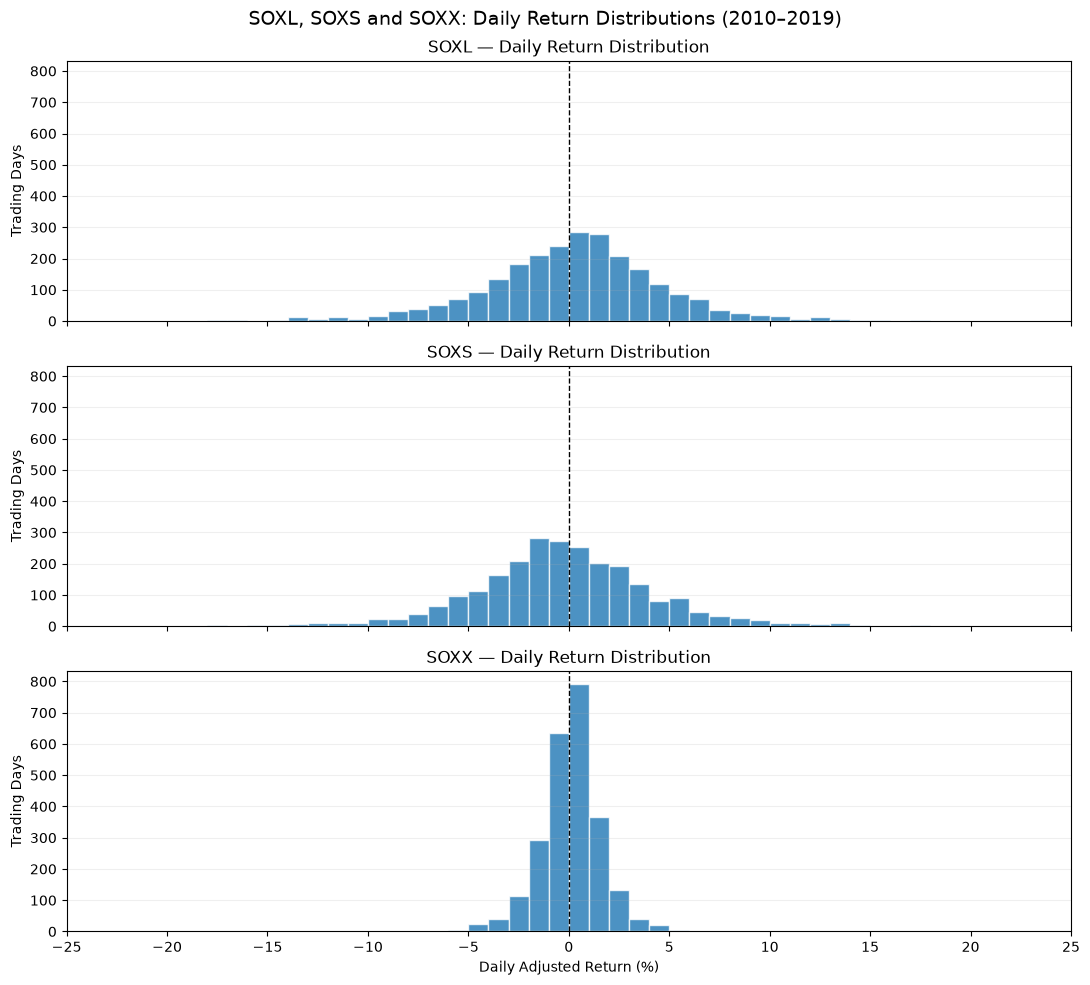

In [4]:

# ============================================================
# 2.2.3 — Daily Return Distribution Histograms
# Development period: 2010–2019
# ============================================================

# Create intervals of 1 percentage point.
bins = np.arange(-25, 26, 1)

# Create three charts stacked vertically.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(11, 10),
    sharex=True,
    sharey=True
)

# Generate one histogram for each ETF.
for ax, ticker in zip(axes, ["SOXL", "SOXS", "SOXX"]):

    returns = development_returns[f"{ticker} Return (%)"]

    ax.hist(
        returns,
        bins=bins,
        alpha=0.8,
        edgecolor="white"
    )

    # Dashed line marking zero return.
    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{ticker} — Daily Return Distribution")
    ax.set_ylabel("Trading Days")
    ax.grid(axis="y", alpha=0.2)

# Keep the scales consistent across charts.
axes[-1].set_xlim(-25, 25)
axes[-1].set_xticks(np.arange(-25, 26, 5))
axes[-1].set_xlabel("Daily Adjusted Return (%)")

fig.suptitle(
    "SOXL, SOXS and SOXX: Daily Return Distributions (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.2.4 — Findings from Daily Return Distributions

#### 1. SOXL and SOXS Had Wider Return Distributions

The histograms show that SOXL and SOXS experienced a wider range of daily percentage returns than SOXX during 2010–2019.

Both leveraged ETFs recorded daily standard deviations of approximately **4.51%**, compared with **1.49%** for SOXX.

This difference is visible in the charts. SOXL and SOXS have more observations farther from 0%, while SOXX's distribution is concentrated closer to zero.

#### 2. Large Daily Gains and Losses Occurred in Both Leveraged ETFs

The historical extremes were:

| ETF | Worst Daily Return | Best Daily Return |
|---|---:|---:|
| SOXL | -20.72% | +17.48% |
| SOXS | -17.19% | +20.65% |
| SOXX | -6.89% | +6.00% |

These values show that the leveraged ETFs experienced substantially larger single-day movements in both directions.

The histograms also show relatively few observations far from zero. However, the extreme observations remain important because a small number of large losses can have a significant impact on investment performance.

#### 3. SOXX Returns Were More Concentrated Near Zero

SOXX's histogram has a noticeably taller central peak and a narrower spread.

This is consistent with its lower standard deviation.

The histogram suggests that large daily percentage movements were less common for SOXX than for the leveraged ETFs in the development period.

#### 4. Historical Distributions Are Not Forecasts

These charts describe observed daily returns from 2010–2019.

They do not tell us when a large loss will happen again or whether the same distribution will continue in the future.

A visual comparison also cannot establish whether returns follow a normal distribution or whether the ETFs have statistically heavier tails after accounting for their different volatility levels.

#### Research Implication

The results support investigating SOXL's historical downside risk more closely.

The next step is to examine how frequently large daily losses occurred, before moving into rolling volatility and volatility clustering.

All observations remain restricted to the development period.



### 2.2.5 — Frequency of Large Daily Losses

#### Objective

Measure how often SOXL, SOXS, and SOXX experienced large single-day losses during the 2010–2019 development period.

The histograms showed that leveraged ETFs had wider daily-return distributions. We now want to quantify how frequently substantial losses occurred.

#### What Is a Loss Threshold?

A loss threshold is a specified percentage decline.

We will examine three descriptive thresholds:

- **-3%:** A daily loss of at least 3%
- **-5%:** A daily loss of at least 5%
- **-10%:** A daily loss of at least 10%

For example, if SOXL recorded a return of -6%, that day would count toward the -3% and -5% thresholds, but not the -10% threshold.

These categories overlap. They should not be added together.

#### Calculating Historical Loss Frequency

$$
\text{Loss Frequency (\%)} =
\frac{\text{Number of days meeting the loss threshold}}
{\text{Total valid trading days}} \times 100
$$

For example, suppose an ETF experienced a loss of at least 5% on 50 out of 1,000 trading days.

$$
\frac{50}{1000} \times 100 = 5\%
$$

This means the specified loss occurred on 5% of the observed trading days.

#### Important Limitation

These thresholds compare absolute percentage losses, not losses relative to each ETF's typical volatility.

Because SOXL and SOXS are leveraged, larger daily changes are expected. A higher loss frequency at a fixed threshold does not automatically prove that their standardized return distributions have heavier tails.

These are historical frequencies, not forecasts of future loss probabilities.


In [5]:

# ============================================================
# 2.2.5 — Frequency of Large Daily Losses (2010–2019)
# ============================================================

# Loss magnitudes expressed in percentage points.
loss_thresholds = [3, 5, 10]

loss_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Use only valid development-period daily returns.
    returns = development_returns[f"{ticker} Return (%)"]

    for threshold in loss_thresholds:

        # Count days with a return at or below the negative threshold.
        loss_count = (returns <= -threshold).sum()

        # Divide by the total number of valid observations.
        loss_percent = (loss_count / returns.count()) * 100

        loss_rows.append({
            "ETF": ticker,
            "Loss Threshold": f"≤ -{threshold}%",
            "Days": int(loss_count),
            "Total Days": int(returns.count()),
            "Frequency (%)": loss_percent
        })

# Build the comparison table.
loss_frequency = pd.DataFrame(loss_rows)

print("Historical Daily Loss Frequencies — 2010–2019")
print("Thresholds are cumulative, not mutually exclusive.\n")

display(loss_frequency.round(2))


Historical Daily Loss Frequencies — 2010–2019
Thresholds are cumulative, not mutually exclusive.



,ETF,Loss Threshold,Days,Total Days,Frequency (%)
0,SOXL,≤ -3%,486,2469,19.68
1,SOXL,≤ -5%,261,2469,10.57
2,SOXL,≤ -10%,51,2469,2.07
3,SOXS,≤ -3%,577,2469,23.37
4,SOXS,≤ -5%,298,2469,12.07
5,SOXS,≤ -10%,50,2469,2.03
6,SOXX,≤ -3%,69,2469,2.79
7,SOXX,≤ -5%,7,2469,0.28
8,SOXX,≤ -10%,0,2469,0.00



### 2.2.6 — Findings from Large Daily Loss Frequencies

#### 1. Large Daily Losses Were More Frequent for Leveraged ETFs

During the 2010–2019 development period, SOXL recorded a daily loss of at least 5% on **261 trading days (10.57%)**.

SOXS experienced losses of this magnitude on **298 trading days (12.07%)**, compared with only **7 days (0.28%)** for SOXX.

These results show that large absolute percentage declines occurred much more frequently in the leveraged ETFs.

#### 2. Losses of 10% or More Were Uncommon but Present

At the -10% threshold:

| ETF | Trading Days | Historical Frequency |
|---|---:|---:|
| SOXL | 51 | 2.07% |
| SOXS | 50 | 2.03% |
| SOXX | 0 | 0.00% |

SOXL and SOXS had nearly identical frequencies of daily losses of at least 10%.

SOXX recorded no such losses during this development period. Its worst observed daily return was -6.89%.

A zero historical count does not mean that such an event cannot happen in the future.

#### 3. Loss Frequency and Loss Severity Are Different

Loss frequency tells us how often a decline of a specified magnitude occurred.

Loss severity tells us how large the decline was.

For example, SOXS experienced more daily losses of at least 5% than SOXL, but SOXL had the larger single-day maximum loss magnitude:

- SOXL: -20.72%
- SOXS: -17.19%

Both measures are necessary for understanding downside risk.

#### 4. Important Methodological Limitations

The thresholds of -3%, -5%, and -10% are descriptive comparison points. They are not optimized forecasting thresholds or finalized model targets.

The threshold categories overlap. A loss of 12% is included in all three categories.

The comparison uses absolute percentage losses. It does not establish whether one ETF has more extreme returns after adjusting for its typical volatility.

Early SOXX data include predecessor IGW history, which requires caution when making exact-benchmark comparisons.

The calculations use only 2010–2019 data and do not estimate future probabilities.

### Section 2.2 — Overall Conclusion

The descriptive statistics, histograms, and loss-frequency analysis consistently show that SOXL and SOXS experienced substantially larger daily percentage movements than SOXX during the development period.

For SOXL, daily losses of at least 5% occurred on 10.57% of observed trading days, while losses of at least 10% occurred on 2.07% of days.

These findings establish the historical frequency and magnitude of large daily losses, but do not explain when market conditions become more volatile.

**Next research question:** Does SOXL's volatility remain relatively stable over time, or do periods of unusually large daily movements tend to occur together?

Section 2.3 will investigate historical rolling volatility and volatility clustering.



## 2.3 — Historical Volatility and Volatility Clustering

### 2.3.1 — Understanding Rolling Volatility

#### Objective

Investigate how the historical daily volatility of SOXL, SOXS, and SOXX changed over time during the 2010–2019 development period.

Section 2.2 calculated one standard deviation for the entire development period.

We now calculate volatility repeatedly using shorter, moving windows of historical daily returns.

#### What Is Historical Realized Volatility?

Historical realized volatility describes how much observed returns fluctuated over a past period.

We estimate it using the sample standard deviation of daily percentage returns.

A higher standard deviation indicates greater variability in returns.

Volatility measures the size of both positive and negative movements. It does not distinguish gains from losses, and it is not itself a measure of maximum downside risk.

#### What Is Rolling Volatility?

Rolling volatility calculates the standard deviation of returns over a moving window.

For example, a **10-day rolling volatility** calculation uses the 10 most recent trading-day returns.

When the next trading day arrives, the window moves forward by one observation:

- Day 10: Calculate volatility using Days 1–10.
- Day 11: Calculate volatility using Days 2–11.
- Day 12: Calculate volatility using Days 3–12.

This produces a time series showing how market volatility changed.

#### Comparing 10-Day and 20-Day Windows

| Window | Interpretation |
|---|---|
| 10 trading days | More responsive to recent market changes |
| 20 trading days | Smoother measure of volatility over a longer period |

A 10-day window reacts more quickly to large daily movements. A 20-day window usually changes more gradually.

Neither window automatically provides a better forecast.

These window lengths are used for descriptive exploration, not selected through predictive model testing.

#### Mathematical Formula

The sample standard deviation of returns is:

$$
s = \sqrt{\frac{\sum_{i=1}^{n}(R_i-\bar{R})^2}{n-1}}
$$

Where:

- $s$ = historical volatility, measured as sample standard deviation
- $R_i$ = daily percentage return
- $\bar{R}$ = average percentage return within the window
- $n$ = number of trading-day returns in the window

#### Simple Example

Suppose an investment recorded three daily returns:

| Day | Return |
|---|---:|
| 1 | -2% |
| 2 | +1% |
| 3 | +4% |

The mean return is +1%.

The sample standard deviation is:

$$
s = \sqrt{\frac{(-2-1)^2+(1-1)^2+(4-1)^2}{3-1}}
$$

$$
s = \sqrt{\frac{18}{2}} = 3\%
$$

This example uses a three-day window to demonstrate the calculation. Our actual analysis will use 10-day and 20-day windows.

#### How Python Calculates Rolling Volatility

We use:

`returns.rolling(window=10, min_periods=10).std(ddof=1)`

- `rolling(window=10)` selects a moving window of 10 observations.
- `min_periods=10` requires all 10 returns before producing a value.
- `std()` calculates the standard deviation.
- `ddof=1` specifies the sample standard deviation, dividing by $n-1$.

Because returns are already expressed as percentages, the resulting volatility values are also expressed in percentage points.

We will **not annualize** these values in this section.

#### Why Are the First Rolling Values Missing?

The first 10-day rolling volatility value needs 10 daily returns.

Therefore, the first 9 rows will have missing 10-day volatility values.

Similarly, the first 19 rows will have missing 20-day volatility values.

This is expected. We will not fill them with invented values.

#### Research Restrictions

All calculations use the 2010–2019 development dataset.

Each rolling value uses the current and preceding trading-day returns, never future observations.

The results describe historical volatility and do not establish forecasting ability.


In [6]:

# ============================================================
# 2.3.1 — Calculate Historical Rolling Volatility
# Development period: 2010–2019
# ============================================================

# Create a separate working table.
# This preserves the existing daily-return dataset.
development_volatility = development_returns[
    ["Date"] + return_columns
].copy()

# Calculate 10-day and 20-day rolling volatility for each ETF.
for ticker in ["SOXL", "SOXS", "SOXX"]:

    returns = development_volatility[f"{ticker} Return (%)"]

    development_volatility[f"{ticker} Volatility 10d (%)"] = (
        returns.rolling(window=10, min_periods=10).std(ddof=1)
    )

    development_volatility[f"{ticker} Volatility 20d (%)"] = (
        returns.rolling(window=20, min_periods=20).std(ddof=1)
    )

# Check how many valid rolling values were calculated.
validation_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:
    for window in [10, 20]:

        column = f"{ticker} Volatility {window}d (%)"

        validation_rows.append({
            "ETF": ticker,
            "Window (Days)": window,
            "Valid Values": development_volatility[column].count(),
            "Expected Values": len(development_volatility) - window + 1,
            "First Valid Date": development_volatility.loc[
                development_volatility[column].notna(), "Date"
            ].min()
        })

rolling_validation = pd.DataFrame(validation_rows)

# Verify that the calculation produced the expected counts.
assert (
    rolling_validation["Valid Values"]
    == rolling_validation["Expected Values"]
).all()

# Verify that the analysis remains inside the development period.
assert development_volatility["Date"].max() <= pd.Timestamp("2019-12-31")

print("Rolling Volatility Validation — 2010–2019")
display(rolling_validation)

# Display the last five observations for SOXL.
print("\nSOXL — Last Five Rolling Volatility Observations")

display(
    development_volatility[
        [
            "Date",
            "SOXL Return (%)",
            "SOXL Volatility 10d (%)",
            "SOXL Volatility 20d (%)"
        ]
    ].tail(5).round(2)
)


Rolling Volatility Validation — 2010–2019


,ETF,Window (Days),Valid Values,Expected Values,First Valid Date
0,SOXL,10,2460,2460,2010-03-25
1,SOXL,20,2450,2450,2010-04-09
2,SOXS,10,2460,2460,2010-03-25
3,SOXS,20,2450,2450,2010-04-09
4,SOXX,10,2460,2460,2010-03-25
5,SOXX,20,2450,2450,2010-04-09



SOXL — Last Five Rolling Volatility Observations


,Date,SOXL Return (%),SOXL Volatility 10d (%),SOXL Volatility 20d (%)
2465,2019-12-24,0.74,2.99,3.40
2466,2019-12-26,0.38,2.66,3.35
2467,2019-12-27,-1.11,1.61,3.38
2468,2019-12-30,-2.10,1.69,3.32
2469,2019-12-31,0.67,1.54,3.06



### 2.3.2 — Visualizing SOXL Rolling Volatility

#### Objective

Visualize changes in SOXL's historical daily-return volatility throughout the 2010–2019 development period.

We will compare 10-day and 20-day rolling standard deviations to investigate whether volatility remained stable or changed over time.

#### How to Read the Chart

- **X-axis:** Trading date
- **Y-axis:** Rolling standard deviation of daily returns (%)
- **10-day line:** Volatility calculated from the most recent 10 trading-day returns
- **20-day line:** Volatility calculated from the most recent 20 trading-day returns

A high point indicates that daily returns varied substantially within the corresponding historical window.

A low point indicates that returns were relatively stable during that window.

Because the 10-day calculation uses fewer observations, it is generally more responsive to recent changes.

#### What Is Volatility Clustering?

Volatility clustering describes the tendency for periods of large return movements to occur near other periods of large movements.

In financial markets, periods of high volatility may persist for some time rather than appearing as isolated events.

We will first look for these patterns visually. Later in Section 2.3, we will examine return magnitudes more directly.

Rolling-volatility charts are descriptive. Overlapping windows can create smooth, persistent-looking patterns by construction, so the chart alone cannot prove volatility clustering or predictive ability.

#### Research Restrictions

This visualization uses only 2010–2019 development observations.

The lines represent historical daily-return standard deviations, not annualized volatility.

No future returns are used in the rolling calculations.


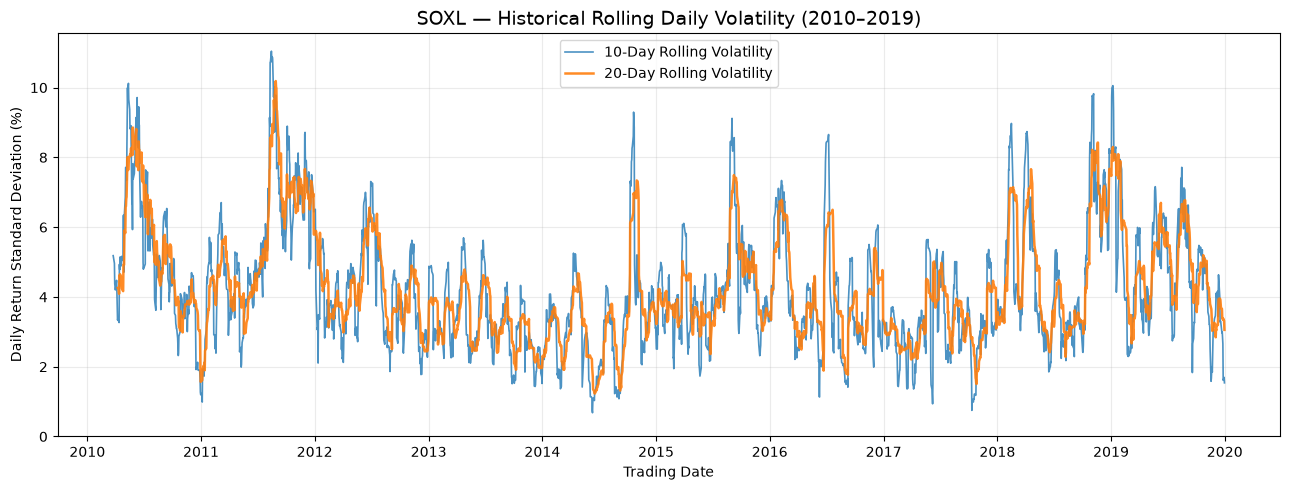

In [7]:

# ============================================================
# 2.3.2 — SOXL Historical Rolling Volatility Chart
# Development period: 2010–2019
# ============================================================

# Create a single figure for comparing the two windows.
fig, ax = plt.subplots(figsize=(13, 5))

# Plot the 10-day rolling volatility.
ax.plot(
    development_volatility["Date"],
    development_volatility["SOXL Volatility 10d (%)"],
    label="10-Day Rolling Volatility",
    linewidth=1.2,
    alpha=0.8
)

# Plot the 20-day rolling volatility.
ax.plot(
    development_volatility["Date"],
    development_volatility["SOXL Volatility 20d (%)"],
    label="20-Day Rolling Volatility",
    linewidth=1.8,
    alpha=0.9
)

# Chart title and axis labels.
ax.set_title(
    "SOXL — Historical Rolling Daily Volatility (2010–2019)",
    fontsize=14
)

ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Return Standard Deviation (%)")

# Volatility cannot be negative.
ax.set_ylim(bottom=0)

# Add legend and grid.
ax.legend()
ax.grid(alpha=0.25)

# Improve layout and display.
plt.tight_layout()
plt.show()



#### Findings from SOXL Rolling Volatility

**1. SOXL's Historical Volatility Was Not Constant**

SOXL's rolling daily-return standard deviation changed substantially throughout 2010–2019.

The chart shows periods of elevated volatility around 2010–2011, parts of 2015, and 2018–2019. Other periods experienced considerably smaller daily fluctuations.

The overall development-period standard deviation of 4.51% therefore hides substantial variation over time.

**2. The 10-Day Window Responded More Quickly**

The 10-day volatility line has sharper peaks and declines than the 20-day line.

This occurs because the shorter calculation responds more strongly when a large daily return enters or leaves its rolling window.

The 20-day measure is generally smoother because it incorporates more observations.

**3. Elevated Volatility Sometimes Persisted**

Some periods show high volatility remaining elevated across multiple trading days rather than disappearing immediately.

This pattern is consistent with the possibility of volatility clustering.

However, consecutive rolling windows share most of their observations. Their overlapping structure can produce persistent-looking movements even without an independently established clustering relationship.

We therefore cannot use this chart alone as proof of volatility clustering.

**4. Implications for Downside Risk Research**

A single long-term standard deviation does not adequately describe how SOXL's historical risk conditions varied.

Periods with higher realized volatility may contain larger daily gains and losses, but volatility itself does not identify the direction of the next return.

Later analyses will examine whether historical volatility conditions contain useful information about subsequent downside risk.

No predictive conclusion is made at this stage.

#### Next Investigation

Compare rolling volatility across SOXL, SOXS, and SOXX, then examine whether large absolute returns tend to occur close together.



### 2.3.3 — Comparing Historical Volatility Across ETFs

#### Objective

Compare the 20-day rolling volatility of SOXL, SOXS, and SOXX during the 2010–2019 development period.

Section 2.3.2 showed that SOXL's volatility changed substantially over time.

We now want to investigate whether similar periods of elevated volatility appeared in the inverse leveraged ETF (SOXS) and the unleveraged semiconductor ETF (SOXX).

#### Why Compare the Three ETFs?

The three ETFs provide different types of semiconductor-sector exposure:

| ETF | Exposure |
|---|---|
| SOXL | Daily leveraged long semiconductor exposure |
| SOXS | Daily leveraged inverse semiconductor exposure |
| SOXX | Unleveraged semiconductor-sector ETF |

SOXL and SOXS historically targeted approximately +3× and -3× daily exposure to their respective underlying benchmarks.

However, historical benchmark definitions and tracking differences must be considered. SOXX is a useful comparison ETF, not necessarily the exact benchmark underlying SOXL and SOXS throughout the period.

#### Why Use 20-Day Volatility?

We have already calculated both 10-day and 20-day rolling volatility.

For this comparison, we will focus on the 20-day measure because it produces a somewhat smoother view of historical volatility conditions.

Each value uses the current and preceding 19 trading-day returns.

The calculation remains:

`returns.rolling(window=20, min_periods=20).std(ddof=1)`

All values represent the standard deviation of daily percentage returns. They are **not annualized**.

#### Why Use the Same Vertical Scale?

All three charts will share the same y-axis.

If one chart uses a scale of 0–5% and another uses 0–15%, their movements may appear equally large even when their actual volatility levels differ substantially.

Using matching scales makes the comparison more meaningful.

#### Questions to Investigate

1. Did SOXL and SOXS experience elevated volatility at similar times?
2. Did SOXX show increases in volatility during those same periods?
3. Were the leveraged ETFs consistently more volatile than SOXX?
4. Did periods of elevated volatility affect all three ETFs equally?

#### Interpretation Limitations

Similar volatility patterns do not prove that the ETFs tracked the same benchmark or had identical risks.

The charts also cannot establish whether volatility is useful for forecasting future losses.

All calculations remain restricted to the 2010–2019 development period.


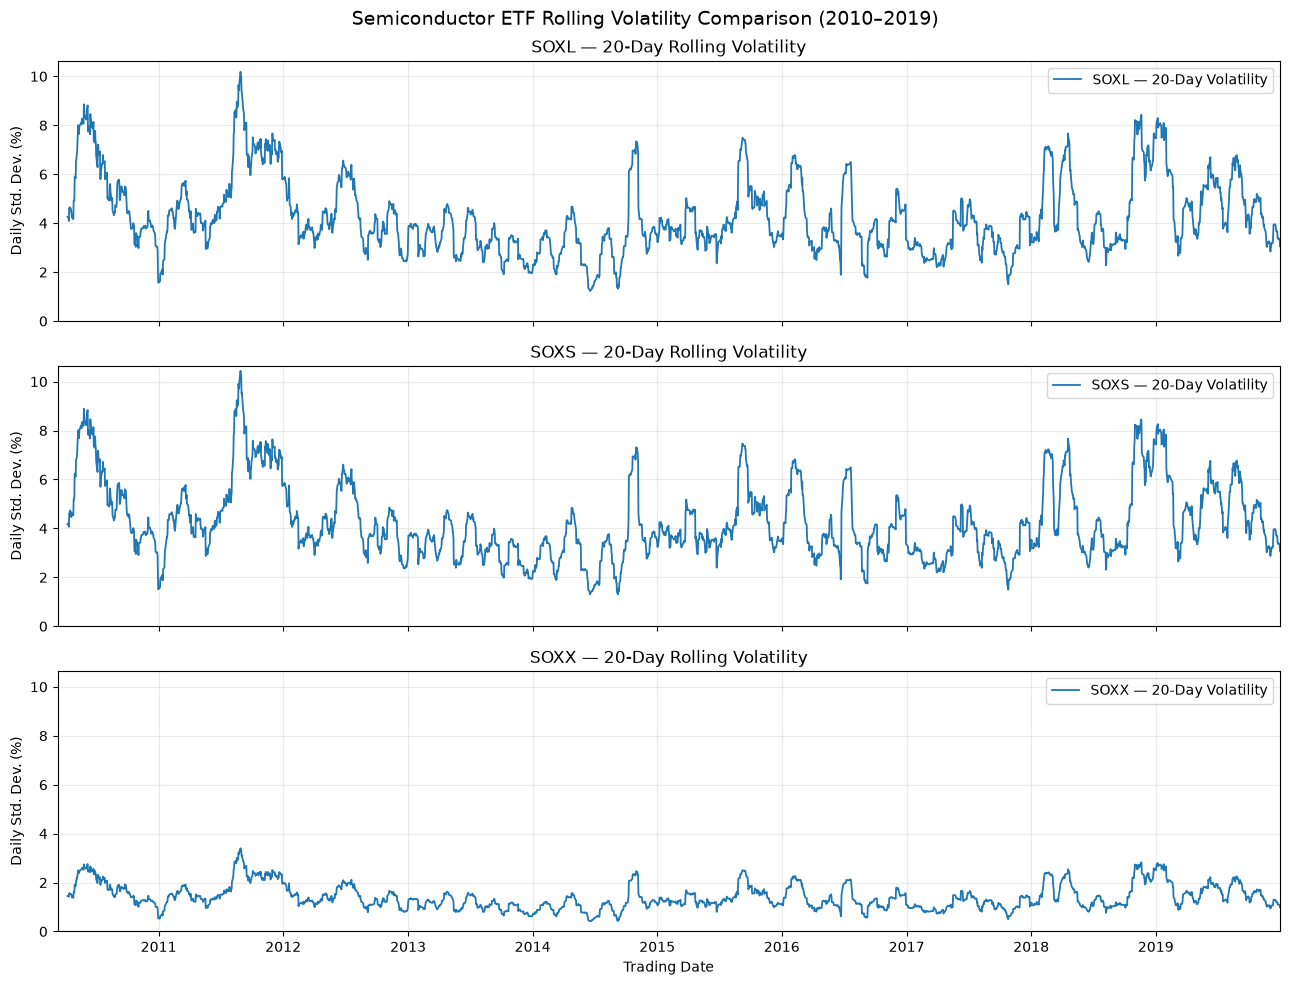

In [8]:

# ============================================================
# 2.3.3 — Compare 20-Day Rolling Volatility Across ETFs
# Development period: 2010–2019
# ============================================================

# Create three vertically stacked charts.
# sharex=True and sharey=True keep the axes consistent.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 10),
    sharex=True,
    sharey=True
)

# Generate one chart for each ETF.
for ax, ticker in zip(axes, ["SOXL", "SOXS", "SOXX"]):

    volatility_column = f"{ticker} Volatility 20d (%)"

    ax.plot(
        development_volatility["Date"],
        development_volatility[volatility_column],
        linewidth=1.3,
        label=f"{ticker} — 20-Day Volatility"
    )

    ax.set_title(f"{ticker} — 20-Day Rolling Volatility")
    ax.set_ylabel("Daily Std. Dev. (%)")
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

# Restrict the horizontal axis to our development period.
axes[-1].set_xlim(
    pd.Timestamp("2010-03-11"),
    pd.Timestamp("2019-12-31")
)

axes[-1].set_xlabel("Trading Date")

fig.suptitle(
    "Semiconductor ETF Rolling Volatility Comparison (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



#### Findings from the ETF Rolling Volatility Comparison

**1. SOXL and SOXS Had Similar Volatility Patterns**

The 20-day rolling volatility charts for SOXL and SOXS follow very similar paths throughout the 2010–2019 development period.

Their major volatility increases and decreases occurred at approximately the same times.

Although SOXL and SOXS provide opposite daily market exposure, standard deviation measures the magnitude of return fluctuations rather than their direction.

This helps explain why their historical volatility patterns were similar.

Their volatility is not necessarily identical because of tracking differences, fees, and other fund-specific effects.

**2. SOXX Had Substantially Lower Volatility**

SOXX's 20-day rolling volatility remained considerably lower than the leveraged ETFs' volatility across most of the development period.

During a prominent period of elevated volatility in 2011, SOXL and SOXS reached approximately 10% daily rolling standard deviation, compared with roughly 3–3.5% for SOXX.

These values are approximate readings from the charts.

The shared vertical scale makes the difference in volatility magnitude visible.

**3. Elevated Volatility Occurred at Similar Times**

All three ETFs showed notable volatility increases during parts of 2010–2011, 2015, and 2018–2019.

The timing suggests that semiconductor-sector market conditions may contribute to periods of elevated volatility across these ETFs.

However, similar timing does not establish a causal relationship or prove that one ETF's volatility can forecast another ETF's future returns.

**4. Leverage Amplified the Magnitude of Daily Fluctuations**

The leveraged ETFs generally experienced much larger rolling standard deviations than SOXX.

This is consistent with their daily leveraged exposure and the earlier full-period standard deviation comparison:

- SOXL: 4.51%
- SOXS: 4.51%
- SOXX: 1.49%

These are full-period daily standard deviations, not averages of the 20-day rolling estimates.

**5. Limitations**

Rolling windows overlap, so persistent-looking movements in the charts cannot independently establish volatility clustering.

SOXX is a sector comparison ETF and was not necessarily the exact underlying benchmark for SOXL or SOXS.

Early SOXX observations also include predecessor IGW history.

The charts describe historical relationships using only 2010–2019 observations. They do not establish predictive accuracy.

#### Next Investigation

Examine volatility clustering more directly by studying whether large absolute daily returns tend to occur near other large absolute returns.



### 2.3.4 — Investigating Volatility Clustering

#### Objective

Investigate whether large daily return movements tend to occur near other large movements during the 2010–2019 development period.

Our rolling-volatility charts showed periods of elevated volatility, but overlapping rolling windows can make volatility appear persistent.

We will now examine the daily returns directly.

#### What Is Volatility Clustering?

Volatility clustering describes a tendency for large return movements to occur near other large movements, and small movements to occur near other small movements.

For example, after an unusually large daily price movement, the market may continue experiencing substantial fluctuations over subsequent days.

Importantly, volatility clustering concerns the **magnitude of returns**, not necessarily their direction.

A large loss followed by a large gain can still represent a period of elevated volatility.

#### What Are Absolute Returns?

The absolute value removes the positive or negative sign from a number.

For example:

| Daily Return | Absolute Return |
|---|---:|
| +5% | 5% |
| -5% | 5% |
| +1% | 1% |
| -8% | 8% |

Mathematically:

$$
A_t = |R_t|
$$

Where:

- $R_t$ = daily percentage return
- $A_t$ = absolute daily percentage return

Absolute returns provide a simple way to measure the size of daily movements without distinguishing gains from losses.

They are not the same as rolling standard deviation, but both can provide information about historical volatility.

#### What Is Autocorrelation?

Autocorrelation measures the statistical relationship between a time series and an earlier version of itself.

For this investigation, we compare today's absolute return with the absolute return from previous trading days.

For example:

- **Lag 1:** Today's absolute return versus the previous trading day's absolute return.
- **Lag 5:** Today's absolute return versus the absolute return five trading days earlier.
- **Lag 10:** Today's absolute return versus ten trading days earlier.
- **Lag 20:** Today's absolute return versus twenty trading days earlier.

The autocorrelation coefficient ranges from -1 to +1.

| Value | Interpretation |
|---|---|
| Positive | Larger movements tend to be associated with larger earlier movements |
| Near zero | Little linear relationship at that lag |
| Negative | Larger movements tend to be associated with smaller earlier movements |

#### Simple Example

Suppose an ETF experiences the following daily returns:

| Day | Daily Return | Absolute Return |
|---|---:|---:|
| Monday | -6% | 6% |
| Tuesday | +5% | 5% |
| Wednesday | -7% | 7% |
| Thursday | +1% | 1% |
| Friday | -0.5% | 0.5% |

The first three days have large absolute movements, despite having different return directions.

This illustrates the type of pattern we want to investigate.

Five observations are not enough to establish a reliable statistical relationship. Our actual analysis uses the development-period return series.

#### How Python Calculates Autocorrelation

We will use:

`returns.abs().autocorr(lag=1)`

- `.abs()` converts each daily return into its absolute magnitude.
- `.autocorr()` calculates the correlation between the series and a shifted copy.
- `lag=1` compares observations separated by one trading day.

We will repeat this calculation for lags 1, 5, 10, and 20.

We will also calculate lag-1 autocorrelation of the original signed returns for comparison.

#### Interpretation Limitations

Positive autocorrelation in absolute returns is consistent with volatility clustering, but it does not establish causation or guarantee future predictability.

A correlation coefficient is a descriptive statistical measure. We are not conducting a formal significance test or estimating a forecasting model in this section.

All calculations use only the 2010–2019 development period.


In [9]:

# ============================================================
# 2.3.4 — Absolute Return Autocorrelation
# Development period: 2010–2019
# ============================================================

# Lags represent the number of trading days between returns.
lags = [1, 5, 10, 20]

autocorrelation_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Retrieve daily percentage returns.
    returns = development_returns[f"{ticker} Return (%)"]

    # Convert returns to absolute magnitudes.
    absolute_returns = returns.abs()

    for lag in lags:

        # Compare absolute returns separated by this many days.
        correlation = absolute_returns.autocorr(lag=lag)

        autocorrelation_rows.append({
            "ETF": ticker,
            "Lag (Trading Days)": lag,
            "Observations Paired": len(returns) - lag,
            "Absolute Return Autocorrelation": correlation
        })

# Combine the results into one table.
autocorrelation_results = pd.DataFrame(
    autocorrelation_rows
)

print("Absolute Return Autocorrelation — 2010–2019")
display(autocorrelation_results.round(4))

# Compare signed-return and absolute-return autocorrelation.
comparison_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    returns = development_returns[f"{ticker} Return (%)"]

    comparison_rows.append({
        "ETF": ticker,
        "Signed Return Lag-1": returns.autocorr(lag=1),
        "Absolute Return Lag-1": returns.abs().autocorr(lag=1)
    })

autocorrelation_comparison = pd.DataFrame(
    comparison_rows
).set_index("ETF")

print("\nSigned vs. Absolute Return Autocorrelation — Lag 1")
display(autocorrelation_comparison.round(4))


Absolute Return Autocorrelation — 2010–2019


,ETF,Lag (Trading Days),Observations Paired,Absolute Return Autocorrelation
0,SOXL,1,2468,0.1164
1,SOXL,5,2464,0.1082
2,SOXL,10,2459,0.1413
3,SOXL,20,2449,0.0511
4,SOXS,1,2468,0.1148
5,SOXS,5,2464,0.1113
6,SOXS,10,2459,0.1415
7,SOXS,20,2449,0.0541
8,SOXX,1,2468,0.1068
9,SOXX,5,2464,0.0982



Signed vs. Absolute Return Autocorrelation — Lag 1


,Signed Return Lag-1,Absolute Return Lag-1
ETF,,
SOXL,-0.0123,0.1164
SOXS,-0.0180,0.1148
SOXX,-0.0091,0.1068



#### Findings from Absolute-Return Autocorrelation

**1. Positive Autocorrelation Was Observed Across All Three ETFs**

All three ETFs had positive absolute-return autocorrelation at lags 1, 5, 10, and 20 trading days.

For SOXL, the observed coefficients were:

| Lag (Trading Days) | Absolute-Return Autocorrelation |
|---|---:|
| 1 | 0.1164 |
| 5 | 0.1082 |
| 10 | 0.1413 |
| 20 | 0.0511 |

These positive correlations are consistent with the tendency for larger daily movements to occur near other larger movements.

However, the coefficients are relatively small. We should not interpret them as evidence of a strong or guaranteed relationship.

**2. Return Magnitude Showed More Persistence Than Return Direction**

SOXL's lag-1 signed-return autocorrelation was **-0.0123**, compared with **+0.1164** for absolute returns.

SOXS and SOXX showed a similar difference.

This distinction suggests that the magnitude of daily movements had a stronger historical linear association with earlier magnitudes than signed returns had with earlier signed returns.

In other words, large market movements may occur near one another even when their direction is difficult to anticipate.

**3. Similar Patterns Appeared Across All Three ETFs**

The lag-1 absolute-return autocorrelations were:

- SOXL: 0.1164
- SOXS: 0.1148
- SOXX: 0.1068

All three ETFs had positive coefficients of similar magnitude.

This suggests that the observed persistence in return magnitudes was not unique to SOXL or SOXS.

The similarities are consistent with their shared exposure to semiconductor-sector market conditions, but do not establish a causal relationship.

**4. Autocorrelation Varied Across Lags**

SOXL's absolute-return autocorrelation was highest among the selected lags at 10 trading days (0.1413).

It was lower at 20 trading days (0.0511).

The pattern did not decline consistently across every lag, so we cannot describe it as a smooth decay.

These results describe associations at four selected lags, not the complete autocorrelation structure.

**5. Limitations and Research Implications**

Positive autocorrelation in absolute returns provides descriptive evidence consistent with volatility clustering.

However:

- Correlation does not establish causation.
- The coefficients do not represent probabilities of future losses.
- No formal statistical significance test has been conducted.
- The analysis does not establish that these relationships remain stable outside 2010–2019.
- No forecasting model has been trained or evaluated.

The findings support further investigation of historical volatility conditions as potential inputs to later downside-risk models.

Predictive usefulness must be assessed separately using properly lagged features and out-of-sample evaluation.

#### Next Step

Visualize the absolute-return autocorrelation coefficients to compare their magnitudes across the three ETFs and four trading-day lags.



### 2.3.5 — Visualizing Absolute-Return Autocorrelation

#### Objective

Compare the absolute-return autocorrelation coefficients of SOXL, SOXS, and SOXX at lags of 1, 5, 10, and 20 trading days.

The previous calculations showed positive autocorrelation across all three ETFs.

We will use a grouped bar chart to visualize these relationships.

#### How to Read the Chart

- **X-axis:** Number of trading days separating the observations.
- **Y-axis:** Absolute-return autocorrelation coefficient.
- **Grouped bars:** Compare SOXL, SOXS, and SOXX at each lag.
- **Higher positive values:** Stronger positive linear association between absolute returns at that lag.
- **Values near zero:** Weaker linear association.

For example, SOXL's lag-1 coefficient was 0.1164.

This describes a weak positive historical correlation between today's absolute return and the previous trading day's absolute return.

It does **not** mean there is an 11.64% probability of a large movement tomorrow.

#### What We Want to Investigate

1. How similar are the autocorrelation coefficients across the three ETFs?
2. Which of the selected lags has the highest observed coefficient?
3. Do the coefficients consistently decrease as the lag increases?
4. What does this tell us about historical volatility clustering?

#### Important Limitation

The chart compares descriptive correlation coefficients.

It does not test statistical significance, demonstrate causation, or establish forecasting accuracy.

Only 2010–2019 development data are used.


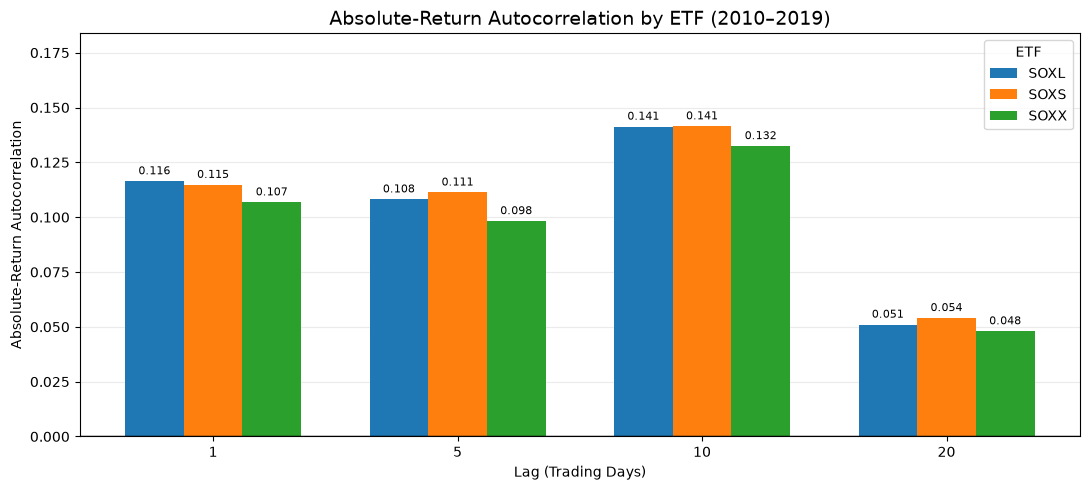

In [10]:

# ============================================================
# 2.3.5 — Visualize Absolute-Return Autocorrelation
# Development period: 2010–2019
# ============================================================

# Trading-day lags already examined.
lags = [1, 5, 10, 20]

# Positions of the four groups on the horizontal axis.
x = np.arange(len(lags))

# Width of each ETF's bar.
bar_width = 0.24

fig, ax = plt.subplots(figsize=(11, 5))

# Plot the three ETFs side by side at each lag.
for i, ticker in enumerate(["SOXL", "SOXS", "SOXX"]):

    # Retrieve the four coefficients in the correct lag order.
    values = (
        autocorrelation_results.loc[
            autocorrelation_results["ETF"] == ticker
        ]
        .set_index("Lag (Trading Days)")
        .loc[lags, "Absolute Return Autocorrelation"]
        .to_numpy()
    )

    # Offset the bars so they appear next to one another.
    positions = x + (i - 1) * bar_width

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=ticker
    )

    # Display the coefficient above each bar.
    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

# Reference line representing zero correlation.
ax.axhline(0, color="black", linewidth=1)

# Axis labels and title.
ax.set_xticks(x)
ax.set_xticklabels(lags)

ax.set_xlabel("Lag (Trading Days)")
ax.set_ylabel("Absolute-Return Autocorrelation")

ax.set_title(
    "Absolute-Return Autocorrelation by ETF (2010–2019)",
    fontsize=14
)

# Give labels some room above the tallest bar.
ax.set_ylim(
    bottom=0,
    top=autocorrelation_results[
        "Absolute Return Autocorrelation"
    ].max() * 1.3
)

ax.legend(title="ETF")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 2.3.6 — Historical Volatility: Overall Findings

#### Summary of Results

The 2010–2019 development-period analysis provides three main findings.

**1. Historical volatility changed considerably over time.**

SOXL's 10-day and 20-day rolling standard deviations showed repeated periods of elevated and reduced volatility.

A single standard deviation calculated over the entire development period does not capture these changes in market conditions.

**2. Leveraged ETFs experienced substantially greater volatility.**

SOXL and SOXS had similar 20-day rolling volatility patterns, with much larger fluctuations than SOXX.

All three ETFs experienced elevated volatility at approximately the same times, suggesting shared exposure to changing semiconductor-sector conditions.

This comparison is descriptive. SOXX was not necessarily the exact underlying benchmark for the leveraged ETFs throughout the period.

**3. Absolute returns showed positive autocorrelation.**

SOXL's absolute-return autocorrelation was:

- Lag 1: 0.1164
- Lag 5: 0.1082
- Lag 10: 0.1413
- Lag 20: 0.0511

SOXS and SOXX showed similar patterns.

The grouped bar chart confirms that all three ETFs had positive autocorrelation at the selected lags, with the strongest observed association at lag 10.

These correlations are relatively weak but consistent with historical volatility clustering.

#### Why This Matters for Our Research

Our project investigates whether semiconductor market conditions and historical volatility can help estimate near-term SOXL downside risk.

The analysis establishes that SOXL's historical volatility was not constant and that daily return magnitudes showed some persistence.

This gives us a reason to investigate historical volatility as a possible risk-related variable in later stages.

However, we have **not established that volatility predicts future SOXL losses**.

That question requires properly lagged information, defined downside outcomes, and out-of-sample evaluation.

#### Limitations

- Rolling volatility describes past returns and cannot directly identify the direction of future price movements.
- Overlapping rolling windows can produce apparent persistence.
- Absolute-return autocorrelation does not establish causation or predictive accuracy.
- No formal autocorrelation significance tests have been conducted.
- The analysis uses only 2010–2019 development observations.
- Findings may not remain stable during later market periods.

#### Section 2.3 Conclusion

The historical evidence shows that SOXL experienced changing volatility conditions and positive autocorrelation in absolute daily returns.

These results support further research into downside-risk estimation without demonstrating forecasting ability.

**Next: Section 2.4 — Daily Leverage Relationships**

We will investigate how SOXL's and SOXS's daily returns relate to semiconductor-sector movements, including differences from their approximate +3x and -3x daily leverage objectives.



## 2.4 — Daily Leverage Relationships

### 2.4.1 — Understanding Daily Leveraged Exposure

#### Objective

Investigate the contemporaneous relationships between the daily adjusted returns of SOXL, SOXS, and SOXX during the development period.

We want to understand how leveraged and inverse semiconductor ETFs move relative to an unleveraged semiconductor-sector comparison.

#### What Is a Leveraged ETF?

A leveraged exchange-traded fund aims to produce a specified multiple of its underlying benchmark's **daily return**.

SOXL and SOXS are designed around opposite daily leveraged exposures:

| ETF | Daily Exposure Objective |
|---|---|
| SOXL | Approximately +3× its underlying benchmark's daily return |
| SOXS | Approximately -3× its underlying benchmark's daily return |
| SOXX | Unleveraged semiconductor-sector exposure |

The +3× and -3× objectives apply to daily benchmark performance, not necessarily returns over several days, months, or years.

#### Worked Example

Suppose an underlying semiconductor benchmark rises by 2% in one trading day.

Ignoring fees and tracking differences:

$$
R_{\text{SOXL}} \approx 3 \times 2\% = +6\%
$$

$$
R_{\text{SOXS}} \approx -3 \times 2\% = -6\%
$$

If the benchmark instead falls by 2%, the illustrative daily returns reverse:

- SOXL: approximately -6%
- SOXS: approximately +6%

These examples describe intended daily leverage, not guaranteed realized ETF returns.

#### Why Isn't Daily Leverage Always Exactly 3×?

Actual ETF returns can differ from a simple leverage calculation because of:

- Fund expenses and financing costs
- Derivative pricing and portfolio management
- Benchmark tracking differences
- Differences in market closing prices and adjusted-price methodology
- Historical changes in the benchmark or fund structure

Daily leverage also does not imply that multi-day returns are exactly three times the benchmark's cumulative return.

We will investigate compounding separately in Section 2.5.

#### Important Benchmark Limitation

SOXX is useful as an unleveraged semiconductor-sector comparison, but it is not necessarily the exact benchmark underlying SOXL or SOXS.

Additionally, the historical SOXX dataset includes predecessor IGW history before October 15, 2010.

For the initial cross-ETF comparison, we will begin on **October 18, 2010**, the next trading day after that transition, so each compared return uses dates after the predecessor period.

This restriction does not make SOXX an exact leveraged-fund benchmark. It only avoids mixing the predecessor period into this particular comparison.

#### What Is Correlation?

Correlation measures how strongly two variables move together in a linear relationship.

The Pearson correlation coefficient ranges from -1 to +1.

| Correlation | Interpretation |
|---|---|
| Near +1 | Strong positive relationship |
| Near 0 | Weak linear relationship |
| Near -1 | Strong negative relationship |

For example, a strong positive correlation between SOXL and SOXX would mean their daily returns generally moved together.

A strong negative correlation between SOXS and SOXX would mean their daily returns generally moved in opposite directions.

**Correlation does not measure the leverage multiple.**

Two return series can have a correlation near +1 even if one moves approximately three times as much as the other.

#### Research Restrictions

This analysis:

- Uses adjusted daily percentage returns.
- Includes only development-period observations through December 31, 2019.
- Compares returns from matching trading dates.
- Treats SOXX as a sector comparison, not an exact benchmark.
- Does not estimate forecasting models or evaluate future returns.


In [11]:

# ============================================================
# 2.4.1 — Same-Day ETF Return Relationships
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Use dates after the SOXX predecessor-history transition.
leverage_comparison = development_returns.loc[
    development_returns["Date"] >= pd.Timestamp("2010-10-18"),
    ["Date"] + return_columns
].copy()

# Confirm that we have a clean, aligned comparison dataset.
assert not leverage_comparison.empty
assert leverage_comparison["Date"].is_unique
assert leverage_comparison[return_columns].notna().all().all()

assert leverage_comparison["Date"].min() >= pd.Timestamp("2010-10-18")
assert leverage_comparison["Date"].max() <= pd.Timestamp("2019-12-31")

print("Daily Leverage Comparison — Data Validation")
print("First date:", leverage_comparison["Date"].min().date())
print("Last date:", leverage_comparison["Date"].max().date())
print("Matched trading days:", len(leverage_comparison))

# Calculate same-day Pearson return correlations.
correlation_matrix = leverage_comparison[
    return_columns
].corr(method="pearson")

# Make labels easier to read.
correlation_matrix.index = ["SOXL", "SOXS", "SOXX"]
correlation_matrix.columns = ["SOXL", "SOXS", "SOXX"]

print("\nSame-Day Daily Return Correlations")
display(correlation_matrix.round(4))


Daily Leverage Comparison — Data Validation
First date: 2010-10-18
Last date: 2019-12-31
Matched trading days: 2317

Same-Day Daily Return Correlations


,SOXL,SOXS,SOXX
SOXL,1.0000,-0.9987,0.9980
SOXS,-0.9987,1.0000,-0.9979
SOXX,0.9980,-0.9979,1.0000



### 2.4.2 — Findings from Daily Return Correlations

#### 1. SOXL and SOXX Had a Strong Positive Relationship

The Pearson correlation between SOXL and SOXX daily adjusted returns was **+0.9980** across 2,317 matched trading days.

This indicates an extremely strong positive linear relationship during the October 18, 2010–December 31, 2019 comparison period.

Their returns generally moved in the same direction, consistent with their shared exposure to semiconductor-sector movements.

#### 2. SOXS Moved in the Opposite Direction

SOXS had a daily-return correlation of **-0.9979** with SOXX.

Its correlation with SOXL was **-0.9987**.

These strong negative relationships are consistent with SOXS providing inverse daily semiconductor exposure.

The relationships are not perfectly negative, meaning the daily returns were not exact mirror images.

#### 3. Correlation Does Not Measure the Leverage Multiple

A correlation close to +1 or -1 does not tell us whether an ETF moves by 1×, 2×, or 3× another investment's daily return.

For example, the following returns have a perfect positive correlation:

| Trading Day | ETF A | ETF B |
|---|---:|---:|
| Day 1 | +1% | +3% |
| Day 2 | -2% | -6% |
| Day 3 | +2% | +6% |

ETF B moves by three times ETF A's return, but their correlation is still +1.

To investigate leverage magnitude, we need to examine how much SOXL and SOXS move for each percentage-point change in SOXX.

We will use daily-return scatterplots and fitted descriptive relationships in the next investigation.

#### 4. Benchmark and Methodological Limitations

The comparison includes **2,317 matched trading days** from October 18, 2010 through December 31, 2019.

The start date excludes the SOXX predecessor IGW period and avoids calculating a return across the transition date.

However, SOXX is not necessarily the exact underlying benchmark for SOXL or SOXS.

High correlations do not establish exact benchmark tracking, daily leverage accuracy, or causation.

These are **same-day relationships**. They do not demonstrate that SOXX returns can predict SOXL or SOXS returns in advance.

#### Initial Conclusion

The three ETFs showed extremely strong contemporaneous return relationships during the development period.

Their correlation signs were consistent with their respective long and inverse semiconductor exposures.

The next step is to investigate the magnitude of those movements and compare observed daily returns with illustrative +3x and -3x relationships.



### 2.4.3 — Measuring Daily Leverage Using Regression Slopes

#### Objective

Estimate the historical same-day relationship between SOXX daily returns and the daily returns of SOXL and SOXS.

Our previous correlation analysis showed extremely strong relationships between the ETFs.

We now want to measure the magnitude of those relationships.

#### What Is a Regression Slope?

A regression slope measures how much one variable tends to change when another variable increases by one unit.

For example, suppose we observe:

| SOXX Daily Return | SOXL Daily Return |
|---|---|
| +1% | +3% |
| +2% | +6% |
| -1% | -3% |

In this hypothetical example, SOXL changes by three percentage points for every one-percentage-point change in SOXX.

The slope is **+3**.

An inverse ETF that changes by approximately -3 percentage points when SOXX rises by 1 percentage point would have a slope near **-3**.

#### The Regression Equation

We describe the same-day relationship using:

$$
R_{\mathrm{ETF},t} = \alpha + \beta R_{\mathrm{SOXX},t} + \varepsilon_t
$$

Where:

- $R_{\mathrm{ETF},t}$ = SOXL or SOXS daily percentage return
- $R_{\mathrm{SOXX},t}$ = SOXX daily percentage return on the same date
- $\alpha$ = intercept
- $\beta$ = regression slope
- $\varepsilon_t$ = difference between the observed return and the fitted relationship

The slope is calculated as:

$$
\beta =
\frac{\operatorname{Cov}(X,Y)}
{\operatorname{Var}(X)}
$$

Where $X$ represents SOXX daily returns and $Y$ represents SOXL or SOXS daily returns.

The intercept is:

$$
\alpha = \bar{Y} - \beta\bar{X}
$$

#### Interpreting the Slope

If SOXL has a slope of +2.95, that means a one-percentage-point increase in SOXX's daily return was associated with an approximately 2.95-percentage-point increase in SOXL's daily return, according to the fitted historical relationship.

It does **not** mean SOXL returned exactly 2.95 times SOXX every day.

Similarly, a slope of -2.95 for SOXS would indicate an inverse relationship.

The intercept describes the fitted ETF return when SOXX's return equals zero. It should not automatically be interpreted as a daily fee or financing cost.

#### Why Are We Using Regression?

Correlation measures how closely two variables move together.

Regression slope measures the magnitude and direction of their linear relationship.

We need both to investigate approximate leverage.

#### Important Benchmark Limitation

SOXX is a semiconductor-sector comparison ETF, not necessarily the exact underlying benchmark for SOXL or SOXS.

Therefore, a regression slope near +3 or -3 would be consistent with leveraged exposure, but would **not prove exact benchmark tracking**.

Differences from +3 or -3 cannot automatically be attributed to fees or tracking errors.

#### Research Restrictions

We use the same 2,317 matched trading days from October 18, 2010 through December 31, 2019.

This regression is a **descriptive, same-day historical calculation**.

It is not a forecasting model, and it does not use future market information to predict returns.


In [12]:

# ============================================================
# 2.4.3 — Descriptive Daily Leverage Regression Slopes
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# SOXX is our unleveraged comparison variable (X).
soxx_returns = leverage_comparison["SOXX Return (%)"]

regression_rows = []

# Calculate the relationship separately for SOXL and SOXS.
for ticker in ["SOXL", "SOXS"]:

    # Leveraged ETF daily returns (Y).
    etf_returns = leverage_comparison[f"{ticker} Return (%)"]

    # Calculate the slope:
    # covariance(X, Y) divided by variance(X).
    slope = soxx_returns.cov(etf_returns) / soxx_returns.var()

    # Calculate the intercept.
    intercept = etf_returns.mean() - slope * soxx_returns.mean()

    # Calculate the same-day correlation for comparison.
    correlation = soxx_returns.corr(etf_returns)

    # Reference slope from an illustrative +/-3x relationship.
    illustrative_slope = 3 if ticker == "SOXL" else -3

    regression_rows.append({
        "ETF": ticker,
        "Matched Days": len(leverage_comparison),
        "Observed Slope": slope,
        "Intercept (%)": intercept,
        "Correlation": correlation,
        "Illustrative Slope": illustrative_slope
    })

# Build the results table.
leverage_regression = pd.DataFrame(regression_rows).set_index("ETF")

print("Daily Leverage Relationships — SOXX Comparison")
print("Development period: October 18, 2010 – December 31, 2019")
print("These are descriptive same-day relationships, not benchmark tracking estimates.\n")

display(leverage_regression.round(4))

# Confirm that both leveraged ETFs were included.
assert set(leverage_regression.index) == {"SOXL", "SOXS"}
assert (leverage_regression["Matched Days"] == 2317).all()


Daily Leverage Relationships — SOXX Comparison
Development period: October 18, 2010 – December 31, 2019
These are descriptive same-day relationships, not benchmark tracking estimates.



,Matched Days,Observed Slope,Intercept (%),Correlation,Illustrative Slope
ETF,,,,,
SOXL,2317,3.0056,-0.0091,0.9980,3
SOXS,2317,-3.0085,-0.0067,-0.9979,-3



### 2.4.4 — Findings from Daily Leverage Regression

#### 1. SOXL's Observed Slope Was Close to +3

Using 2,317 matched trading days from October 18, 2010 through December 31, 2019, the estimated slope between SOXL and SOXX daily returns was **+3.0056**.

This means a one-percentage-point increase in SOXX's daily return was associated with approximately a 3.0056-percentage-point increase in SOXL's daily return in the fitted historical relationship.

The estimate is close to the illustrative +3x daily leverage relationship.

However, it does not mean SOXL earned exactly three times SOXX's return on every trading day.

#### 2. SOXS's Observed Slope Was Close to -3

SOXS had an estimated slope of **-3.0085** relative to SOXX.

This indicates a strong inverse relationship, with SOXS tending to move approximately three percentage points in the opposite direction for each one-percentage-point movement in SOXX.

The slope is close to the illustrative -3x relationship.

#### 3. The Intercepts Were Slightly Negative

The estimated intercepts were:

- SOXL: -0.0091%
- SOXS: -0.0067%

An intercept represents the fitted ETF return when SOXX's daily return equals zero.

These values should not be interpreted directly as management fees, financing expenses, or tracking errors.

The regression does not separately identify those effects.

#### 4. Correlation and Regression Measure Different Things

The SOXL–SOXX correlation was **+0.9980**, while the observed regression slope was **+3.0056**.

Correlation describes how closely returns move together in a linear relationship.

The regression slope describes the magnitude and direction of that relationship.

Both measures help explain the observed same-day ETF movements.

#### 5. Benchmark Limitations Remain Important

SOXX provides an unleveraged semiconductor-sector comparison, but it was not necessarily the exact underlying benchmark of SOXL or SOXS throughout the period.

Therefore, these estimates describe historical relationships between ETF returns. They do not measure exact benchmark tracking accuracy.

The regression is descriptive and uses same-day returns. It is not a forecasting model.

#### Research Implication

SOXL and SOXS displayed daily-return relationships very close to illustrative +3x and -3x exposures relative to SOXX during the development period.

The next step is to visualize individual trading-day observations to examine how closely they follow those reference relationships and where deviations occur.



### 2.4.5 — Visualizing Daily Leverage Relationships

#### Objective

Visualize the relationship between SOXX's daily returns and the daily returns of SOXL and SOXS during the October 18, 2010–December 31, 2019 development-period comparison.

The previous regression analysis estimated slopes of:

- SOXL: +3.0056
- SOXS: -3.0085

We will use scatterplots to see how closely individual daily observations follow these relationships.

#### What Is a Scatterplot?

A scatterplot displays the relationship between two numerical variables.

Each dot represents one observation.

In our analysis, each dot represents **one matched trading day**.

- **X-axis:** SOXX daily adjusted return (%)
- **Y-axis:** SOXL or SOXS daily adjusted return (%)
- **Each dot:** Returns observed on the same trading day

For example, a dot at (2, 6) represents a day when SOXX gained 2% and the leveraged ETF gained 6%.

#### What Are We Comparing?

Each scatterplot will contain two reference lines.

**1. Illustrative Leverage Line**

For SOXL:

$$
R_{\mathrm{SOXL}} = 3R_{\mathrm{SOXX}}
$$

For SOXS:

$$
R_{\mathrm{SOXS}} = -3R_{\mathrm{SOXX}}
$$

These dashed lines illustrate what an exact +3x or -3x daily relationship relative to SOXX would look like.

They are not the funds' verified benchmark-tracking objectives.

**2. Observed Regression Line**

This line uses the slope and intercept calculated from our actual data:

$$
R_{\mathrm{ETF}} = \alpha + \beta R_{\mathrm{SOXX}}
$$

It summarizes the fitted historical relationship.

Because our observed slopes were very close to +3 and -3, we expect the two lines to overlap substantially.

#### Understanding Deviations

A dot that falls away from the illustrative line indicates that the ETF's return differed from the simple multiple of SOXX's return on that day.

For example:

- SOXX return: +2%
- Illustrative SOXL return: +6%
- Observed SOXL return: +5.8%

The difference is:

$$
5.8\% - 6.0\% = -0.2\text{ percentage points}
$$

We cannot automatically interpret this difference as a tracking error because SOXX is not necessarily the leveraged ETF's exact underlying benchmark.

#### Research Questions

1. Do SOXL's observations follow a positive relationship near +3x?
2. Do SOXS's observations follow a negative relationship near -3x?
3. How closely do the observed regression lines match the illustrative reference lines?
4. Are there visible deviations among individual trading days?

#### Methodological Limitations

All observations are matched by trading date and restricted to the development period.

These scatterplots describe same-day relationships. They do not establish future predictability or exact benchmark tracking.


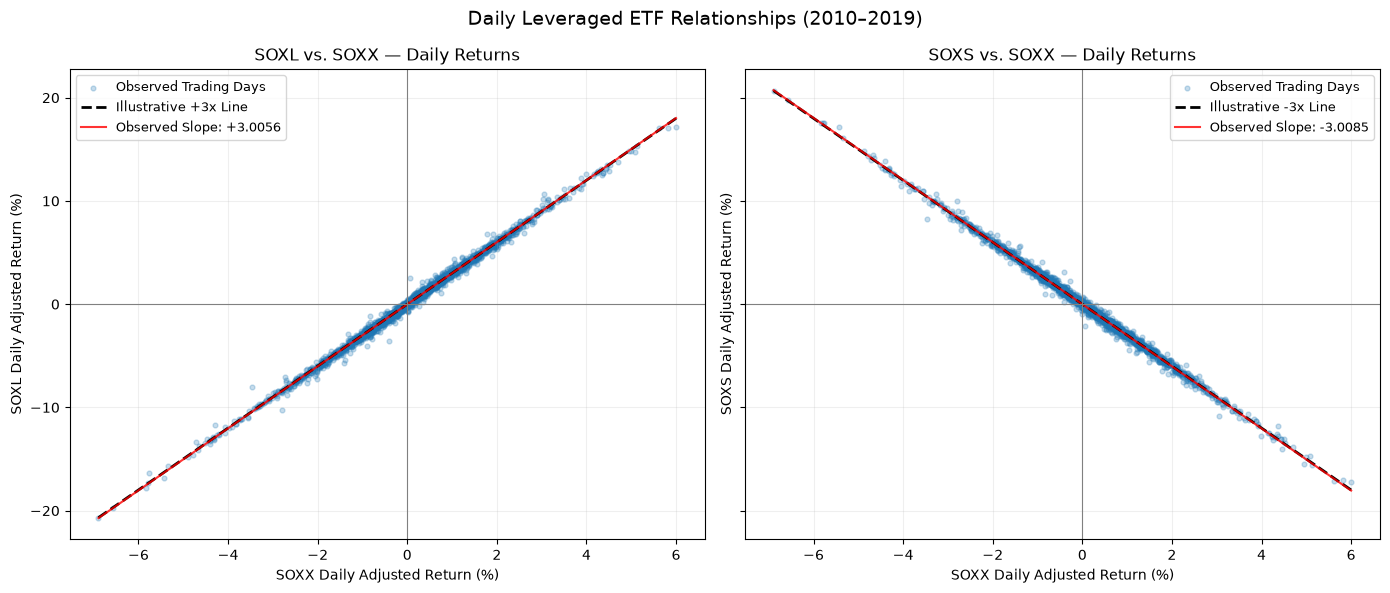

In [13]:

# ============================================================
# 2.4.5 — Daily Leverage Scatterplots
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# SOXX is the common comparison variable on the X-axis.
x_returns = leverage_comparison["SOXX Return (%)"]

# Create a range of SOXX returns for drawing reference lines.
line_x = np.linspace(
    x_returns.min(),
    x_returns.max(),
    200
)

# Create two charts side by side.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

for ax, ticker in zip(axes, ["SOXL", "SOXS"]):

    # Retrieve the leveraged ETF's daily returns.
    y_returns = leverage_comparison[f"{ticker} Return (%)"]

    # Read the observed regression results.
    observed_slope = leverage_regression.loc[
        ticker, "Observed Slope"
    ]

    intercept = leverage_regression.loc[
        ticker, "Intercept (%)"
    ]

    illustrative_slope = leverage_regression.loc[
        ticker, "Illustrative Slope"
    ]

    # Plot each matched trading day as a dot.
    ax.scatter(
        x_returns,
        y_returns,
        s=12,
        alpha=0.25,
        label="Observed Trading Days"
    )

    # Plot the illustrative +3x or -3x reference line.
    ax.plot(
        line_x,
        illustrative_slope * line_x,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Illustrative {illustrative_slope:+.0f}x Line"
    )

    # Plot the fitted regression relationship.
    fitted_y = intercept + observed_slope * line_x

    ax.plot(
        line_x,
        fitted_y,
        color="red",
        linewidth=1.5,
        alpha=0.8,
        label=f"Observed Slope: {observed_slope:+.4f}"
    )

    # Mark zero returns on both axes.
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(f"{ticker} vs. SOXX — Daily Returns")
    ax.set_xlabel("SOXX Daily Adjusted Return (%)")
    ax.set_ylabel(f"{ticker} Daily Adjusted Return (%)")

    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Daily Leveraged ETF Relationships (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.4.6 — Findings from Daily Leverage Scatterplots

#### 1. SOXL Followed a Strong Positive Linear Relationship

The SOXL–SOXX scatterplot shows a narrow, upward-sloping pattern across 2,317 matched trading days.

The observed regression slope was **+3.0056**, compared with the illustrative +3x reference slope.

The fitted regression line and illustrative reference line nearly overlap.

This is consistent with SOXL having approximately three times the daily return sensitivity of SOXX during the comparison period.

#### 2. SOXS Followed a Strong Negative Linear Relationship

The SOXS–SOXX scatterplot shows a narrow, downward-sloping pattern.

The observed regression slope was **-3.0085**, compared with the illustrative -3x reference slope.

SOXS generally moved in the opposite direction to SOXX, with substantially larger daily percentage movements.

#### 3. Individual Observations Deviated from the Reference Lines

Although most observations were concentrated near the illustrative leverage lines, some dots fell above or below them.

This indicates that the simple +3x and -3x SOXX calculations did not reproduce every observed ETF return exactly.

A regression slope summarizes the average linear relationship across the sample. It does not guarantee an exact relationship on individual trading days.

#### 4. The Regression and Reference Lines Were Nearly Identical

The observed regression slopes were close to the illustrative leverage multiples:

| ETF | Observed Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

The similarity explains why the fitted and illustrative lines visually overlap.

However, similarity between these slopes does not establish exact daily benchmark tracking.

#### 5. Methodological Limitations

SOXX is an unleveraged semiconductor-sector comparison ETF, not a verified exact historical benchmark for SOXL or SOXS.

Differences between observed ETF returns and the illustrative SOXX-based leverage lines cannot automatically be attributed to fees, financing costs, or tracking errors.

These scatterplots show contemporaneous relationships and do not establish forecasting ability.

#### Next Investigation

Quantify how much individual SOXL and SOXS daily returns differed from the illustrative +3x and -3x SOXX relationships.

This will help us distinguish a strong overall regression relationship from the variability of individual daily observations.



### 2.4.7 — Quantifying Daily Leverage Deviations

#### Objective

Measure how much SOXL and SOXS daily returns differed from illustrative +3x and -3x multiples of SOXX daily returns.

Our previous regression results were close to these reference relationships:

| ETF | Observed Regression Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

However, a regression slope summarizes thousands of observations. It does not tell us how much individual trading days deviated from the reference.

#### What Is a Daily Leverage Deviation?

A daily leverage deviation is the difference between an ETF's observed return and its illustrative return based on SOXX.

For SOXL:

$$
D_{\mathrm{SOXL},t}
=
R_{\mathrm{SOXL},t}-3R_{\mathrm{SOXX},t}
$$

For SOXS:

$$
D_{\mathrm{SOXS},t}
=
R_{\mathrm{SOXS},t}+3R_{\mathrm{SOXX},t}
$$

The addition in the SOXS equation occurs because its illustrative leverage multiple is negative.

#### Worked Example — SOXL

Suppose SOXX gains 2% in one trading day.

The illustrative SOXL return is:

$$
3\times2\%=6\%
$$

If SOXL actually gains 5.7%, the deviation is:

$$
5.7\%-6.0\%=-0.3
\text{ percentage points}
$$

SOXL's observed return was 0.3 percentage points below the illustrative return.

#### Worked Example — SOXS

Suppose SOXX gains 2%, and SOXS loses 5.8%.

The illustrative SOXS return is:

$$
-3\times2\%=-6\%
$$

The deviation is:

$$
-5.8\%-(-6.0\%)=+0.2
\text{ percentage points}
$$

SOXS's observed return was 0.2 percentage points above its illustrative return.

#### What Is an Absolute Deviation?

An absolute deviation removes the sign:

$$
|D_t|
$$

For example:

| Signed Deviation | Absolute Deviation |
|---|---:|
| -0.3 percentage points | 0.3 percentage points |
| +0.2 percentage points | 0.2 percentage points |
| -1.5 percentage points | 1.5 percentage points |

This helps us measure the size of deviations without positive and negative differences cancelling each other out.

#### Summary Measures

We will calculate four useful statistics:

**Mean Deviation**

The average signed difference. Positive and negative deviations can cancel each other out.

**Mean Absolute Deviation**

The average size of the deviations, ignoring their direction.

This is also commonly called the mean absolute error (MAE) when evaluating differences from a reference.

**95th Percentile of Absolute Deviation**

A value at or below which approximately 95% of the observed absolute deviations fall.

It helps describe the larger deviations without relying entirely on the single most extreme observation.

**Maximum Absolute Deviation**

The largest observed deviation magnitude during the comparison period.

#### Important Methodological Distinction

These are **SOXX-relative illustrative leverage deviations**, not official ETF tracking errors.

SOXX was not necessarily the exact benchmark underlying SOXL or SOXS.

Differences may reflect benchmark composition, fund expenses, financing costs, market conditions, adjusted-price methodology, and other factors.

We cannot isolate these causes using the deviation calculation alone.

#### Research Restrictions

All calculations use the same 2,317 matched trading days from October 18, 2010 through December 31, 2019.

This is descriptive historical analysis. No forecasting model is being trained or evaluated.


In [14]:

# ============================================================
# 2.4.7 — SOXX-Relative Daily Leverage Deviations
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Create a separate table to preserve our existing dataset.
leverage_deviations = leverage_comparison.copy()

# Reference daily returns based on illustrative leverage.
leverage_deviations["SOXL Reference (%)"] = (
    3 * leverage_deviations["SOXX Return (%)"]
)

leverage_deviations["SOXS Reference (%)"] = (
    -3 * leverage_deviations["SOXX Return (%)"]
)

# Calculate observed return minus illustrative return.
for ticker in ["SOXL", "SOXS"]:

    leverage_deviations[f"{ticker} Deviation (pp)"] = (
        leverage_deviations[f"{ticker} Return (%)"]
        - leverage_deviations[f"{ticker} Reference (%)"]
    )

    # Absolute deviation measures the size of the difference.
    leverage_deviations[f"{ticker} Absolute Deviation (pp)"] = (
        leverage_deviations[f"{ticker} Deviation (pp)"].abs()
    )

# Calculate descriptive statistics for each ETF.
deviation_rows = []

for ticker in ["SOXL", "SOXS"]:

    deviation = leverage_deviations[f"{ticker} Deviation (pp)"]
    absolute_deviation = deviation.abs()

    deviation_rows.append({
        "ETF": ticker,
        "Matched Days": deviation.count(),
        "Mean Deviation (pp)": deviation.mean(),
        "Mean Absolute Deviation (pp)": absolute_deviation.mean(),
        "95th Percentile Absolute (pp)": absolute_deviation.quantile(0.95),
        "Maximum Absolute Deviation (pp)": absolute_deviation.max()
    })

deviation_summary = pd.DataFrame(deviation_rows).set_index("ETF")

# Validate our results.
assert len(leverage_deviations) == 2317

assert np.isfinite(
    deviation_summary.select_dtypes(include="number").to_numpy()
).all()

print("SOXX-Relative Daily Leverage Deviation Summary")
print("All deviation measures are in percentage points.")
print("These are NOT official benchmark tracking errors.\n")

display(deviation_summary.round(4))

# Display a few daily examples to inspect the calculation.
print("\nFirst Five SOXL Daily Deviation Calculations")

display(
    leverage_deviations[
        [
            "Date",
            "SOXX Return (%)",
            "SOXL Return (%)",
            "SOXL Reference (%)",
            "SOXL Deviation (pp)",
            "SOXL Absolute Deviation (pp)"
        ]
    ].head(5).round(4)
)


SOXX-Relative Daily Leverage Deviation Summary
All deviation measures are in percentage points.
These are NOT official benchmark tracking errors.



,Matched Days,Mean Deviation (pp),Mean Absolute Deviation (pp),95th Percentile Absolute (pp),Maximum Absolute Deviation (pp)
ETF,,,,,
SOXL,2317,-0.0086,0.1878,0.5328,2.3481
SOXS,2317,-0.0074,0.1986,0.5760,2.0993



First Five SOXL Daily Deviation Calculations


,Date,SOXX Return (%),SOXL Return (%),SOXL Reference (%),SOXL Deviation (pp),SOXL Absolute Deviation (pp)
153,2010-10-18,-0.6818,-2.3180,-2.0454,-0.2725,0.2725
154,2010-10-19,-1.3938,-4.1909,-4.1815,-0.0095,0.0095
155,2010-10-20,0.6751,1.6724,2.0253,-0.3529,0.3529
156,2010-10-21,-0.5867,-1.4868,-1.7601,0.2733,0.2733
157,2010-10-22,1.9392,5.9408,5.8177,0.1231,0.1231



### 2.4.8 — Findings from Daily Leverage Deviations

#### 1. Average Signed Deviations Were Close to Zero

Across 2,317 matched trading days, the mean SOXX-relative deviations were:

- SOXL: **-0.0086 percentage points**
- SOXS: **-0.0074 percentage points**

These values indicate that positive and negative daily differences largely offset each other over the comparison period.

However, a mean close to zero does not mean that individual daily deviations were always small.

#### 2. Mean Absolute Deviations Were Below 0.2 Percentage Points

The mean absolute deviations were:

| ETF | Mean Absolute Deviation |
|---|---:|
| SOXL | 0.1878 percentage points |
| SOXS | 0.1986 percentage points |

Absolute deviations measure the size of the differences without allowing positive and negative values to cancel.

SOXS had a slightly larger mean absolute deviation than SOXL.

For example, SOXL's value of 0.1878 means its observed daily return differed from the illustrative +3x SOXX return by approximately 0.1878 percentage points on average.

This does not mean its return differed by 0.1878% in relative terms.

#### 3. Most Absolute Deviations Were Relatively Small

The 95th percentile absolute deviations were:

- SOXL: **0.5328 percentage points**
- SOXS: **0.5760 percentage points**

Approximately 95% of observed daily absolute deviations were at or below these respective levels.

The remaining observations had larger deviations.

These results are descriptive statistics from the development period, not future probability estimates.

#### 4. Occasional Large Deviations Still Occurred

The maximum observed absolute deviations were:

- SOXL: **2.3481 percentage points**
- SOXS: **2.0993 percentage points**

These values were substantially larger than the corresponding mean absolute deviations.

This distinction is important: a historical regression slope close to +3 or -3 does not guarantee that every trading day closely follows the illustrative leverage relationship.

#### 5. These Are Not Official Tracking Errors

The deviations were calculated relative to SOXX:

$$
D_{\mathrm{SOXL},t}
=R_{\mathrm{SOXL},t}-3R_{\mathrm{SOXX},t}
$$

$$
D_{\mathrm{SOXS},t}
=R_{\mathrm{SOXS},t}+3R_{\mathrm{SOXX},t}
$$

SOXX is a semiconductor-sector comparison ETF, not necessarily the exact benchmark underlying the leveraged funds.

The calculated differences may reflect benchmark differences, fund costs, financing, pricing methodology, and other effects.

We cannot identify the individual causes from these calculations.

Therefore, the results must be described as **SOXX-relative illustrative leverage deviations**, not official fund tracking errors.

#### Research Implication

SOXL and SOXS exhibited strong daily relationships close to illustrative +3x and -3x SOXX returns.

Their average absolute deviations were relatively small, but some individual daily deviations exceeded two percentage points.

This shows why measuring a regression slope alone is insufficient to describe the entire historical relationship.

The next step is to visualize the distribution of these deviations and investigate whether they are concentrated near zero or include notable extreme observations.



### 2.4.9 — Visualizing Daily Leverage Deviations

#### Objective

Examine the distribution of SOXL's and SOXS's daily deviations from illustrative +3x and -3x SOXX returns.

Our earlier calculations showed that the mean absolute deviations were approximately 0.19–0.20 percentage points, but the largest individual deviations exceeded two percentage points.

We now want to visualize how frequently different deviation sizes occurred.

#### Understanding Signed Deviations

A signed deviation can be positive, negative, or zero.

$$
D_t = R_{\mathrm{observed},t} - R_{\mathrm{reference},t}
$$

- **Positive deviation:** The observed ETF return was higher than the illustrative reference return.
- **Negative deviation:** The observed ETF return was lower than the illustrative reference return.
- **Zero deviation:** The observed return exactly matched the illustrative reference.

For example, suppose SOXL's illustrative return is +6%.

| Observed SOXL Return | Signed Deviation |
|---|---:|
| +6.3% | +0.3 percentage points |
| +5.7% | -0.3 percentage points |
| +6.0% | 0.0 percentage points |

The deviation measures the difference between two returns. It is not the ETF's return itself.

#### Why Use a Histogram?

A histogram shows how often different signed deviations occurred.

For our visualization:

- **X-axis:** Signed daily deviation in percentage points
- **Y-axis:** Number of matched trading days
- **Vertical dashed line:** Zero deviation
- **Bars to the left of zero:** Observed returns below the illustrative reference
- **Bars to the right of zero:** Observed returns above the illustrative reference

We will use bins that are 0.1 percentage points wide.

Both ETFs will use identical horizontal and vertical scales for comparison.

#### What Are We Looking For?

1. Are most deviations concentrated near zero?
2. Does one ETF have a visibly wider deviation distribution?
3. Are there observations far from zero?
4. Do positive and negative deviations appear on both sides?

#### Important Limitation

These are deviations from illustrative SOXX-based leverage calculations.

They are **not official tracking errors**, because SOXX is not necessarily the exact underlying benchmark of SOXL or SOXS.

The charts cannot identify the specific causes of deviations or establish future tracking performance.

Only the October 18, 2010–December 31, 2019 development-period comparison is used.


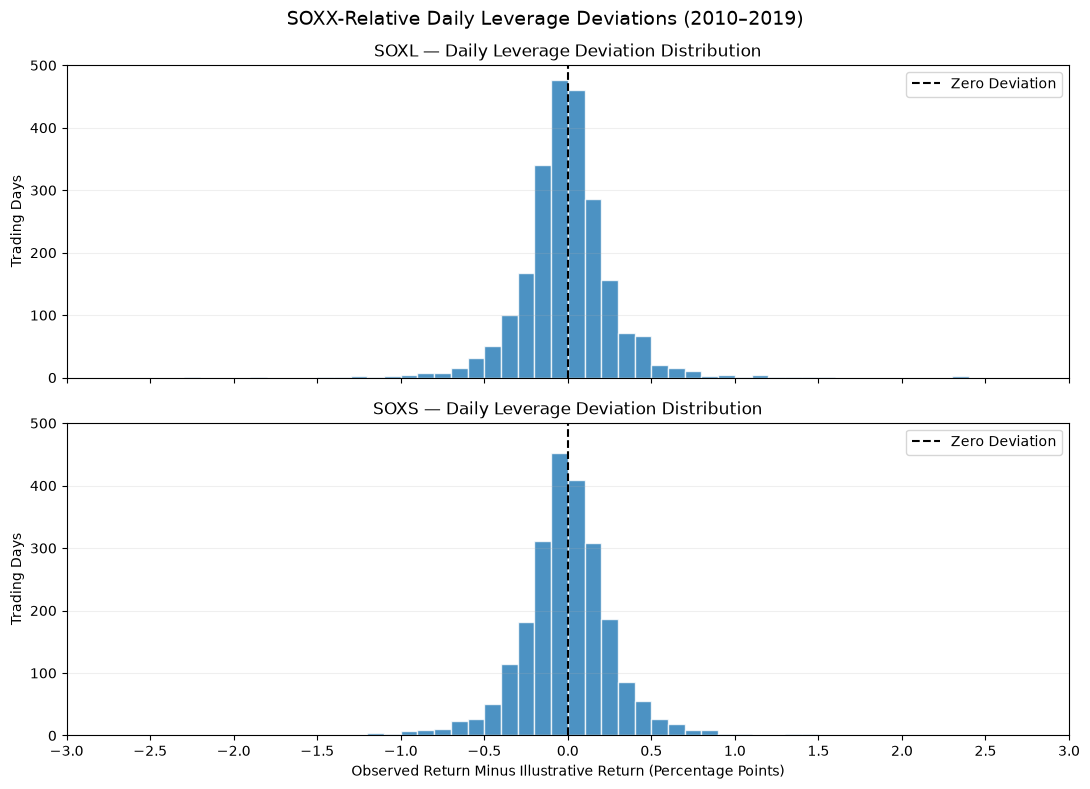

In [15]:

# ============================================================
# 2.4.9 — Daily Leverage Deviation Histograms
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Create common bins from -3 to +3 percentage points.
# Each bin has a width of 0.1 percentage points.
bins = np.arange(-3, 3.1, 0.1)

# Create two vertically stacked histograms.
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(11, 8),
    sharex=True,
    sharey=True
)

for ax, ticker in zip(axes, ["SOXL", "SOXS"]):

    # Retrieve the signed daily deviations.
    deviations = leverage_deviations[
        f"{ticker} Deviation (pp)"
    ]

    # Confirm that every observation fits within our bins.
    assert deviations.notna().all()
    assert deviations.between(-3, 3).all()

    # Draw the distribution.
    ax.hist(
        deviations,
        bins=bins,
        alpha=0.8,
        edgecolor="white"
    )

    # Mark zero deviation.
    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Zero Deviation"
    )

    ax.set_title(f"{ticker} — Daily Leverage Deviation Distribution")
    ax.set_ylabel("Trading Days")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

# Keep both histograms on identical horizontal scales.
axes[-1].set_xlim(-3, 3)
axes[-1].set_xticks(np.arange(-3, 3.5, 0.5))

axes[-1].set_xlabel(
    "Observed Return Minus Illustrative Return (Percentage Points)"
)

fig.suptitle(
    "SOXX-Relative Daily Leverage Deviations (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.4.10 — Daily Leverage Relationships: Overall Findings

#### 1. Daily Deviations Were Concentrated Near Zero

The SOXL and SOXS deviation histograms show that most observed daily returns were relatively close to their illustrative +3x and -3x SOXX-based reference returns.

Both distributions have pronounced central peaks near zero.

This is consistent with the mean absolute deviations calculated earlier:

- SOXL: 0.1878 percentage points
- SOXS: 0.1986 percentage points

The narrow central distributions indicate that relatively small deviations were common during the comparison period.

#### 2. SOXS Had a Slightly Larger Average Absolute Deviation

SOXS had a mean absolute deviation of 0.1986 percentage points, compared with 0.1878 for SOXL.

The 95th percentile absolute deviation was also slightly higher for SOXS:

| ETF | 95th Percentile Absolute Deviation |
|---|---:|
| SOXL | 0.5328 percentage points |
| SOXS | 0.5760 percentage points |

This indicates that SOXS generally had somewhat larger SOXX-relative deviations according to these measures.

The differences were modest and do not establish that one fund tracked its actual benchmark more accurately than the other.

#### 3. Large Individual Deviations Still Occurred

The histograms show relatively few observations far from zero.

However, the maximum absolute deviations were:

- SOXL: 2.3481 percentage points
- SOXS: 2.0993 percentage points

These observations show that the illustrative leverage relationships did not hold exactly on every trading day.

A regression slope close to +3 or -3 can conceal substantial differences on individual dates.

#### 4. Deviations Occurred in Both Directions

Both histograms contain positive and negative deviations.

A positive deviation means the observed ETF return exceeded its illustrative reference return.

A negative deviation means the observed ETF return fell below its illustrative reference return.

The signed means were slightly negative:

- SOXL: -0.0086 percentage points
- SOXS: -0.0074 percentage points

These small signed averages should not be confused with the typical magnitude of deviations, because positive and negative differences can cancel.

---

### Section 2.4 — Overall Conclusion

The analysis of 2,317 matched trading days from October 18, 2010 through December 31, 2019 established several descriptive relationships.

**Strong daily-return correlations**

SOXL and SOXX had a correlation of +0.9980. SOXS and SOXX had a correlation of -0.9979.

These results indicate strong contemporaneous relationships consistent with long and inverse semiconductor exposure.

**Regression slopes close to illustrative daily leverage**

The observed slopes were:

| ETF | Observed Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

Both estimates were close to illustrative daily leverage multiples.

**Individual returns were not exact multiples**

Although the fitted regression lines nearly overlapped the illustrative reference lines, daily deviations occurred.

The mean absolute deviations were approximately 0.19–0.20 percentage points, and the largest observed deviations exceeded two percentage points.

#### Methodological Limitations

SOXX is an unleveraged semiconductor-sector comparison ETF, not necessarily the exact underlying benchmark for SOXL or SOXS.

The regression slopes and deviation statistics therefore cannot be interpreted as official fund tracking-accuracy measurements.

Historical benchmark differences, expenses, financing costs, derivatives, and adjusted-price methodology may affect the observed relationships.

The analysis does not isolate these effects or establish causation.

All relationships are contemporaneous and restricted to development-period observations.

#### Research Implication

SOXL and SOXS showed daily-return behaviour consistent with approximately +3x and -3x semiconductor-sector exposure.

However, a strong daily leverage relationship does not guarantee that the leveraged ETFs will deliver exactly three times the sector's cumulative return over multiple days.

Daily returns compound, and the sequence of positive and negative movements matters.

**Next: Section 2.5 — Compounding and Path Dependence**

We will investigate how daily leveraged returns accumulate over time and why multi-day performance can differ substantially from simply multiplying the sector's cumulative return by three.



## 2.5 — Compounding and Path Dependence

### 2.5.1 — Understanding Daily Compounding

**Research question:** Why can a daily leveraged ETF's multi-day return differ from three times the semiconductor market's cumulative return?

**Objective:** Understand how daily returns compound, how leverage changes the calculation, and why different market paths can produce different investment outcomes.

---

### 1. Understanding Compounding

Compounding occurs when each day's percentage return is applied to the investment's **updated value**, not its original value.

Consider an investment starting at **100 USD**:

| Day | Daily Return | Investment Value (USD) |
|---|---:|---:|
| Starting value | — | 100.00 |
| Day 1 | +10% | 110.00 |
| Day 2 | -10% | 99.00 |

The investment finishes at **99 USD**, representing a **1% cumulative loss**.

Although the daily returns are +10% and -10%, they do not cancel each other out. The second day's loss is calculated using 110 USD instead of 100 USD.

**Key takeaway:** Adding daily percentage returns does not generally give the correct cumulative return.

### 2. Calculating Cumulative Returns

The cumulative return over $T$ trading days is:

$$
R_{1:T}=\left[\prod_{t=1}^{T}(1+r_t)\right]-1
$$

**Where:**

- $R_{1:T}$ = cumulative return over the holding period
- $r_t$ = daily return expressed as a decimal
- $T$ = number of trading days
- $\prod$ = multiply the indicated terms together

For two trading days:

$$
R_{1:2}=(1+r_1)(1+r_2)-1
$$

**Worked example:**

$$
R_{1:2}=(1.10)(0.90)-1=-0.01=-1\%
$$

The formula confirms that a 10% gain followed by a 10% loss produces a cumulative return of -1%.

> **Python connection:** We will use `cumprod()` when examining historical returns. This pandas method calculates a running product, allowing us to track how an investment's value changes through repeated daily compounding.

---

### 3. How Daily Leverage Changes Compounding

SOXL targets approximately **+3x** the daily performance of its underlying semiconductor benchmark, before fees and expenses.

SOXS targets approximately **-3x** the daily performance.

In a simplified model with exact daily leverage:

$$
r_{+3x,t}=3r_t
$$

$$
r_{-3x,t}=-3r_t
$$

These relationships apply to **individual days**, not directly to cumulative returns across multiple days.

Each leveraged investment compounds its own daily gains and losses.

**Example: A volatile two-day market**

Assume the semiconductor benchmark rises 10% on Day 1, then declines by approximately 9.09% on Day 2.

| Investment | Starting Value (USD) | Ending Value (USD) | Cumulative Return |
|---|---:|---:|---:|
| Benchmark | 100.00 | 100.00 | 0.00% |
| Hypothetical +3x daily | 100.00 | 94.55 | -5.45% |
| Hypothetical -3x daily | 100.00 | 89.09 | -10.91% |

The benchmark returns to its starting value, but both hypothetical leveraged investments lose money.

This happens because their larger daily percentage movements compound from changing investment values.

For a hypothetical daily leveraged investment held over $T$ trading days, the cumulative returns are:

**Positive 3x leverage:**

$$
R_{+3x,1:T}=\left[\prod_{t=1}^{T}(1+3r_t)\right]-1
$$

**Inverse 3x leverage:**

$$
R_{-3x,1:T}=\left[\prod_{t=1}^{T}(1-3r_t)\right]-1
$$

These formulas assume exact daily leverage, daily resetting, and no costs or tracking differences. They do not describe the exact realized returns of SOXL or SOXS.

---

### 4. Understanding Path Dependence

**Path dependence** means that an investment's cumulative performance depends on the daily returns experienced during the holding period.

Consider two market paths:

| Market Path | Day 1 | Day 2 | Benchmark Cumulative Return |
|---|---:|---:|---:|
| Volatile path | +10% | Approximately -9.09% | 0.00% |
| Flat path | 0% | 0% | 0.00% |

Both benchmark paths finish at the same value. However, the hypothetical +3x daily investment experiences different outcomes:

- **Volatile path:** Approximately -5.45%
- **Flat path:** 0.00%

Even though the benchmark's cumulative return is identical, the leveraged investment's cumulative return differs.

**Important distinction:** Reversing the order of the exact same daily returns does not change their final compounded product. Path dependence refers to differences in the daily return patterns experienced, not necessarily their chronological ordering.

---

### 5. Does Compounding Always Hurt Leveraged ETFs?

**No.** Daily compounding can produce favourable or unfavourable outcomes compared with simply multiplying a benchmark's multi-day return by three.

Consider two consecutive benchmark gains of 10%:

| Investment | Two-Day Cumulative Return |
|---|---:|
| Benchmark | +21.00% |
| Three times benchmark cumulative return | +63.00% |
| Hypothetical +3x daily investment | +69.00% |

The hypothetical leveraged investment earns 69%, exceeding the simple three-times comparison of 63%.

This happens because the second day's leveraged gain compounds on the larger investment value.

In contrast, alternating gains and losses can create a compounding disadvantage, often described as **volatility drag**.

**Key takeaway:** Daily leverage does not automatically produce poor multi-day returns. The outcome depends on the pattern of daily returns, the leverage multiple, and the holding period.

### 6. Research Relevance and Limitations

Our previous analysis showed that SOXL and SOXS had strong daily-return relationships with SOXX during the development period.

However, strong daily relationships do not guarantee equivalent multi-day leverage.

Understanding compounding is important for our project because it helps explain why SOXL may experience substantial multi-day losses, even when the underlying semiconductor market's cumulative movement is relatively small.

**Methodological considerations:**

- Numerical examples assume exact daily leverage without fees, financing costs, or tracking differences.
- Actual ETF returns can differ from these idealized calculations.
- SOXX is our unleveraged semiconductor-sector comparator, not necessarily the exact historical benchmark of SOXL or SOXS.
- Historical comparisons with SOXX must be labelled illustrative, not official tracking-accuracy measurements.
- Our exploratory analysis remains restricted to the **2010–2019 development period**.
- The 2026 final holdout remains excluded from exploratory analysis.

**Next:** Verify the numerical examples using Python, then investigate historical cumulative returns for SOXL, SOXS, and SOXX.


In [16]:

# ============================================================
# 2.5.1 — Daily Compounding: Numerical Example
# ============================================================

import pandas as pd

# Every investment begins with 100 USD.
initial_value = 100.0

# Two market paths that end with the same benchmark return.
#
# Path 1: +10%, followed by exactly -1/11 (-9.0909...%).
# Path 2: No change on either day.
#
# Both benchmark investments end at 100 USD.

market_paths = {
    "Volatile path": [0.10, -1 / 11],
    "Flat path": [0.00, 0.00]
}

daily_results = []
summary_results = []

for path_name, daily_returns in market_paths.items():

    # Reset all investments to their starting values.
    benchmark = initial_value
    long_3x = initial_value
    inverse_3x = initial_value

    for day, daily_return in enumerate(daily_returns, start=1):

        # Calculate idealized daily leveraged returns.
        long_3x_return = 3 * daily_return
        inverse_3x_return = -3 * daily_return

        # Apply each day's return to the updated investment value.
        benchmark *= (1 + daily_return)
        long_3x *= (1 + long_3x_return)
        inverse_3x *= (1 + inverse_3x_return)

        # Record the investment values after each day.
        daily_results.append({
            "Market Path": path_name,
            "Day": day,
            "Benchmark Daily Return (%)": daily_return * 100,
            "Benchmark Value (USD)": benchmark,
            "+3x Value (USD)": long_3x,
            "-3x Value (USD)": inverse_3x
        })

    # Convert ending values into cumulative percentage returns.
    benchmark_cumulative = (
        benchmark / initial_value - 1
    ) * 100

    long_3x_cumulative = (
        long_3x / initial_value - 1
    ) * 100

    inverse_3x_cumulative = (
        inverse_3x / initial_value - 1
    ) * 100

    summary_results.append({
        "Market Path": path_name,
        "Benchmark (%)": benchmark_cumulative,
        "+3x Daily (%)": long_3x_cumulative,
        "-3x Daily (%)": inverse_3x_cumulative,
        "3x Benchmark Cumulative (%)": 3 * benchmark_cumulative
    })

# Convert the recorded values into pandas tables.
daily_compounding_table = pd.DataFrame(daily_results)

compounding_summary = (
    pd.DataFrame(summary_results)
    .set_index("Market Path")
)

# Display the daily calculations.
print("Daily Investment Values:")
display(daily_compounding_table.round(4))

# Display the cumulative return comparison.
print("\nCumulative Returns by Market Path:")
display(compounding_summary.round(4))

# ============================================================
# Validation Checks
# ============================================================

# Both benchmark paths should finish at 0% cumulative return.
assert (
    compounding_summary["Benchmark (%)"].abs() < 1e-9
).all()

# Check the expected +3x result for the volatile path.
assert abs(
    compounding_summary.loc["Volatile path", "+3x Daily (%)"]
    - (-60 / 11)
) < 1e-9

# Check the expected -3x result for the volatile path.
assert abs(
    compounding_summary.loc["Volatile path", "-3x Daily (%)"]
    - (-120 / 11)
) < 1e-9

# All investments should remain unchanged on the flat path.
assert (
    compounding_summary.loc[
        "Flat path",
        ["Benchmark (%)", "+3x Daily (%)", "-3x Daily (%)"]
    ].abs() < 1e-9
).all()

print("\nAll numerical compounding checks passed.")


Daily Investment Values:


,Market Path,Day,Benchmark Daily Return (%),Benchmark Value (USD),+3x Value (USD),-3x Value (USD)
0,Volatile path,1,10.0000,110.0,130.0000,70.0000
1,Volatile path,2,-9.0909,100.0,94.5455,89.0909
2,Flat path,1,0.0000,100.0,100.0000,100.0000
3,Flat path,2,0.0000,100.0,100.0000,100.0000



Cumulative Returns by Market Path:


,Benchmark (%),+3x Daily (%),-3x Daily (%),3x Benchmark Cumulative (%)
Market Path,,,,
Volatile path,0.0,-5.4545,-10.9091,0.0
Flat path,0.0,0.0000,0.0000,0.0



All numerical compounding checks passed.



### 2.5.2 — Historical Cumulative Returns

#### Objective

Examine how actual SOXL, SOXS, and SOXX daily returns compounded during the development period.

We will also construct hypothetical investments using exactly +3x and -3x SOXX's daily returns.

This allows us to compare observed ETF growth against illustrative daily-leverage scenarios.

#### 1. Research Period and Starting Values

For consistency with Section 2.4, the comparison begins on **October 18, 2010** and ends on **December 31, 2019**.

Each investment is assigned an initial value of **100 USD** on October 18, 2010.

We will track five investment paths:

| Investment | Daily Return Used |
|---|---|
| SOXX | Actual SOXX return |
| SOXL | Actual SOXL return |
| SOXS | Actual SOXS return |
| Hypothetical +3x | 3 times SOXX's daily return |
| Hypothetical -3x | -3 times SOXX's daily return |

The hypothetical investments assume exact daily leverage. They are not actual financial products.

#### 2. Calculating Investment Growth

An investment's value after each trading day is:

$$
V_t=V_{t-1}(1+r_t)
$$

Where:

- $V_t$ = investment value at the end of day $t$
- $V_{t-1}$ = investment value on the preceding trading day
- $r_t$ = daily return expressed as a decimal

For example, an investment worth 100 USD that gains 5% becomes:

$$
V_1=100(1.05)=105
$$

If it subsequently loses 2%:

$$
V_2=105(0.98)=102.90
$$

The cumulative return is:

$$
R=\left(\frac{102.90}{100}-1\right)\times100=2.90\%
$$

#### 3. How We Will Use Python

We will use the existing `leverage_comparison` DataFrame from Section 2.4.

The main pandas operation is:

`(1 + daily_returns).cumprod()`

- `1 + daily_returns` converts decimal returns into daily growth factors.
- `.cumprod()` multiplies successive growth factors.
- Multiplying by 100 converts the growth series into the value of an investment beginning at 100 USD.

**Important:** Our existing ETF return columns are expressed as percentages, so we must divide them by 100 before calculating growth factors.

We will also:

- Preserve the original DataFrames using `.copy()`.
- Sort observations chronologically.
- Set the first observation to the initial investment value of 100 USD.
- Apply subsequent daily returns beginning on the next trading day.
- Validate the reconstructed ETF values against their adjusted closing prices.

There are 2,317 matched dates in our existing leverage-comparison dataset. Rebaselining on the first date means there will be 2,316 subsequent daily growth steps.

The first row's return is intentionally not applied because it represents a change from the preceding trading day, before our chosen investment start.

#### 4. Interpretation and Limitations

The historical ETF investment paths are reconstructed from adjusted closing prices. These are simplified, reinvestment-consistent growth measures and do not account for individual investor taxes or transaction costs.

The hypothetical leveraged paths use SOXX as an illustrative sector comparator.

They do not represent the exact historical benchmark, expense structure, or tracking performance of SOXL or SOXS.

The analysis is descriptive and contains no data from the 2026 final holdout.


In [17]:

# ============================================================
# 2.5.2 — Historical Cumulative Returns
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Create a separate working table from Section 2.4.
# The original dataset remains unchanged.
compounding_history = (
    leverage_comparison[["Date"] + return_columns]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)

# Every investment begins at 100 USD.
initial_investment = 100.0

# Confirm the historical comparison period.
assert compounding_history["Date"].iloc[0] == pd.Timestamp("2010-10-18")
assert compounding_history["Date"].iloc[-1] == pd.Timestamp("2019-12-31")

assert compounding_history["Date"].is_unique
assert compounding_history[return_columns].notna().all().all()

# ------------------------------------------------------------
# Part A — Actual ETF Investment Growth
# ------------------------------------------------------------

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Convert daily percentage returns into decimal returns.
    daily_returns = (
        compounding_history[f"{ticker} Return (%)"] / 100
    )

    # Convert returns into daily growth factors.
    growth_factors = 1 + daily_returns

    # The first date is our starting investment date.
    # Its pre-existing return belongs to the previous interval.
    growth_factors.iloc[0] = 1.0

    # Compound the remaining daily returns.
    compounding_history[f"{ticker} Value (USD)"] = (
        initial_investment * growth_factors.cumprod()
    )

# ------------------------------------------------------------
# Part B — Hypothetical Daily Leveraged Growth
# ------------------------------------------------------------

# Use SOXX as our illustrative sector comparator.
soxx_daily_returns = (
    compounding_history["SOXX Return (%)"] / 100
)

# Build hypothetical daily returns.
hypothetical_returns = {
    "Hypothetical +3x Value (USD)": 3 * soxx_daily_returns,
    "Hypothetical -3x Value (USD)": -3 * soxx_daily_returns
}

for column_name, daily_returns in hypothetical_returns.items():

    growth_factors = 1 + daily_returns

    # Check for mathematically invalid negative growth factors.
    # Do not silently clip or replace invalid observations.
    assert (growth_factors.iloc[1:] >= 0).all(), (
        f"Invalid hypothetical growth factor: {column_name}"
    )

    growth_factors.iloc[0] = 1.0

    compounding_history[column_name] = (
        initial_investment * growth_factors.cumprod()
    )

# ------------------------------------------------------------
# Part C — Summarize Cumulative Performance
# ------------------------------------------------------------

investment_columns = [
    "SOXX Value (USD)",
    "SOXL Value (USD)",
    "SOXS Value (USD)",
    "Hypothetical +3x Value (USD)",
    "Hypothetical -3x Value (USD)"
]

summary_rows = []

for column_name in investment_columns:

    ending_value = compounding_history[column_name].iloc[-1]

    cumulative_return = (
        ending_value / initial_investment - 1
    ) * 100

    summary_rows.append({
        "Investment": column_name.replace(" Value (USD)", ""),
        "Starting Value (USD)": initial_investment,
        "Ending Value (USD)": ending_value,
        "Cumulative Return (%)": cumulative_return
    })

historical_compounding_summary = (
    pd.DataFrame(summary_rows)
    .set_index("Investment")
)

print("Historical Compounding Comparison")
print("Period: October 18, 2010 – December 31, 2019")

print("\nMatched price dates:", len(compounding_history))
print("Compounded daily return steps:", len(compounding_history) - 1)

display(historical_compounding_summary.round(4))

# ------------------------------------------------------------
# Part D — Independent Validation
# ------------------------------------------------------------

# Reconstruct the actual ETF growth directly from adjusted
# closing prices, independently of the daily-return products.
price_check = (
    development
    .set_index("Date")
    .reindex(compounding_history["Date"])
)

for ticker in ["SOXL", "SOXS", "SOXX"]:

    expected_values = (
        initial_investment
        * price_check[ticker].to_numpy()
        / price_check[ticker].iloc[0]
    )

    calculated_values = (
        compounding_history[f"{ticker} Value (USD)"].to_numpy()
    )

    np.testing.assert_allclose(
        calculated_values,
        expected_values,
        rtol=1e-9,
        atol=1e-8
    )

# Confirm that all five investments start at 100 USD.
np.testing.assert_allclose(
    compounding_history[investment_columns].iloc[0].to_numpy(),
    np.full(len(investment_columns), initial_investment)
)

# Confirm all resulting investment values are finite.
assert np.isfinite(
    compounding_history[investment_columns].to_numpy()
).all()

print("\nAll historical compounding validation checks passed.")


Historical Compounding Comparison
Period: October 18, 2010 – December 31, 2019

Matched price dates: 2317
Compounded daily return steps: 2316


,Starting Value (USD),Ending Value (USD),Cumulative Return (%)
Investment,,,
SOXX,100.0,584.3795,484.3795
SOXL,100.0,3603.9361,3503.9361
SOXS,100.0,0.0210,-99.9790
Hypothetical +3x,100.0,4462.5645,4362.5645
Hypothetical -3x,100.0,0.0255,-99.9745



All historical compounding validation checks passed.



### 2.5.3 — Visualizing Historical Compounding

#### Objective

Visualize how actual and hypothetical leveraged investments grew or declined throughout the 2010–2019 comparison period.

The cumulative-return table shows the final outcomes, but it does not show how those outcomes developed over time.

We will create two charts to examine the investment paths.

#### 1. Logarithmic-Scale Comparison

The first chart displays all five investments using a logarithmic vertical axis.

A logarithmic scale is useful because the ending investment values differ enormously.

For example:

- SOXL finishes above 3,600 USD.
- SOXS finishes near 0.02 USD.

On a regular linear chart, SOXS would appear almost completely flat near zero.

A logarithmic scale provides more visibility across very different positive investment values. Equal vertical distances represent equal multiplicative changes, not equal dollar changes.

**Limitation:** A logarithmic scale cannot display zero or negative investment values. We will verify that the historical investment values are strictly positive before plotting.

#### 2. Linear-Scale Comparison

The second chart focuses on three investments:

- Actual SOXX
- Actual SOXL
- Hypothetical +3x daily SOXX

All three begin at 100 USD.

This chart will help us examine when the leveraged investment paths began to diverge and how their differences developed through time.

#### 3. Important Interpretation

The hypothetical +3x series is constructed from daily SOXX returns. It represents an idealized investment that resets its leverage daily without expenses or tracking differences.

The actual SOXL series reflects historical adjusted-price returns.

Differences between the two should not be described as official tracking error because SOXX is not necessarily SOXL's exact historical underlying benchmark.

Both charts describe historical investment growth, not future investment performance.


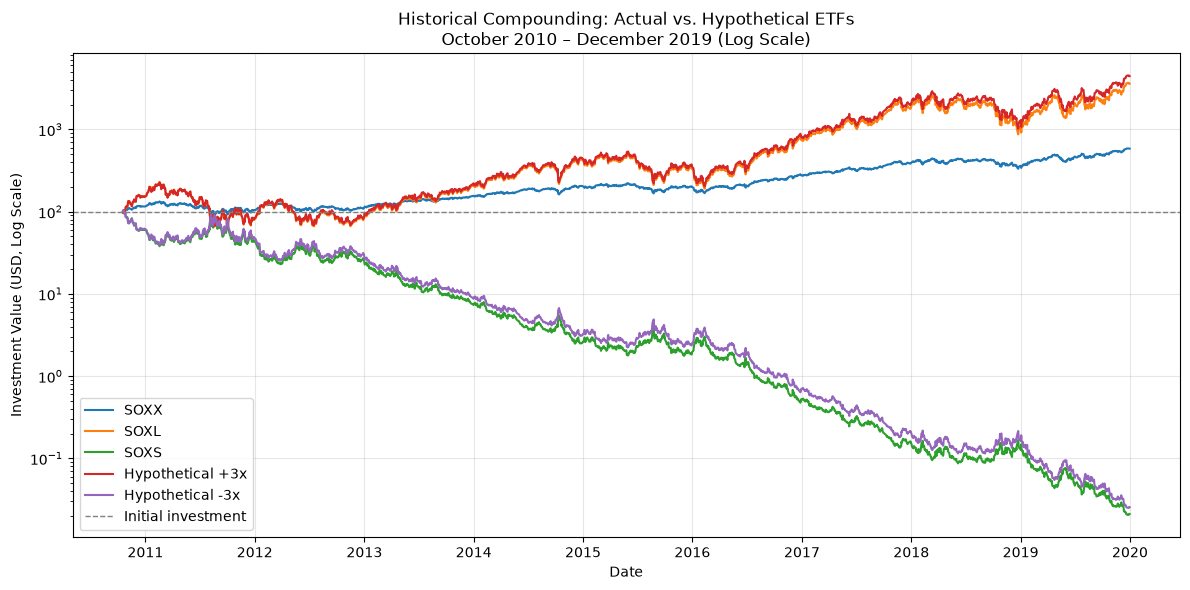

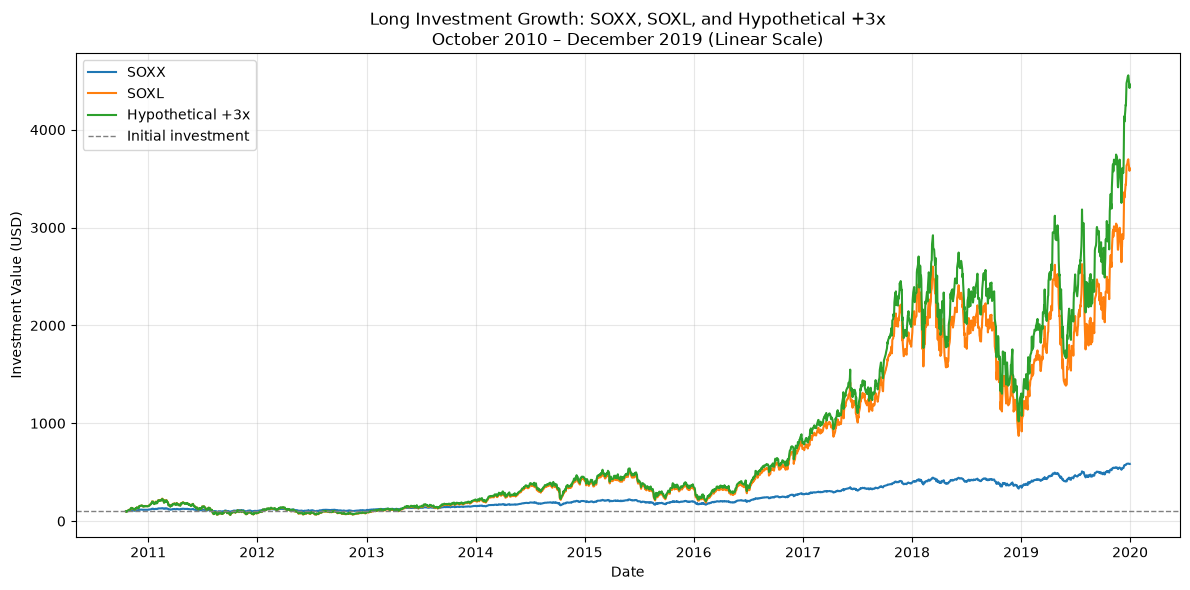

Historical compounding charts generated successfully.


In [18]:

# ============================================================
# 2.5.3 — Visualizing Historical Compounding
# ============================================================

import matplotlib.pyplot as plt

# Ensure the dates are in chronological order.
assert compounding_history["Date"].is_monotonic_increasing

# Confirm all investment values are positive for log scaling.
assert (
    compounding_history[investment_columns] > 0
).all().all()

# ------------------------------------------------------------
# Chart 1 — All Five Investments (Logarithmic Scale)
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for column in investment_columns:

    plt.plot(
        compounding_history["Date"],
        compounding_history[column],
        label=column.replace(" Value (USD)", ""),
        linewidth=1.5
    )

# Initial investment reference.
plt.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Initial investment"
)

plt.yscale("log")

plt.title(
    "Historical Compounding: Actual vs. Hypothetical ETFs\n"
    "October 2010 – December 2019 (Log Scale)"
)

plt.xlabel("Date")
plt.ylabel("Investment Value (USD, Log Scale)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Chart 2 — Long Investment Growth (Linear Scale)
# ------------------------------------------------------------

long_investments = [
    "SOXX Value (USD)",
    "SOXL Value (USD)",
    "Hypothetical +3x Value (USD)"
]

plt.figure(figsize=(12, 6))

for column in long_investments:

    plt.plot(
        compounding_history["Date"],
        compounding_history[column],
        label=column.replace(" Value (USD)", ""),
        linewidth=1.5
    )

plt.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Initial investment"
)

plt.title(
    "Long Investment Growth: SOXX, SOXL, and Hypothetical +3x\n"
    "October 2010 – December 2019 (Linear Scale)"
)

plt.xlabel("Date")
plt.ylabel("Investment Value (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Historical compounding charts generated successfully.")



#### Results and Interpretation

Both charts were generated successfully using 2,317 matched dates from October 18, 2010, through December 31, 2019.

**Historical growth**

SOXX increased from 100 USD to approximately 584.38 USD. SOXL grew to approximately 3,603.94 USD, and the hypothetical +3x daily SOXX investment reached approximately 4,462.56 USD.

The leveraged investments experienced substantially larger fluctuations than SOXX. Their growth became especially pronounced after 2016, although significant declines remained visible, including during 2018.

**Inverse-leveraged performance**

SOXS and hypothetical -3x daily SOXX both declined to approximately 0.02–0.03 USD by the end of the period.

These results illustrate the substantial losses that daily inverse-leveraged investments can experience during a prolonged period of positive sector performance.

**Actual versus hypothetical leverage**

Hypothetical +3x daily SOXX finished above actual SOXL. This difference may reflect historical benchmark differences, expenses, financing, tracking effects, and compounding of daily deviations.

We cannot isolate those effects using these charts.

**Research implication**

Daily leverage can produce cumulative investment outcomes that differ substantially from a simple multiple of the sector's cumulative return.

However, these long-term charts do not establish how frequently large losses occur over shorter holding periods.

The next analysis examines rolling 5-day, 10-day, and 20-day returns within the development period.



### 2.5.4 — Rolling Multi-Day Compounding

#### Objective

Examine how compounded investment returns vary across shorter holding periods and compare exact hypothetical daily leverage with a simple multiple of SOXX's cumulative return.

We will calculate rolling **5-day, 10-day, and 20-day returns**.

These horizons are useful because our broader research focuses on near-term SOXL downside risk.

#### 1. What Is a Rolling Holding Period?

A rolling holding period measures the cumulative return over a fixed number of consecutive trading days.

For example, a five-day rolling return uses five daily returns:

- Window 1: Trading days 1–5
- Window 2: Trading days 2–6
- Window 3: Trading days 3–7

Each window moves forward by one trading day.

**Important:** These windows overlap. Their returns are not statistically independent.

We will use the results for descriptive analysis, not for treating every window as an independent investment experiment.

#### 2. Rolling Cumulative Return Formula

For a holding period of $h$ trading days:

$$
R_{t-h:t}=\frac{V_t}{V_{t-h}}-1
$$

Where:

- $V_t$ = investment value at the end of the holding period
- $V_{t-h}$ = investment value $h$ trading days earlier
- $h$ = holding-period length, measured in trading days

For example, suppose an investment increases from 100 USD to 108 USD over five trading days.

$$
R=\frac{108}{100}-1=0.08=8\%
$$

The five-day cumulative return is **8%**.

#### 3. Measuring the Compounding Difference

For the hypothetical +3x daily investment, we compare:

**A. Actual compounded hypothetical return**

$$
R_{+3x,h}=\left[\prod_{i=1}^{h}(1+3r_i)\right]-1
$$

**B. Simple three-times cumulative benchmark return**

$$
R_{\mathrm{simple},h}=3R_{\mathrm{SOXX},h}
$$

The difference is:

$$
G_{+3x,h}=R_{+3x,h}-3R_{\mathrm{SOXX},h}
$$

A negative difference means the hypothetical +3x daily investment earned less than three times SOXX's cumulative return over that window.

A positive difference means it earned more.

We will also calculate the equivalent difference for the hypothetical -3x investment:

$$
G_{-3x,h}=R_{-3x,h}+3R_{\mathrm{SOXX},h}
$$

**Measurement:** We will report these differences in percentage points (pp).

For example, a hypothetical return of 12% compared with a simple 15% leveraged benchmark return produces a difference of **-3 percentage points**.

These differences reflect the mathematical consequences of compounding the hypothetical daily leveraged returns. They are not official ETF tracking-error measurements.

#### 4. Python Method

We will calculate rolling returns directly from the investment-value series constructed in Section 2.5.2.

The main operation is:

`pct_change(periods=h, fill_method=None)`

Unlike our earlier daily-return calculation, which compared consecutive observations, this compares values separated by `h` trading days.

For a five-day calculation, the first five rows have no complete prior five-day holding period.

Those rows are excluded rather than filled with invented values.

#### 5. What We Will Measure

For each holding period, we will calculate:

- Median SOXL cumulative return.
- The 10th percentile of SOXL cumulative returns.
- Historical frequency of SOXL losses of at least 10%.
- Median compounding differences for the hypothetical +3x and -3x investments.
- Percentage of windows with negative compounding differences.

The 10% loss threshold is a descriptive comparison aligned with the project's existing research examples. This calculation does not establish the final forecasting target or select a model.

#### 6. Research Limitations

All results use the development period only.

Rolling windows overlap, so their observed frequencies and summary statistics must not be interpreted as estimates based on independent observations.

The mathematical compounding difference is affected by daily returns and their variation. It should not automatically be interpreted as a pure measure of volatility drag.

The actual SOXL and SOXS return series also reflect fund-specific effects, and SOXX remains an illustrative sector comparator.

This analysis is descriptive, not predictive.


In [19]:

# ============================================================
# 2.5.4 — Rolling Multi-Day Compounding
# ============================================================

import numpy as np
import pandas as pd

# Compare three holding periods measured in trading days.
holding_periods = [5, 10, 20]

rolling_results = []

# ------------------------------------------------------------
# Part A — Calculate Rolling Investment Returns
# ------------------------------------------------------------

for h in holding_periods:

    # Calculate each investment's h-day cumulative return.
    # pct_change() returns a decimal, so multiply by 100.
    period_returns = (
        compounding_history[investment_columns]
        .pct_change(periods=h, fill_method=None)
        .iloc[h:]
        .mul(100)
        .reset_index(drop=True)
    )

    # Record the start and end date of each holding period.
    period_data = pd.DataFrame({
        "Holding Period (Days)": h,
        "Start Date": compounding_history["Date"].iloc[:-h].to_numpy(),
        "End Date": compounding_history["Date"].iloc[h:].to_numpy(),

        "SOXX Return (%)": period_returns["SOXX Value (USD)"],
        "SOXL Return (%)": period_returns["SOXL Value (USD)"],
        "SOXS Return (%)": period_returns["SOXS Value (USD)"],

        "Ideal +3x Return (%)": (
            period_returns["Hypothetical +3x Value (USD)"]
        ),

        "Ideal -3x Return (%)": (
            period_returns["Hypothetical -3x Value (USD)"]
        )
    })

    # --------------------------------------------------------
    # Part B — Calculate Compounding Differences
    # --------------------------------------------------------

    # Difference from three times SOXX's cumulative return.
    period_data["Ideal +3x Gap (pp)"] = (
        period_data["Ideal +3x Return (%)"]
        - 3 * period_data["SOXX Return (%)"]
    )

    # Difference from negative three times SOXX's return.
    period_data["Ideal -3x Gap (pp)"] = (
        period_data["Ideal -3x Return (%)"]
        + 3 * period_data["SOXX Return (%)"]
    )

    rolling_results.append(period_data)

# Combine all holding-period results into one DataFrame.
rolling_holding_periods = pd.concat(
    rolling_results,
    ignore_index=True
)

# ------------------------------------------------------------
# Part C — Summarize Historical SOXL Downside
# ------------------------------------------------------------

risk_summary_rows = []
compounding_summary_rows = []

for h in holding_periods:

    # Select the observations for this holding period.
    subset = rolling_holding_periods[
        rolling_holding_periods["Holding Period (Days)"] == h
    ]

    soxl_returns = subset["SOXL Return (%)"]

    # Summarize observed multi-day SOXL returns.
    risk_summary_rows.append({
        "Days": h,
        "Windows": len(subset),
        "SOXL Median (%)": soxl_returns.median(),
        "SOXL 10th Percentile (%)": soxl_returns.quantile(0.10),
        "SOXL Loss >=10% (%)": (
            (soxl_returns <= -10).mean() * 100
        )
    })

    long_gap = subset["Ideal +3x Gap (pp)"]
    inverse_gap = subset["Ideal -3x Gap (pp)"]

    # Summarize the mathematical compounding differences.
    compounding_summary_rows.append({
        "Days": h,
        "+3x Median Gap (pp)": long_gap.median(),
        "+3x Negative Gap (%)": (long_gap < 0).mean() * 100,
        "-3x Median Gap (pp)": inverse_gap.median(),
        "-3x Negative Gap (%)": (inverse_gap < 0).mean() * 100
    })

rolling_risk_summary = pd.DataFrame(risk_summary_rows)

rolling_gap_summary = pd.DataFrame(
    compounding_summary_rows
)

print("Rolling SOXL Return and Downside Summary")
display(rolling_risk_summary.round(3))

print("\nHypothetical Daily-Leverage Compounding Differences")
display(rolling_gap_summary.round(3))

# ------------------------------------------------------------
# Part D — Validation
# ------------------------------------------------------------

# Each h-day window requires h+1 investment-value dates.
# Therefore, the number of windows should be N-h.
for h in holding_periods:

    observed_count = (
        rolling_holding_periods["Holding Period (Days)"] == h
    ).sum()

    expected_count = len(compounding_history) - h

    assert observed_count == expected_count

# Check the first window of each horizon independently
# by directly multiplying its daily growth factors.
for h in holding_periods:

    first_window = rolling_holding_periods[
        rolling_holding_periods["Holding Period (Days)"] == h
    ].iloc[0]

    # Skip the starting date's pre-existing daily return.
    daily_soxx = (
        compounding_history["SOXX Return (%)"]
        .iloc[1:h + 1]
        .to_numpy() / 100
    )

    expected = np.array([
        (np.prod(1 + daily_soxx) - 1) * 100,
        (np.prod(1 + 3 * daily_soxx) - 1) * 100,
        (np.prod(1 - 3 * daily_soxx) - 1) * 100
    ])

    observed = np.array([
        first_window["SOXX Return (%)"],
        first_window["Ideal +3x Return (%)"],
        first_window["Ideal -3x Return (%)"]
    ])

    np.testing.assert_allclose(
        observed,
        expected,
        rtol=1e-9,
        atol=1e-8
    )

# Verify that all calculated return and gap values are finite.
numeric_columns = [
    "SOXX Return (%)",
    "SOXL Return (%)",
    "SOXS Return (%)",
    "Ideal +3x Return (%)",
    "Ideal -3x Return (%)",
    "Ideal +3x Gap (pp)",
    "Ideal -3x Gap (pp)"
]

assert np.isfinite(
    rolling_holding_periods[numeric_columns].to_numpy()
).all()

print("\nAll rolling compounding validation checks passed.")


Rolling SOXL Return and Downside Summary


,Days,Windows,SOXL Median (%),SOXL 10th Percentile (%),SOXL Loss >=10% (%)
0,5,2312,1.724,-11.046,11.808
1,10,2307,2.799,-14.127,15.821
2,20,2297,4.874,-18.335,22.377



Hypothetical Daily-Leverage Compounding Differences


,Days,+3x Median Gap (pp),+3x Negative Gap (%),-3x Median Gap (pp),-3x Negative Gap (%)
0,5,-0.038,59.602,-0.075,59.516
1,10,-0.153,64.976,-0.296,64.239
2,20,-0.390,65.869,-0.763,64.432



All rolling compounding validation checks passed.



#### Results and Interpretation

The rolling analysis covered 2,312 five-day windows, 2,307 ten-day windows, and 2,297 twenty-day windows between October 2010 and December 2019.

**1. Historical SOXL downside risk**

| Metric | 5 Days | 10 Days | 20 Days |
|---|---:|---:|---:|
| Median return (%) | +1.724 | +2.799 | +4.874 |
| 10th percentile (%) | -11.046 | -14.127 | -18.335 |
| Loss of at least 10% (%) | 11.808 | 15.821 | 22.377 |

Median SOXL returns were positive across all three holding periods. However, substantial losses occurred even during this generally rising semiconductor market.

Approximately **11.8% of five-day windows** experienced a loss of at least 10%. This increased to 15.8% for ten-day windows and 22.4% for twenty-day windows.

The 10th percentile also became more negative as the holding period increased.

A 10th percentile of -11.046% for five-day returns means approximately 10% of those historical windows had returns at or below that value.

**2. Hypothetical leverage and compounding**

The median difference between compounded hypothetical daily leverage and the simple leveraged cumulative benchmark became increasingly negative across the three holding periods.

| Metric | 5 Days | 10 Days | 20 Days |
|---|---:|---:|---:|
| +3x median gap (pp) | -0.038 | -0.153 | -0.390 |
| -3x median gap (pp) | -0.075 | -0.296 | -0.763 |

Negative gaps occurred in approximately 60–66% of the historical windows, depending on the leverage direction and holding period.

These findings suggest that the simplified daily-leverage strategies frequently experienced a compounding disadvantage relative to applying the leverage multiple directly to SOXX's multi-day cumulative return.

However, negative gaps were not universal, and the median difference alone does not describe the full distribution of outcomes.

**3. Research implications**

The results provide historical context for the project's focus on near-term SOXL downside risk.

Even when median returns were positive, large negative outcomes occurred across multiple holding periods.

Longer holding periods displayed more negative lower-tail returns and larger median compounding differences.

These patterns are descriptive. They do not establish forecasting power or imply that holding-period length independently causes losses.

**4. Limitations**

- Rolling windows overlap and are not independent observations.
- Holding periods have different durations, so their return distributions are not directly equivalent.
- The sample reflects the specific market conditions of 2010–2019.
- SOXX is an illustrative sector comparator, not necessarily the exact underlying benchmark of the leveraged funds.
- Negative compounding gaps should not automatically be attributed entirely to volatility drag.
- The results do not establish an out-of-sample loss probability.

All calculations passed the notebook's validation checks.

**Next:** Visualize historical downside frequencies and median compounding differences across holding periods.



### 2.5.5 — Visualizing Rolling Compounding

#### Objective

Visualize how historical downside frequencies and hypothetical daily-leverage compounding differences change across holding periods.

We will create two charts using the verified results from Section 2.5.4.

#### Chart 1 — Historical SOXL Loss Frequency

The first chart shows the percentage of overlapping historical holding periods in which SOXL experienced a cumulative loss of at least 10%.

The horizontal axis represents the holding period in trading days.

The vertical axis represents the percentage of observed windows meeting the loss threshold.

This allows us to compare how frequently substantial losses occurred at different horizons.

**Important:** These are historical frequencies, not independent observations or predicted probabilities.

#### Chart 2 — Median Compounding Gap

The second chart compares the median compounding gaps for hypothetical +3x and -3x daily leveraged investments.

The vertical axis measures the difference in percentage points between the compounded leveraged return and the simple leveraged multiple of SOXX's cumulative return.

A horizontal line at zero represents no difference.

- Negative values indicate that compounded daily leverage underperformed the simple cumulative leverage multiple.
- Positive values indicate that compounded daily leverage outperformed it.

These are hypothetical SOXX-relative calculations, not observed SOXL/SOXS tracking errors.

#### Interpretation Considerations

The charts summarize the same historical windows used in Section 2.5.4.

They help communicate differences across holding periods but do not establish statistical significance or causation.

We will review the actual charts before drawing final conclusions.


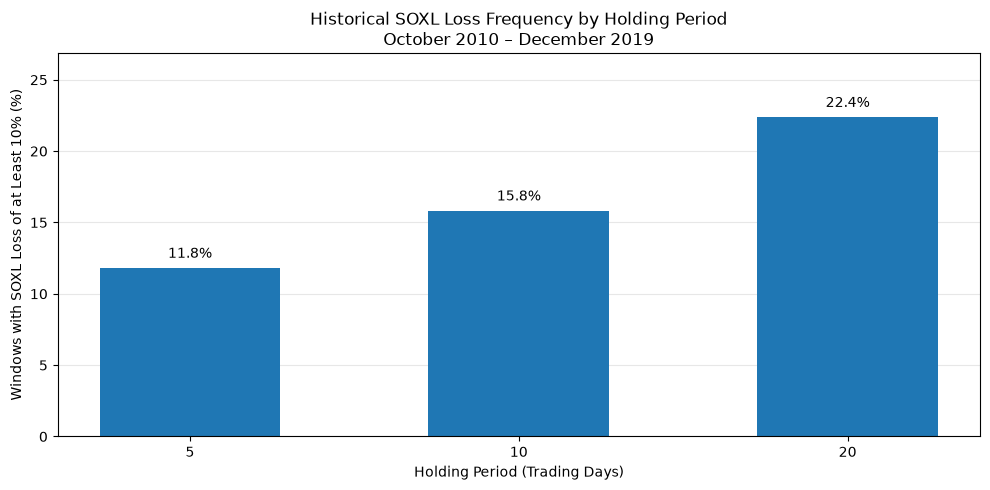

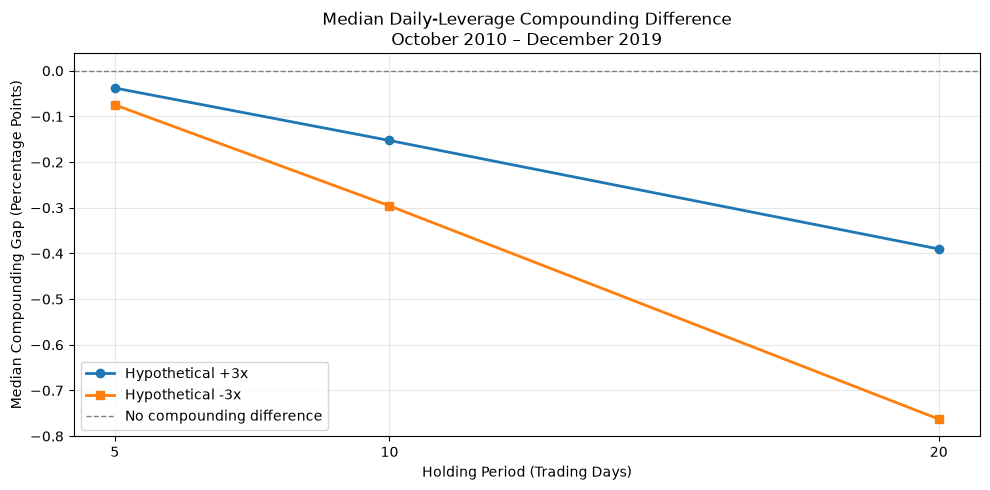

Rolling compounding visualizations generated successfully.


In [20]:

# ============================================================
# 2.5.5 — Visualizing Rolling Compounding
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Sort the summaries by holding period.
risk_plot = rolling_risk_summary.sort_values("Days").copy()
gap_plot = rolling_gap_summary.sort_values("Days").copy()

# ------------------------------------------------------------
# Chart 1 — Historical SOXL Loss Frequency
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    risk_plot["Days"].astype(str),
    risk_plot["SOXL Loss >=10% (%)"],
    width=0.55
)

# Display the observed percentage above each bar.
for bar in bars:

    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Historical SOXL Loss Frequency by Holding Period\n"
    "October 2010 – December 2019"
)

ax.set_xlabel("Holding Period (Trading Days)")
ax.set_ylabel("Windows with SOXL Loss of at Least 10% (%)")

ax.set_ylim(
    0,
    risk_plot["SOXL Loss >=10% (%)"].max() * 1.2
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Chart 2 — Median Hypothetical Compounding Gap
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    gap_plot["Days"],
    gap_plot["+3x Median Gap (pp)"],
    marker="o",
    linewidth=2,
    label="Hypothetical +3x"
)

ax.plot(
    gap_plot["Days"],
    gap_plot["-3x Median Gap (pp)"],
    marker="s",
    linewidth=2,
    label="Hypothetical -3x"
)

# Zero represents equality with the simple leverage multiple.
ax.axhline(
    y=0,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="No compounding difference"
)

ax.set_title(
    "Median Daily-Leverage Compounding Difference\n"
    "October 2010 – December 2019"
)

ax.set_xlabel("Holding Period (Trading Days)")
ax.set_ylabel("Median Compounding Gap (Percentage Points)")

ax.set_xticks(holding_periods)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Rolling compounding visualizations generated successfully.")



### 2.5.6 — Final Findings and Research Implications

#### Summary of Findings

Section 2.5 examined how daily returns compound and why daily leveraged investments can produce multi-day outcomes that differ from simple leverage multiples.

**1. Long-term cumulative growth**

Between October 18, 2010, and December 31, 2019, an initial investment of 100 USD grew to:

| Investment | Ending Value (USD) |
|---|---:|
| SOXX | 584.38 |
| SOXL | 3,603.94 |
| SOXS | 0.0210 |
| Hypothetical +3x daily SOXX | 4,462.56 |
| Hypothetical -3x daily SOXX | 0.0255 |

The leveraged investments experienced substantially larger changes than SOXX.

However, these outcomes reflect one particular historical period and do not imply equivalent future performance.

**2. Historical multi-day downside risk**

SOXL losses of at least 10% occurred in approximately:

- **11.8%** of five-day windows
- **15.8%** of ten-day windows
- **22.4%** of twenty-day windows

The lower tail of the return distribution became more negative at longer holding periods.

**3. Compounding differences**

The median compounding gap was negative for both hypothetical daily-leverage strategies across all three holding periods.

For hypothetical +3x leverage, the median gap changed from -0.038 percentage points over five days to -0.390 percentage points over twenty days.

For hypothetical -3x leverage, the corresponding median gap changed from -0.075 to -0.763 percentage points.

The negative gaps occurred in most, but not all, historical windows.

**4. Main research conclusion**

Daily compounding materially affects the relationship between leveraged ETF performance and underlying semiconductor-market returns over multiple days.

The historical analysis also shows that substantial short-term SOXL losses can occur even during a development period characterized by strong long-term sector growth.

These findings support studying downside risk at different holding periods instead of assuming that a strong daily leverage relationship provides a complete description of multi-day outcomes.

#### Limitations

- Rolling holding periods overlap and are not statistically independent.
- Historical frequencies are descriptive, not forecasts of future loss probabilities.
- The hypothetical leverage comparisons use SOXX, not necessarily the leveraged funds' exact historical benchmark.
- The analysis does not separately identify the contributions of volatility, benchmark differences, fund expenses, financing costs, or tracking effects to actual ETF performance.
- Findings are restricted to the 2010–2019 development period.
- No 2026 holdout observations were used.

#### Section Status

**Section 2.5 complete.** Numerical examples, historical cumulative returns, rolling holding-period comparisons, visualizations, and associated validation checks were completed and reviewed.

**Next: Section 2.6 — Drawdowns and Recovery**

We will investigate how far each ETF fell from its previous historical peak, how long those declines lasted, and whether the investment recovered its previous peak during the observation period.



## 2.6 — Drawdowns and Recovery

### 2.6.1 — Calculating Historical Drawdowns

#### Objective

Measure the historical peak-to-trough declines of SOXL, SOXS, and SOXX during the development period.

We will calculate each ETF's running investment peak, daily drawdown, and maximum observed drawdown.

Later, we will investigate the duration of drawdown episodes and whether previous peaks were recovered.

---

### 1. What Is a Drawdown?

A **drawdown** measures how far an investment has fallen from its highest previously observed value.

Unlike a fixed five-day or twenty-day return, a drawdown does not require a predetermined holding period.

Consider an investment with the following values:

| Trading Day | Investment Value (USD) |
|---|---:|
| Day 1 | 100 |
| Day 2 | 120 |
| Day 3 | 110 |
| Day 4 | 90 |
| Day 5 | 105 |

The investment reached a peak of 120 USD on Day 2.

By Day 4, its value declined to 90 USD.

The drawdown is:

$$
D=\left(\frac{90}{120}-1\right)\times100=-25\%
$$

The investment experienced a **25% drawdown** from its previous peak.

Notice that this differs from the return relative to the original 100 USD investment.

**Key distinction:** Drawdowns measure losses relative to previous peaks, not necessarily relative to the initial investment.

### 2. Running Peak Formula

The running peak is the highest investment value observed up to a given date:

$$
H_t=\max(V_0,V_1,\ldots,V_t)
$$

Where:

- $H_t$ = highest observed investment value up to day $t$
- $V_t$ = investment value on day $t$
- $\max$ = the largest value in the sequence

A running peak remains unchanged during a decline and increases when the investment reaches a new high.

In Python, we calculate it using:

`cummax()`

This pandas method records the highest value encountered so far.

### 3. Drawdown Formula

The daily drawdown percentage is:

$$
D_t=\left(\frac{V_t}{H_t}-1\right)\times100
$$

A drawdown of:

- **0%** means the investment is at its running peak.
- **-10%** means its value is 10% below that peak.
- **-50%** means half of its peak value has been lost.

Drawdowns are normally zero or negative.

### 4. Maximum Drawdown

**Maximum drawdown (MDD)** is the largest peak-to-trough percentage decline observed during the selected period.

$$
MDD=\min(D_0,D_1,\ldots,D_T)
$$

For example, if the observed drawdowns are 0%, -5%, -12%, -8%, and -20%, the maximum drawdown is **-20%**.

We report maximum drawdown as a negative return. Its absolute magnitude represents the percentage decline.

A larger negative value indicates a more severe historical decline.

### 5. Why Drawdowns Matter for SOXL

SOXL uses daily leverage, meaning losses can be considerably larger than those experienced by an unleveraged semiconductor ETF.

Drawdown analysis will help us investigate:

- How severely SOXL declined from previous investment peaks.
- How its historical declines compared with SOXX and SOXS.
- Whether periods of strong cumulative growth also contained substantial losses.
- How frequently the investments remained below their previous peaks.

These observations provide useful context for downside-risk analysis, although maximum drawdown is a retrospective measure, not a predictive model.

### 6. Methodology

We will reuse the actual ETF investment-value series from Section 2.5.2.

For consistency, the comparison covers **October 18, 2010, through December 31, 2019**.

Only observed SOXL, SOXS, and SOXX adjusted-price investment paths are used in this first analysis. We will not include hypothetical leveraged investments.

The first observation is treated as the initial observed peak. Drawdowns that began before our selected period cannot be measured fully.

The end of 2019 is also an observation boundary. An investment may remain underwater beyond this date, but later outcomes are not included in this exploratory comparison.


Historical ETF Drawdown Summary
Period: October 18, 2010 – December 31, 2019


,Maximum Drawdown (%),Peak Date,Trough Date,Peak-to-Trough (Trading Days),Ending Drawdown (%),Days Below Peak (%)
ETF,,,,,,
SOXX,-30.496,2011-02-17,2011-08-19,127,-0.680,88.822
SOXL,-72.606,2011-02-17,2011-10-03,157,-2.546,92.318
SOXS,-99.980,2010-10-19,2019-12-26,2312,-99.980,99.914



All historical drawdown validation checks passed.


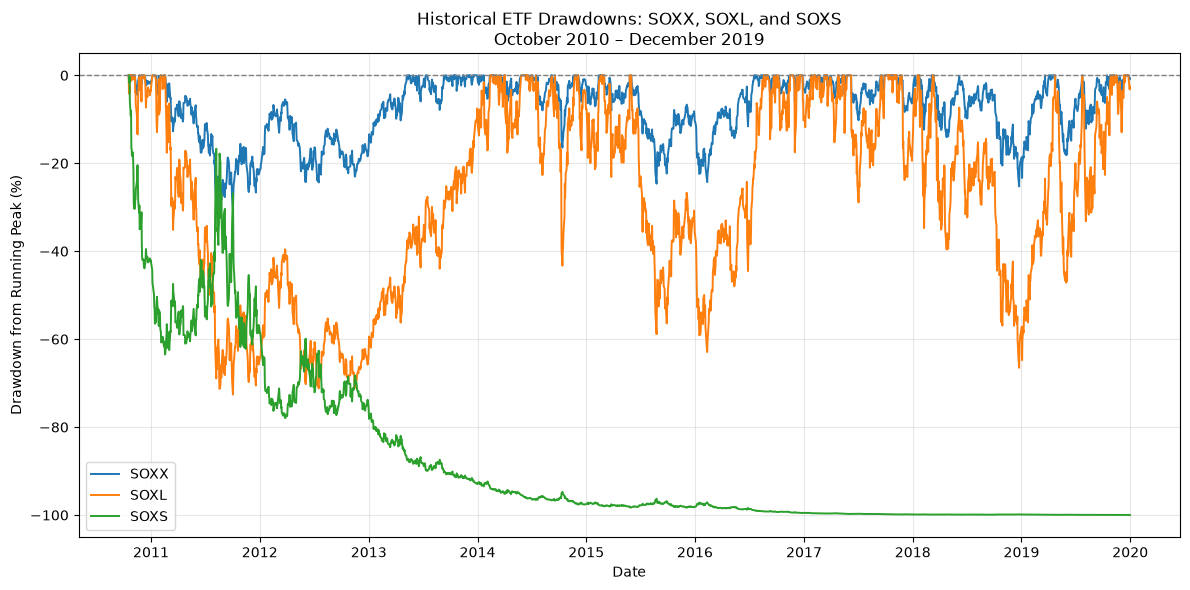

Historical drawdown chart generated successfully.


In [21]:

# ============================================================
# 2.6.1 — Historical Drawdown Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the actual ETF investment values from Section 2.5.
# Preserve the original compounding_history DataFrame.
drawdown_history = (
    compounding_history[
        [
            "Date",
            "SOXX Value (USD)",
            "SOXL Value (USD)",
            "SOXS Value (USD)"
        ]
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)

# Match each ticker to its investment-value column.
actual_etfs = {
    "SOXX": "SOXX Value (USD)",
    "SOXL": "SOXL Value (USD)",
    "SOXS": "SOXS Value (USD)"
}

drawdown_summary_rows = []

# ------------------------------------------------------------
# Part A — Calculate Running Peaks and Drawdowns
# ------------------------------------------------------------

for ticker, value_column in actual_etfs.items():

    # Find the highest investment value observed so far.
    peak_column = f"{ticker} Running Peak (USD)"

    drawdown_history[peak_column] = (
        drawdown_history[value_column].cummax()
    )

    # Measure percentage declines from previous peaks.
    drawdown_column = f"{ticker} Drawdown (%)"

    drawdown_history[drawdown_column] = (
        (
            drawdown_history[value_column]
            / drawdown_history[peak_column]
        ) - 1
    ) * 100

    # --------------------------------------------------------
    # Part B — Identify the Largest Historical Decline
    # --------------------------------------------------------

    # Find the row with the most negative drawdown.
    trough_index = (
        drawdown_history[drawdown_column].idxmin()
    )

    # Record the investment value and running peak there.
    trough_value = drawdown_history.loc[
        trough_index, value_column
    ]

    peak_value = drawdown_history.loc[
        trough_index, peak_column
    ]

    # Find the most recent occurrence of that previous peak.
    preceding_values = drawdown_history.loc[
        :trough_index, value_column
    ]

    peak_matches = np.flatnonzero(
        np.isclose(
            preceding_values.to_numpy(),
            peak_value,
            rtol=1e-10,
            atol=1e-9
        )
    )

    peak_index = int(peak_matches[-1])

    # Calculate the percentage of dates below their peaks.
    underwater_frequency = (
        (drawdown_history[drawdown_column] < -1e-9)
        .mean() * 100
    )

    drawdown_summary_rows.append({
        "ETF": ticker,
        "Maximum Drawdown (%)": (
            drawdown_history[drawdown_column].min()
        ),
        "Peak Date": drawdown_history.loc[
            peak_index, "Date"
        ],
        "Trough Date": drawdown_history.loc[
            trough_index, "Date"
        ],
        "Peak-to-Trough (Trading Days)": (
            trough_index - peak_index
        ),
        "Ending Drawdown (%)": (
            drawdown_history[drawdown_column].iloc[-1]
        ),
        "Days Below Peak (%)": underwater_frequency
    })

# ------------------------------------------------------------
# Part C — Create Summary Table
# ------------------------------------------------------------

historical_drawdown_summary = (
    pd.DataFrame(drawdown_summary_rows)
    .set_index("ETF")
)

print("Historical ETF Drawdown Summary")
print("Period: October 18, 2010 – December 31, 2019")

display(historical_drawdown_summary.round(3))

# ------------------------------------------------------------
# Part D — Validation
# ------------------------------------------------------------

for ticker, value_column in actual_etfs.items():

    peak_column = f"{ticker} Running Peak (USD)"
    drawdown_column = f"{ticker} Drawdown (%)"

    values = drawdown_history[value_column].to_numpy()
    peaks = drawdown_history[peak_column].to_numpy()
    drawdowns = drawdown_history[drawdown_column].to_numpy()

    # Investment values must be positive.
    assert (values > 0).all()

    # The running peak can never decrease.
    assert (np.diff(peaks) >= -1e-9).all()

    # Confirm running peaks using NumPy independently.
    np.testing.assert_allclose(
        peaks,
        np.maximum.accumulate(values)
    )

    # Confirm the drawdown calculation.
    expected_drawdowns = (
        values / np.maximum.accumulate(values) - 1
    ) * 100

    np.testing.assert_allclose(
        drawdowns,
        expected_drawdowns,
        rtol=1e-9,
        atol=1e-8
    )

    # Drawdowns cannot exceed zero.
    assert (drawdowns <= 1e-9).all()

    # Each series begins with a zero drawdown.
    assert abs(drawdowns[0]) < 1e-9

print("\nAll historical drawdown validation checks passed.")

# ------------------------------------------------------------
# Part E — Visualize Historical Drawdowns
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for ticker in actual_etfs:

    plt.plot(
        drawdown_history["Date"],
        drawdown_history[f"{ticker} Drawdown (%)"],
        label=ticker,
        linewidth=1.4
    )

plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Historical ETF Drawdowns: SOXX, SOXL, and SOXS\n"
    "October 2010 – December 2019"
)

plt.xlabel("Date")
plt.ylabel("Drawdown from Running Peak (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Historical drawdown chart generated successfully.")



#### Results and Interpretation

The analysis used 2,317 matched trading dates from October 18, 2010, through December 31, 2019.

| Metric | SOXX | SOXL | SOXS |
|---|---:|---:|---:|
| Maximum drawdown (%) | -30.496 | -72.606 | -99.980 |
| Peak-to-trough trading days | 127 | 157 | 2,312 |
| Ending drawdown (%) | -0.680 | -2.546 | -99.980 |
| Observed dates below peak (%) | 88.822 | 92.318 | 99.914 |

**1. SOXL experienced substantially deeper declines than SOXX.**

Both ETFs reached a previous peak on February 17, 2011. SOXX subsequently experienced a maximum drawdown of approximately 30.5%, compared with 72.6% for SOXL.

This illustrates how substantial downside exposure can accompany daily leverage.

**2. SOXS experienced a prolonged decline.**

SOXS reached its identified peak on October 19, 2010, and its maximum drawdown reached approximately 99.98% by December 26, 2019.

Its drawdown remained near 100% at the end of the observation period.

**3. Strong cumulative growth did not prevent large drawdowns.**

SOXL finished the historical comparison period substantially above its initial investment value, but it still experienced a maximum drawdown exceeding 70%.

SOXL was below its running peak on approximately 92.3% of the observed dates.

This demonstrates why cumulative returns alone are insufficient for evaluating historical investment risk.

**4. Methodological limitations**

- Maximum drawdown is a retrospective peak-to-trough measure.
- The identified maximum depends on the selected observation period.
- The reported peak-to-trough duration does not measure recovery time.
- The percentage of dates below a running peak does not tell us how many distinct drawdown episodes occurred.
- A drawdown still active at the end of 2019 has an unobserved recovery date within this sample.

**Next:** Identify individual drawdown episodes, measure completed recovery durations, and distinguish unresolved declines from recovered episodes.



### 2.6.2 — Drawdown Episodes and Recovery Duration

#### Objective

Identify individual historical drawdown episodes for SOXX, SOXL, and SOXS.

For each episode, determine the peak, trough, recovery date (if observed), and the number of trading days required for recovery.

---

### 1. What Is a Drawdown Episode?

A drawdown episode begins when an investment falls below its previous running peak.

It ends when the investment returns to or exceeds that peak.

For example:

| Trading Day | Investment Value (USD) | Event |
|---|---:|---|
| Day 1 | 100 | Initial value |
| Day 2 | 120 | New peak |
| Day 3 | 105 | Drawdown begins |
| Day 4 | 90 | Trough |
| Day 5 | 110 | Partial recovery |
| Day 6 | 120 | Full recovery |

In this example:

- **Peak:** 120 USD on Day 2.
- **Trough:** 90 USD on Day 4.
- **Maximum episode depth:** -25%.
- **Peak to trough:** 2 trading-day intervals.
- **Trough to recovery:** 2 trading-day intervals.
- **Peak to full recovery:** 4 trading-day intervals.

The investment has recovered only when it reaches its previous peak of 120 USD.

Returning to its original investment value of 100 USD would not count as full recovery.

### 2. Measuring Recovery Duration

We will calculate three measurements.

**Peak-to-trough duration**

The number of trading-day intervals between the previous peak and the lowest investment value during the episode.

**Trough-to-recovery duration**

The number of trading-day intervals between the episode's lowest value and the first subsequent date when the previous peak is recovered.

**Peak-to-recovery duration**

The total number of trading-day intervals between the previous peak and the recovery date.

For a completed drawdown episode:

$$
T_{\mathrm{total}}=T_{\mathrm{decline}}+T_{\mathrm{recovery}}
$$

These durations measure trading-day intervals, not calendar days.

### 3. What If an Investment Never Recovers?

Some investments may remain below their previous peaks at the end of the observation period.

These episodes are **open at the cutoff**.

For an open episode:

- We can identify its observed peak and trough.
- We can measure how long the investment has remained underwater.
- We cannot calculate its completed recovery duration.

The recovery duration must be recorded as **missing (`NaN`)**, not zero.

This is an example of **right-censoring**: the observation period ends before the event we are measuring occurs.

Importantly, an unobserved recovery within our sample does not prove that the investment will never recover.

### 4. Python Approach

We will examine the ETF investment values chronologically.

For each ETF, the code will:

1. Track the latest running peak.
2. Identify when the investment falls below that peak.
3. Track the lowest value reached during the episode.
4. Detect the first subsequent recovery to the previous peak.
5. Record the completed episode or identify it as open at the cutoff.

We will then summarize completed recovery durations separately from unresolved episodes.

Because long unresolved declines are excluded from completed-recovery statistics, the median completed recovery duration should not be interpreted as the typical recovery time for every drawdown.

### 5. Research Limitations

- The analysis begins in October 2010, so earlier drawdown history is unavailable.
- Episodes still open on December 31, 2019 are right-censored.
- Trading-day durations exclude weekends and market holidays.
- Short and shallow drawdowns are included; no minimum depth threshold has been imposed.
- Recovery statistics describe historical investment paths and do not predict future recovery times.


In [22]:

# ============================================================
# 2.6.2 — Drawdown Episodes and Recovery Duration
# ============================================================

episode_records = []

dates = pd.to_datetime(drawdown_history["Date"]).reset_index(drop=True)

for ticker, value_column in actual_etfs.items():

    values = drawdown_history[value_column].to_numpy()

    # Begin with the first investment value as the peak.
    peak_index = 0
    peak_value = values[0]

    # No drawdown is active at the start.
    in_drawdown = False
    trough_index = None

    for i in range(1, len(values)):

        current_value = values[i]

        # ----------------------------------------------------
        # Case 1 — No active drawdown
        # ----------------------------------------------------

        if not in_drawdown:

            if current_value >= peak_value:

                # A new high (or equal high) resets the peak.
                peak_index = i
                peak_value = current_value

            else:

                # The investment has fallen below its peak.
                in_drawdown = True
                trough_index = i

        # ----------------------------------------------------
        # Case 2 — An active drawdown exists
        # ----------------------------------------------------

        else:

            # Update the trough if a lower value is reached.
            if current_value < values[trough_index]:
                trough_index = i

            # Check whether the previous peak was recovered.
            if current_value >= peak_value:

                episode_records.append({
                    "ETF": ticker,
                    "Status": "Recovered",
                    "Peak Date": dates.iloc[peak_index],
                    "Trough Date": dates.iloc[trough_index],
                    "Recovery Date": dates.iloc[i],

                    "Depth (%)": (
                        values[trough_index] / peak_value - 1
                    ) * 100,

                    "Peak to Trough (Days)": (
                        trough_index - peak_index
                    ),

                    "Trough to Recovery (Days)": (
                        i - trough_index
                    ),

                    "Peak to Recovery (Days)": (
                        i - peak_index
                    ),

                    "Underwater Dates Observed": (
                        i - peak_index - 1
                    ),

                    # Indices retained for validation.
                    "Peak Index": peak_index,
                    "Trough Index": trough_index,
                    "Recovery Index": i
                })

                # Recovery ends the current episode.
                in_drawdown = False
                peak_index = i
                peak_value = current_value
                trough_index = None

    # --------------------------------------------------------
    # Case 3 — Drawdown still open at the historical cutoff
    # --------------------------------------------------------

    if in_drawdown:

        episode_records.append({
            "ETF": ticker,
            "Status": "Open at cutoff",
            "Peak Date": dates.iloc[peak_index],
            "Trough Date": dates.iloc[trough_index],
            "Recovery Date": pd.NaT,

            "Depth (%)": (
                values[trough_index] / peak_value - 1
            ) * 100,

            "Peak to Trough (Days)": (
                trough_index - peak_index
            ),

            # No recovery occurred inside the sample.
            "Trough to Recovery (Days)": np.nan,
            "Peak to Recovery (Days)": np.nan,

            "Underwater Dates Observed": (
                len(values) - 1 - peak_index
            ),

            "Peak Index": peak_index,
            "Trough Index": trough_index,
            "Recovery Index": np.nan
        })

# Store all recovered and unresolved episodes.
drawdown_episodes = pd.DataFrame(episode_records)

# ------------------------------------------------------------
# Part B — Summarize Recovery Durations
# ------------------------------------------------------------

recovery_summary_rows = []

for ticker in actual_etfs:

    ticker_episodes = drawdown_episodes[
        drawdown_episodes["ETF"] == ticker
    ]

    completed = ticker_episodes[
        ticker_episodes["Status"] == "Recovered"
    ]

    open_episodes = ticker_episodes[
        ticker_episodes["Status"] == "Open at cutoff"
    ]

    recovery_summary_rows.append({
        "ETF": ticker,
        "Recovered Episodes": len(completed),
        "Open Episodes": len(open_episodes),

        "Median Completed Recovery (Days)": (
            completed["Peak to Recovery (Days)"].median()
        ),

        "Longest Completed Recovery (Days)": (
            completed["Peak to Recovery (Days)"].max()
        ),

        "Current Underwater Dates": (
            open_episodes["Underwater Dates Observed"].max()
            if len(open_episodes) > 0 else 0
        )
    })

recovery_summary = (
    pd.DataFrame(recovery_summary_rows)
    .set_index("ETF")
)

print("Historical Drawdown Recovery Summary")
display(recovery_summary.round(2))

# ------------------------------------------------------------
# Part C — Examine the Worst Drawdown Episode for Each ETF
# ------------------------------------------------------------

worst_episodes = (
    drawdown_episodes
    .loc[drawdown_episodes.groupby("ETF")["Depth (%)"].idxmin()]
    .set_index("ETF")
)

worst_episode_columns = [
    "Peak Date",
    "Trough Date",
    "Recovery Date",
    "Depth (%)",
    "Status",
    "Peak to Recovery (Days)"
]

print("\nRecovery Status of Each ETF's Maximum Drawdown")
display(worst_episodes[worst_episode_columns].round(3))

# ------------------------------------------------------------
# Part D — Validation
# ------------------------------------------------------------

for ticker, value_column in actual_etfs.items():

    ticker_episodes = drawdown_episodes[
        drawdown_episodes["ETF"] == ticker
    ]

    values = drawdown_history[value_column].to_numpy()

    # At most one episode can remain open at the cutoff.
    assert (
        (ticker_episodes["Status"] == "Open at cutoff").sum()
        <= 1
    )

    for _, episode in ticker_episodes.iterrows():

        peak_i = int(episode["Peak Index"])
        trough_i = int(episode["Trough Index"])

        assert peak_i < trough_i

        # Independently calculate each episode's depth.
        expected_depth = (
            values[trough_i] / values[peak_i] - 1
        ) * 100

        np.testing.assert_allclose(
            episode["Depth (%)"],
            expected_depth,
            atol=1e-8
        )

        if episode["Status"] == "Recovered":

            recovery_i = int(episode["Recovery Index"])

            # Recovery must follow the trough.
            assert recovery_i > trough_i

            # Recovered value must meet or exceed old peak.
            assert values[recovery_i] >= values[peak_i]

            # Verify that the total duration is consistent.
            assert (
                episode["Peak to Recovery (Days)"]
                ==
                episode["Peak to Trough (Days)"]
                + episode["Trough to Recovery (Days)"]
            )

        else:

            # Open episodes must not have a recovery date.
            assert pd.isna(episode["Recovery Date"])
            assert pd.isna(
                episode["Peak to Recovery (Days)"]
            )

    # The deepest episode must match Section 2.6.1.
    expected_mdd = historical_drawdown_summary.loc[
        ticker, "Maximum Drawdown (%)"
    ]

    actual_mdd = ticker_episodes["Depth (%)"].min()

    np.testing.assert_allclose(
        actual_mdd,
        expected_mdd,
        atol=1e-8
    )

print("\nAll drawdown episode and recovery checks passed.")


Historical Drawdown Recovery Summary


,Recovered Episodes,Open Episodes,Median Completed Recovery (Days),Longest Completed Recovery (Days),Current Underwater Dates
ETF,,,,,
SOXX,107,1,4.0,558.0,3
SOXL,74,1,4.5,751.0,3
SOXS,0,1,NaN,NaN,2315



Recovery Status of Each ETF's Maximum Drawdown


,Peak Date,Trough Date,Recovery Date,Depth (%),Status,Peak to Recovery (Days)
ETF,,,,,,
SOXL,2011-02-17,2011-10-03,2014-02-13,-72.606,Recovered,751.0
SOXS,2010-10-19,2019-12-26,NaT,-99.980,Open at cutoff,NaN
SOXX,2011-02-17,2011-08-19,2013-05-09,-30.496,Recovered,558.0



All drawdown episode and recovery checks passed.



#### Results and Interpretation

The analysis identified individual drawdown episodes for SOXX, SOXL, and SOXS between October 2010 and December 2019.

| Metric | SOXX | SOXL | SOXS |
|---|---:|---:|---:|
| Recovered episodes | 107 | 74 | 0 |
| Open episodes at cutoff | 1 | 1 | 1 |
| Median completed peak-to-recovery (days) | 4.0 | 4.5 | N/A |
| Longest completed peak-to-recovery (days) | 558 | 751 | N/A |

All durations are measured in trading-day intervals.

**1. SOXL's worst drawdown required a prolonged recovery.**

SOXL declined approximately 72.6% from its February 17, 2011 peak to its October 3, 2011 trough.

The investment did not recover that previous peak until February 13, 2014.

The complete peak-to-recovery period lasted **751 trading days**.

SOXX's worst drawdown was smaller at approximately 30.5%, and its recovery took 558 trading days.

**2. Most completed episodes recovered relatively quickly.**

The median completed peak-to-recovery duration was 4 trading days for SOXX and 4.5 trading days for SOXL.

However, these medians include many small drawdowns.

They should not be interpreted as typical recovery times following major losses.

**3. SOXS had no completed recovery episodes.**

SOXS remained below its October 19, 2010 peak through the end of 2019.

Its open drawdown episode had lasted 2,315 trading-day intervals by the cutoff.

The completed recovery duration is therefore missing, not zero.

**4. Unresolved episodes require separate treatment.**

Each ETF had one episode still open on December 31, 2019.

Recovery statistics calculated only from completed episodes exclude these unresolved declines and may understate the duration associated with severe drawdowns.

#### Research Implication

Historical cumulative returns and maximum drawdowns alone do not fully describe investment risk.

Recovery duration provides additional information about how long an investment can remain below a previous peak.

The large difference between median and longest recovery durations suggests that drawdown severity should be considered when comparing recovery behaviour.

**Next:** Classify drawdown episodes by severity and examine recovery durations for more substantial historical declines.



### 2.6.3 — Drawdown Severity and Recovery

#### Objective

Investigate whether the recovery durations of historical drawdowns differ according to the severity of the decline.

The previous section found that most completed drawdowns recovered quickly, but the longest recoveries lasted hundreds of trading days.

We will separate shallow drawdowns from more substantial losses.

#### 1. Classifying Drawdown Severity

We classify episodes using their maximum observed peak-to-trough decline.

| Category | Drawdown Magnitude |
|---|---|
| Shallow | Less than 10% |
| Moderate | 10% to less than 20% |
| Severe | At least 20% |

For example, a drawdown of -25% belongs to the severe category.

These thresholds are exploratory groupings. They do not represent regulatory classifications or optimized forecasting thresholds.

#### 2. Measuring Recovery by Severity

For each ETF and category, we will calculate:

- Total number of observed episodes.
- Number of completed recoveries.
- Number still open at the historical cutoff.
- Median peak-to-recovery duration among completed episodes.
- Longest completed peak-to-recovery duration.

We will also visualize completed episodes with drawdowns of at least 10%.

This allows us to examine how recovery durations vary across observed drawdown depths.

#### 3. Important Limitations

Recovery durations are calculated only for completed episodes.

Open episodes will remain visible in the summary counts but will not be assigned an invented recovery duration.

The most severe declines may also be among the longest unresolved episodes. Consequently, completed-recovery statistics alone can give an overly optimistic picture.

The analysis describes historical associations, not a causal relationship between severity and recovery duration.

No observations outside the 2010–2019 development period are used.


Drawdown Recovery by Severity


Total Episodes  Recovered  Open  \
ETF  Severity                                              
SOXX Shallow (<10%)                 100         99     1   
     Moderate (10–<20%)               5          5     0   
     Severe (>=20%)                   3          3     0   
SOXL Shallow (<10%)                  53         52     1   
     Moderate (10–<20%)              10         10     0   
     Severe (>=20%)                  12         12     0   
SOXS Shallow (<10%)                   0          0     0   
     Moderate (10–<20%)               0          0     0   
     Severe (>=20%)                   1          0     1   

                         Median Recovery (Days)  Longest Recovery (Days)  
ETF  Severity                                                             
SOXX Shallow (<10%)                         4.0                     60.0  
     Moderate (10–<20%)                    58.0                     69.0  
     Severe (>=20%)                       285.0                    558.0  
SOXL Shallow (<10%)                         3.0                     18.0  
     Moderate (10–<20%)                    15.5                     40.0  
     Severe (>=20%)                        61.5                    751.0  
SOXS Shallow (<10%)                         NaN                      NaN  
     Moderate (10–<20%)                     NaN                      NaN  
     Severe (>=20%)                         NaN                      NaN

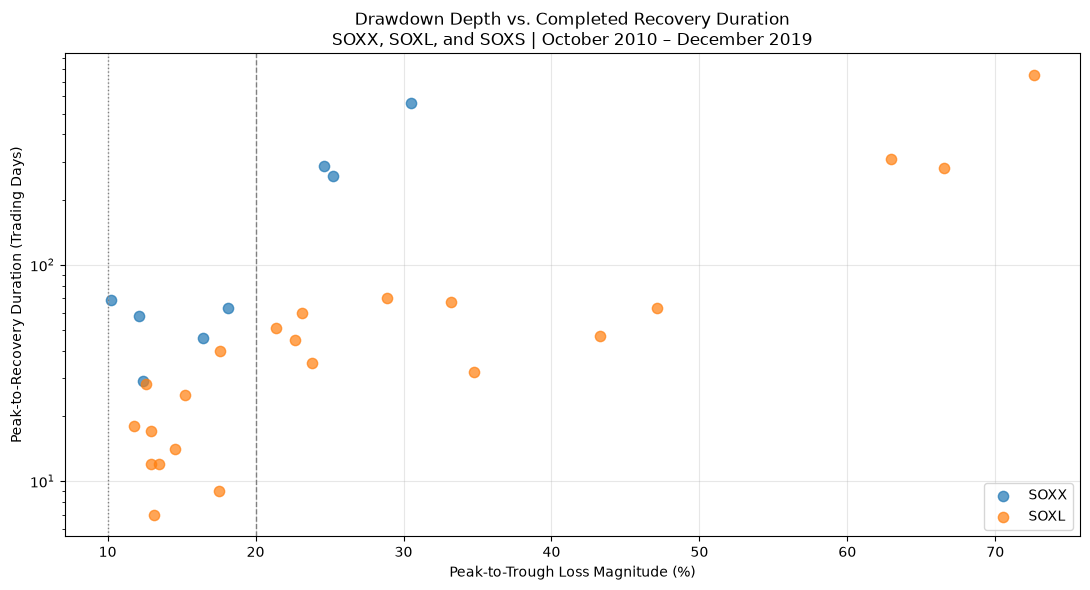

Completed substantial drawdowns plotted: 30
Open episodes excluded from the recovery-duration chart: 3

All drawdown severity validation checks passed.


In [23]:

# ============================================================
# 2.6.3 — Drawdown Severity and Recovery
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preserve the original drawdown episode data.
severity_episodes = drawdown_episodes.copy()

# Convert negative drawdowns into positive loss magnitudes.
# Example: -25% drawdown becomes a magnitude of 25%.
severity_episodes["Loss Magnitude (%)"] = (
    -severity_episodes["Depth (%)"]
)

# Classify each observed episode.
severity_episodes["Severity"] = pd.cut(
    severity_episodes["Loss Magnitude (%)"],
    bins=[0, 10, 20, np.inf],
    labels=[
        "Shallow (<10%)",
        "Moderate (10–<20%)",
        "Severe (>=20%)"
    ],
    right=False
)

# ------------------------------------------------------------
# Part A — Recovery Summary by Severity
# ------------------------------------------------------------

severity_rows = []

severity_categories = [
    "Shallow (<10%)",
    "Moderate (10–<20%)",
    "Severe (>=20%)"
]

for ticker in ["SOXX", "SOXL", "SOXS"]:

    for category in severity_categories:

        subset = severity_episodes[
            (severity_episodes["ETF"] == ticker)
            & (severity_episodes["Severity"] == category)
        ]

        recovered = subset[
            subset["Status"] == "Recovered"
        ]

        open_episodes = subset[
            subset["Status"] == "Open at cutoff"
        ]

        severity_rows.append({
            "ETF": ticker,
            "Severity": category,
            "Total Episodes": len(subset),
            "Recovered": len(recovered),
            "Open": len(open_episodes),
            "Median Recovery (Days)": (
                recovered["Peak to Recovery (Days)"].median()
            ),
            "Longest Recovery (Days)": (
                recovered["Peak to Recovery (Days)"].max()
            )
        })

severity_recovery_summary = pd.DataFrame(severity_rows)

print("Drawdown Recovery by Severity")
display(
    severity_recovery_summary
    .set_index(["ETF", "Severity"])
    .round(2)
)

# ------------------------------------------------------------
# Part B — Validate Episode Classification
# ------------------------------------------------------------

# Every episode must belong to exactly one severity category.
assert severity_episodes["Severity"].notna().all()

for ticker in actual_etfs:

    original = drawdown_episodes[
        drawdown_episodes["ETF"] == ticker
    ]

    summary = severity_recovery_summary[
        severity_recovery_summary["ETF"] == ticker
    ]

    # Categories must account for every original episode.
    assert summary["Total Episodes"].sum() == len(original)

    # Completed and open counts must match the original data.
    assert summary["Recovered"].sum() == (
        original["Status"] == "Recovered"
    ).sum()

    assert summary["Open"].sum() == (
        original["Status"] == "Open at cutoff"
    ).sum()

# ------------------------------------------------------------
# Part C — Visualize Substantial Completed Drawdowns
# ------------------------------------------------------------

# Only plot completed episodes with losses of at least 10%.
# Unresolved episodes are excluded from the scatterplot.
substantial_recoveries = severity_episodes[
    (severity_episodes["Status"] == "Recovered")
    & (severity_episodes["Loss Magnitude (%)"] >= 10)
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

for ticker in ["SOXX", "SOXL", "SOXS"]:

    subset = substantial_recoveries[
        substantial_recoveries["ETF"] == ticker
    ]

    if len(subset) == 0:
        continue

    ax.scatter(
        subset["Loss Magnitude (%)"],
        subset["Peak to Recovery (Days)"],
        label=ticker,
        alpha=0.7,
        s=55
    )

# Distinguish the severity boundaries.
ax.axvline(
    x=10,
    color="gray",
    linestyle=":",
    linewidth=1
)

ax.axvline(
    x=20,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Drawdown Depth vs. Completed Recovery Duration\n"
    "SOXX, SOXL, and SOXS | October 2010 – December 2019"
)

ax.set_xlabel("Peak-to-Trough Loss Magnitude (%)")
ax.set_ylabel("Peak-to-Recovery Duration (Trading Days)")

# Log scaling makes both short and long recoveries visible.
ax.set_yscale("log")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print(
    "Completed substantial drawdowns plotted:",
    len(substantial_recoveries)
)

print(
    "Open episodes excluded from the recovery-duration chart:",
    (severity_episodes["Status"] == "Open at cutoff").sum()
)

print("\nAll drawdown severity validation checks passed.")



### 2.6.4 — Final Findings and Research Implications

#### Summary of Findings

Section 2.6 examined historical drawdown magnitude, peak-to-recovery duration, and differences in recovery behaviour across drawdown severity categories.

**1. Maximum historical drawdowns**

| ETF | Maximum Drawdown | Peak-to-Recovery Duration |
|---|---:|---:|
| SOXX | -30.496% | 558 trading days |
| SOXL | -72.606% | 751 trading days |
| SOXS | -99.980% | Not recovered by cutoff |

SOXL experienced a substantially deeper maximum drawdown than SOXX. Its worst decline began from a February 17, 2011 peak and did not fully recover until February 13, 2014.

SOXS remained below its identified historical peak through December 31, 2019.

**2. Recovery duration depends on which episodes we examine**

SOXL's median completed peak-to-recovery duration was 4.5 trading days across all recovered episodes.

However, separating episodes by maximum drawdown severity revealed substantial differences:

| SOXL Drawdown Severity | Completed Episodes | Median Recovery (Trading Days) |
|---|---:|---:|
| Shallow (less than 10%) | 52 | 3.0 |
| Moderate (10% to less than 20%) | 10 | 15.5 |
| Severe (20% or more) | 12 | 61.5 |

The median duration increased with drawdown severity among SOXL's completed episodes.

This indicates that the overall recovery median is strongly influenced by numerous shallow, short-lived declines.

**3. Comparison with SOXX**

SOXX experienced only 3 severe completed drawdown episodes, compared with 12 for SOXL.

The median completed recovery duration for severe SOXX episodes was 285 trading days, compared with 61.5 trading days for SOXL.

This does not establish that SOXL generally recovers faster from severe losses. The samples contain different episodes and are small, especially for SOXX.

**4. Unresolved declines**

Three drawdown episodes remained open at the December 2019 cutoff: one for each ETF.

SOXS's unresolved episode was particularly substantial, having lasted 2,315 trading-day intervals.

These episodes were excluded from completed-recovery duration calculations because their eventual recovery dates were not observed.

#### Research Implications

The analysis demonstrates why cumulative performance alone is insufficient for evaluating leveraged ETF risk.

SOXL experienced strong long-term growth but also severe historical losses and prolonged recovery periods.

Recovery behaviour varied considerably across drawdown severity categories. This provides additional historical context for evaluating near-term downside risk and the persistence of investment losses.

#### Limitations

- Maximum drawdowns depend on the selected historical period.
- Completed-recovery summaries exclude right-censored episodes.
- Severity categories are descriptive, not optimized risk thresholds.
- Small samples of severe episodes limit broader conclusions.
- Recovery durations are retrospective and do not establish future recovery probabilities.
- The analysis uses only the 2010–2019 development period.

#### Section Status

**Section 2.6 analytical work completed and individually validated.**

The section includes running-peak calculations, maximum drawdown comparisons, recovery-episode detection, severity classifications, charts, and validation checks.

Final clean-kernel reproducibility verification remains outstanding until Stage 2 closeout.

**Next: Section 2.7 — Semiconductor Sector Context.**



## 2.7 — Semiconductor Sector Context

### 2.7.1 — Comparing SOXX and NASDAQSOX

#### Objective

Examine how two semiconductor-sector market measures behaved during the development period.

The goal is to understand whether SOXX and NASDAQSOX capture similar broad semiconductor-market movements and identify important differences between them.

---

### 1. Understanding Our Sector References

**SOXX — iShares Semiconductor ETF**

SOXX is an exchange-traded fund providing exposure to semiconductor companies.

We use its dividend-adjusted historical prices to calculate investment returns.

**NASDAQSOX — PHLX Semiconductor Sector Index**

NASDAQSOX is a semiconductor-sector index series retrieved from the Federal Reserve Economic Data (FRED) database.

It provides another measure of historical semiconductor-market movements.

Unlike SOXX, it is an index rather than an investable ETF.

#### Why Compare Them?

Although both measure semiconductor-sector activity, they are not identical.

Differences may arise from:

- Index composition and weighting methodologies.
- Historical benchmark changes.
- ETF fees and operating expenses.
- Dividends and the use of adjusted ETF prices.
- Differences between an index calculation and an actual investment product.

Therefore, we should not expect their daily returns to match exactly.

### 2. Research Period

We will compare SOXX and NASDAQSOX from **October 18, 2010, through December 31, 2019**.

This start date is consistent with the SOXX predecessor-history restriction applied in Section 2.4.

Our full development dataset begins earlier, but the pre-transition SOXX history is excluded from this direct comparison.

### 3. Calculating Daily Returns

We calculate daily percentage returns using:

$$
r_t=\left(\frac{P_t}{P_{t-1}}-1\right)\times100
$$

Where:

- $P_t$ = the current observed price or index level
- $P_{t-1}$ = the previous observed price or index level
- $r_t$ = daily percentage return

For example, an index increasing from 1,000 to 1,020 has a daily return of:

$$
r_t=\left(\frac{1020}{1000}-1\right)\times100=2\%
$$

We calculate these returns separately for SOXX and NASDAQSOX.

### 4. Measuring Their Relationship

We will compare:

- Average daily percentage returns.
- Daily return standard deviations.
- Contemporaneous Pearson return correlation.
- Average absolute daily difference in percentage points.

**Pearson correlation** measures how strongly two variables move together in a linear relationship.

Values range from -1 to +1.

- Near +1: strong positive linear relationship.
- Near 0: little linear relationship.
- Near -1: strong negative linear relationship.

A high correlation does not mean the two investments have identical returns or that one predicts the other.

### 5. Python Methods

We will use:

- `.pct_change(fill_method=None)` to calculate daily returns.
- `.std()` to calculate the sample standard deviation.
- `.corr()` to measure Pearson correlation.
- `.abs()` to measure the magnitude of return differences.
- `.mean()` to calculate averages.

The first date will not have a valid return within our selected comparison period because its preceding date is outside that period.

### 6. Methodological Limitations

SOXX adjusted-price returns and NASDAQSOX index-level changes are not identical return concepts.

For example, adjusted ETF prices incorporate dividend-related adjustments, whereas an index-level series may be price-based.

NASDAQSOX is also not assumed to be the exact official leveraged-fund benchmark across every historical regime.

The comparison is descriptive and restricted to the development period. It does not establish predictive value or benchmark tracking accuracy.


In [24]:

# ============================================================
# 2.7.1 — Semiconductor Sector Context
# SOXX vs. NASDAQSOX | October 2010 – December 2019
# ============================================================

# Reuse our existing development-period dataset.
# Keep the original DataFrame unchanged.

sector_context = (
    development.loc[
        (development["Date"] >= "2010-10-18")
        & (development["Date"] <= "2019-12-31"),
        ["Date", "SOXX", "NASDAQSOX"]
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# Part A — Validate Date Alignment and Source Values
# ------------------------------------------------------------

assert not sector_context.empty
assert sector_context["Date"].is_unique
assert sector_context["Date"].is_monotonic_increasing

assert sector_context["SOXX"].notna().all()
assert sector_context["NASDAQSOX"].notna().all()

# Prices and index levels should be strictly positive.
assert (sector_context[["SOXX", "NASDAQSOX"]] > 0).all().all()

# Dates must match the earlier historical comparison.
assert sector_context["Date"].equals(
    compounding_history["Date"].reset_index(drop=True)
)

print("Sector Context — Data Alignment")
print("First date:", sector_context["Date"].min().date())
print("Last date:", sector_context["Date"].max().date())
print("Matched price dates:", len(sector_context))

# ------------------------------------------------------------
# Part B — Calculate Daily Percentage Returns
# ------------------------------------------------------------

for measure in ["SOXX", "NASDAQSOX"]:

    sector_context[f"{measure} Return (%)"] = (
        sector_context[measure]
        .pct_change(fill_method=None) * 100
    )

sector_return_columns = [
    "SOXX Return (%)",
    "NASDAQSOX Return (%)"
]

# Remove only rows lacking a valid daily return.
sector_returns = (
    sector_context.dropna(subset=sector_return_columns)
    .copy()
)

print("\nValid daily return observations:", len(sector_returns))

# ------------------------------------------------------------
# Part C — Compare Historical Daily Returns
# ------------------------------------------------------------

sector_return_summary = pd.DataFrame({
    "Mean Daily Return (%)": (
        sector_returns[sector_return_columns].mean()
    ),
    "Daily Std. Dev. (%)": (
        sector_returns[sector_return_columns].std()
    ),
    "Minimum Daily Return (%)": (
        sector_returns[sector_return_columns].min()
    ),
    "Maximum Daily Return (%)": (
        sector_returns[sector_return_columns].max()
    )
})

print("\nSemiconductor Sector Daily Return Summary")
display(sector_return_summary.round(4))

# Measure their same-day linear relationship.
sector_correlation = sector_returns[
    "SOXX Return (%)"
].corr(
    sector_returns["NASDAQSOX Return (%)"]
)

# Difference measured in percentage points.
sector_returns["SOXX minus NASDAQSOX (pp)"] = (
    sector_returns["SOXX Return (%)"]
    - sector_returns["NASDAQSOX Return (%)"]
)

mean_absolute_difference = (
    sector_returns["SOXX minus NASDAQSOX (pp)"]
    .abs()
    .mean()
)

print("\nSame-Day Pearson Correlation:",
      round(sector_correlation, 4))

print("Mean Absolute Daily Return Difference (pp):",
      round(mean_absolute_difference, 4))

# ------------------------------------------------------------
# Part D — Independent Validation
# ------------------------------------------------------------

# We lose exactly one return when beginning a new price series.
assert len(sector_returns) == len(sector_context) - 1

# Reconstructed SOXX returns must match those from
# our existing leverage-comparison dataset after the
# common starting price date.
np.testing.assert_allclose(
    sector_returns["SOXX Return (%)"].to_numpy(),
    leverage_comparison["SOXX Return (%)"].iloc[1:].to_numpy(),
    rtol=1e-9,
    atol=1e-8
)

# All calculated daily returns must be finite.
assert np.isfinite(
    sector_returns[sector_return_columns].to_numpy()
).all()

# Correlation must lie between -1 and +1.
assert -1 <= sector_correlation <= 1

# The absolute daily return difference cannot be negative.
assert mean_absolute_difference >= 0

print("\nAll semiconductor sector comparison checks passed.")


Sector Context — Data Alignment
First date: 2010-10-18
Last date: 2019-12-31
Matched price dates: 2317

Valid daily return observations: 2316

Semiconductor Sector Daily Return Summary


,Mean Daily Return (%),Daily Std. Dev. (%),Minimum Daily Return (%),Maximum Daily Return (%)
SOXX Return (%),0.0869,1.460,-6.8920,6.0000
NASDAQSOX Return (%),0.0823,1.481,-6.8942,5.8703



Same-Day Pearson Correlation: 0.9984
Mean Absolute Daily Return Difference (pp): 0.0596

All semiconductor sector comparison checks passed.



#### Results and Interpretation

The comparison used 2,317 matched price dates and 2,316 valid daily returns between October 18, 2010, and December 31, 2019.

| Metric | SOXX | NASDAQSOX |
|---|---:|---:|
| Mean daily return (%) | 0.0869 | 0.0823 |
| Daily standard deviation (%) | 1.460 | 1.481 |
| Minimum daily return (%) | -6.8920 | -6.8942 |
| Maximum daily return (%) | 6.0000 | 5.8703 |

**1. Strong daily-return relationship**

The same-day Pearson correlation between SOXX and NASDAQSOX was **0.9984**, indicating an exceptionally strong positive linear relationship.

Their daily returns generally moved in the same direction and by similar magnitudes.

**2. Similar historical volatility**

SOXX had a daily return standard deviation of 1.460%, compared with 1.481% for NASDAQSOX.

The two measures therefore exhibited similar historical daily volatility during the comparison period.

**3. Differences remained**

The mean absolute daily return difference was **0.0596 percentage points**.

Although their relationship was strong, the two return series were not identical.

Differences may reflect index construction, historical benchmark changes, ETF expenses, and the distinction between dividend-adjusted ETF prices and index levels.

#### Research Implication

SOXX and NASDAQSOX provided closely related measures of semiconductor-sector movements during the development period.

This supports their use as sector-context variables in the broader analysis.

However, their high contemporaneous correlation does not establish forecasting power, independence between the indicators, or equivalence to the leveraged funds' exact underlying benchmarks.

**Next:** Compare their normalized historical growth and visualize their daily-return relationship.



### 2.7.2 — Visualizing Semiconductor-Sector Relationships

#### Objective

Visualize how SOXX and NASDAQSOX moved over time and examine the strength of their historical daily-return relationship.

We will create two charts using the validated development-period data.

---

### 1. Normalized Historical Growth

SOXX and NASDAQSOX have different starting price and index levels.

To compare their historical movements on the same chart, we will normalize both series to a starting value of **100**.

The normalization formula is:

$$
I_t=\frac{P_t}{P_0}\times100
$$

Where:

- $I_t$ = normalized value on date $t$
- $P_t$ = observed price or index level on date $t$
- $P_0$ = value on the first comparison date

**Example:**

Suppose an ETF begins at 50 USD and later increases to 75 USD.

$$
I_t=\frac{75}{50}\times100=150
$$

The normalized value is 150, indicating a 50% increase from the starting observation.

Both SOXX and NASDAQSOX will begin at 100 on October 18, 2010.

This makes their relative growth easier to compare.

**Important:** The normalized NASDAQSOX series represents the change in its published index level, not the realized growth of an investable portfolio.

Because SOXX uses adjusted prices, cumulative differences must not automatically be interpreted as benchmark tracking errors.

### 2. Daily-Return Scatterplot

A scatterplot shows the relationship between two numerical variables.

For our comparison:

- Horizontal axis: SOXX daily return (%)
- Vertical axis: NASDAQSOX daily return (%)
- Each point: One matched trading day

We will also include a diagonal reference line representing equal daily returns.

If a point falls exactly on the line, SOXX and NASDAQSOX recorded identical daily percentage returns on that date.

Points above the line indicate a higher NASDAQSOX return.

Points below the line indicate a higher SOXX return.

A strong concentration of points near the diagonal would be consistent with a close daily-return relationship.

### 3. Python Methods

We will use:

- Division by the first observation to normalize each series.
- `.iloc[0]` to retrieve the starting value.
- `plt.plot()` to display normalized growth over time.
- `ax.scatter()` to compare individual daily returns.
- `np.testing.assert_allclose()` to verify the normalized SOXX series against our earlier calculations.

### 4. Limitations

Normalization makes differently scaled series easier to compare but does not make them economically identical.

A strong daily-return correlation also does not guarantee identical cumulative growth, especially when the underlying return definitions differ.

Both charts use historical development-period data only.


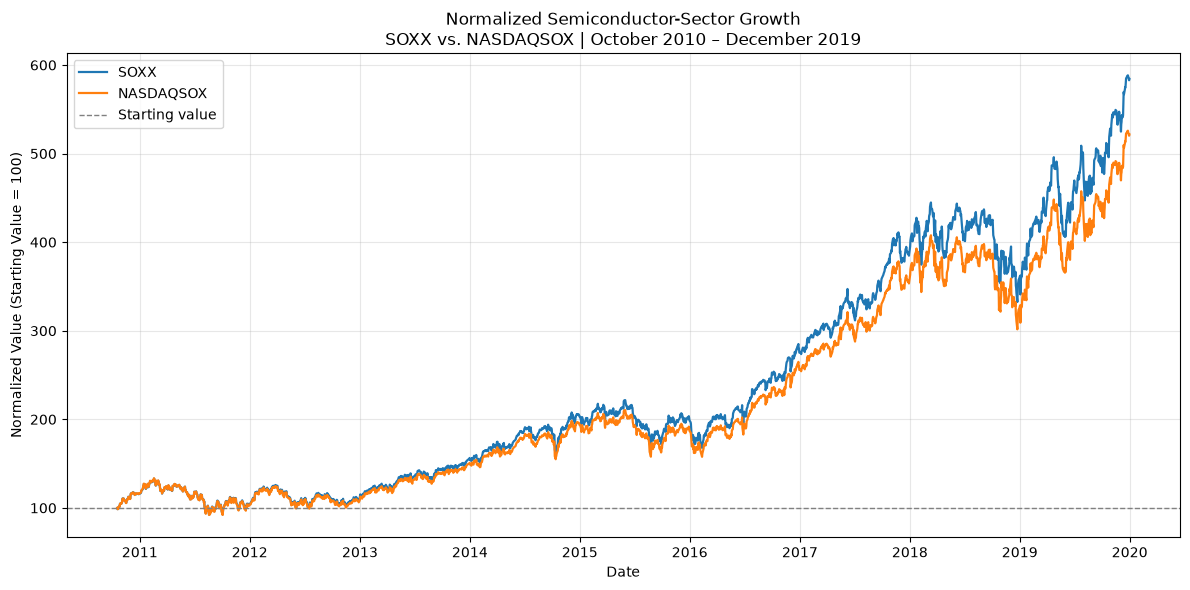

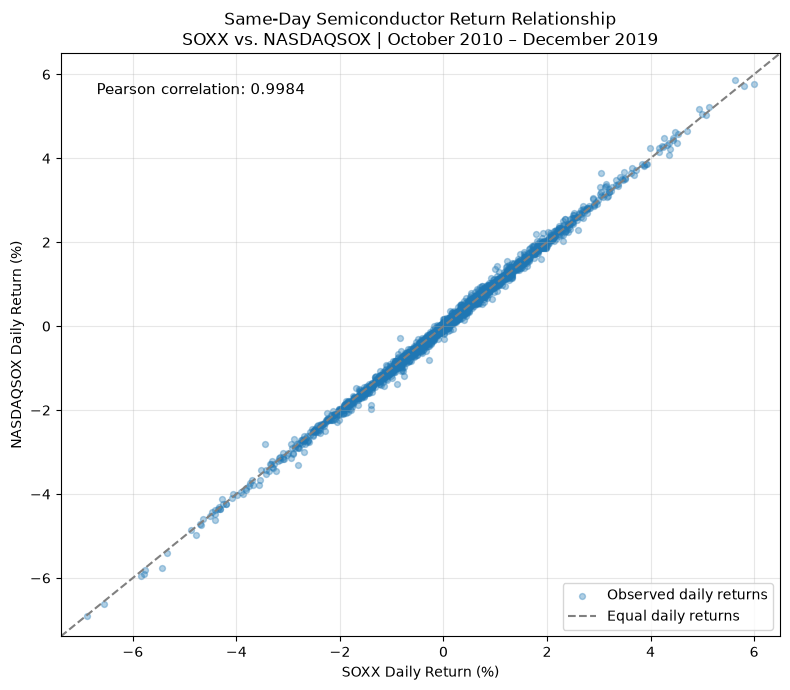

Both semiconductor-sector charts generated successfully.
All sector visualization validation checks passed.


In [25]:

# ============================================================
# 2.7.2 — Semiconductor Sector Relationship Visualizations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Preserve the original sector_context DataFrame.
sector_growth = sector_context[
    ["Date", "SOXX", "NASDAQSOX"]
].copy()

# ------------------------------------------------------------
# Part A — Normalize Both Series to 100
# ------------------------------------------------------------

for measure in ["SOXX", "NASDAQSOX"]:

    # Divide every observation by the starting value.
    # Multiplying by 100 rebases the series to 100.
    sector_growth[f"{measure} Indexed (100)"] = (
        sector_growth[measure]
        / sector_growth[measure].iloc[0]
    ) * 100

# Verify that both series begin at 100.
for measure in ["SOXX", "NASDAQSOX"]:

    assert np.isclose(
        sector_growth[f"{measure} Indexed (100)"].iloc[0],
        100.0
    )

# Validate SOXX normalized growth against Section 2.5.2.
np.testing.assert_allclose(
    sector_growth["SOXX Indexed (100)"].to_numpy(),
    compounding_history["SOXX Value (USD)"].to_numpy(),
    rtol=1e-9,
    atol=1e-8
)

# ------------------------------------------------------------
# Chart 1 — Normalized Historical Sector Growth
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

for measure in ["SOXX", "NASDAQSOX"]:

    ax.plot(
        sector_growth["Date"],
        sector_growth[f"{measure} Indexed (100)"],
        label=measure,
        linewidth=1.6
    )

# Initial normalized value.
ax.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Starting value"
)

ax.set_title(
    "Normalized Semiconductor-Sector Growth\n"
    "SOXX vs. NASDAQSOX | October 2010 – December 2019"
)

ax.set_xlabel("Date")
ax.set_ylabel("Normalized Value (Starting Value = 100)")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Chart 2 — Daily-Return Scatterplot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 7))

# Each dot represents one matched trading day.
ax.scatter(
    sector_returns["SOXX Return (%)"],
    sector_returns["NASDAQSOX Return (%)"],
    alpha=0.35,
    s=18,
    label="Observed daily returns"
)

# Calculate common axis bounds for an equality reference.
all_returns = sector_returns[
    ["SOXX Return (%)", "NASDAQSOX Return (%)"]
].to_numpy()

lower_bound = all_returns.min() - 0.5
upper_bound = all_returns.max() + 0.5

# A point on this line has equal X and Y values.
ax.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Equal daily returns"
)

ax.set_xlim(lower_bound, upper_bound)
ax.set_ylim(lower_bound, upper_bound)

ax.set_title(
    "Same-Day Semiconductor Return Relationship\n"
    "SOXX vs. NASDAQSOX | October 2010 – December 2019"
)

ax.set_xlabel("SOXX Daily Return (%)")
ax.set_ylabel("NASDAQSOX Daily Return (%)")

# Display the observed correlation inside the plot.
ax.text(
    0.05,
    0.95,
    f"Pearson correlation: {sector_correlation:.4f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top"
)

ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Part B — Additional Validation
# ------------------------------------------------------------

# Confirm the normalized values are finite and positive.
normalized_columns = [
    "SOXX Indexed (100)",
    "NASDAQSOX Indexed (100)"
]

assert np.isfinite(
    sector_growth[normalized_columns].to_numpy()
).all()

assert (
    sector_growth[normalized_columns] > 0
).all().all()

# Independently recompute the Pearson correlation with NumPy.
numpy_correlation = np.corrcoef(
    sector_returns["SOXX Return (%)"],
    sector_returns["NASDAQSOX Return (%)"]
)[0, 1]

np.testing.assert_allclose(
    numpy_correlation,
    sector_correlation,
    rtol=1e-10,
    atol=1e-10
)

print("Both semiconductor-sector charts generated successfully.")
print("All sector visualization validation checks passed.")



### 2.7.3 — Final Findings and Research Implications

#### Summary of Findings

Section 2.7 compared SOXX and NASDAQSOX using 2,316 matched daily returns between October 2010 and December 2019.

**1. Strong semiconductor-sector relationship**

The two measures exhibited a same-day Pearson correlation of **0.9984**.

The daily-return scatterplot showed observations closely concentrated around the equality line, indicating that the two measures generally moved together.

**2. Similar but not identical volatility**

SOXX had a daily return standard deviation of 1.460%, compared with 1.481% for NASDAQSOX.

Their mean absolute daily return difference was 0.0596 percentage points.

These results confirm that their historical return behaviour was closely related but not identical.

**3. Differences in cumulative growth**

Both normalized series began at 100 and experienced substantial growth through December 2019.

SOXX finished above NASDAQSOX, with their cumulative difference becoming more visible during the later years of the comparison.

Their high daily correlation did not guarantee identical cumulative performance.

**4. Research implications**

SOXX and NASDAQSOX provide closely related measures of historical semiconductor-sector conditions.

Their strong relationship supports using them as sector-context indicators, although including both in a predictive model may introduce redundant information.

Further modelling would be needed to determine whether either measure offers useful predictive information for SOXL downside risk.

#### Limitations

- SOXX uses dividend-adjusted ETF prices, whereas NASDAQSOX is an index-level series.
- Differences in construction and historical benchmark definitions limit direct equivalence.
- High contemporaneous correlation does not establish forecasting power.
- The comparison does not measure official leveraged-fund tracking accuracy.
- Results are restricted to the 2010–2019 development period.

#### Section Status

**Section 2.7 analytical work completed and individually validated.**

The analysis includes daily-return summaries, correlation measurements, normalized historical growth, scatterplots, and validation checks.

Final clean-kernel reproducibility verification remains outstanding until Stage 2 closeout.

**Next: Section 2.8 — VIX Relationships.**



## 2.8 — VIX Relationships

### 2.8.1 — VIX and Historical Realized Volatility

#### Objective

Examine how broader market-implied volatility relates to observed semiconductor-sector volatility and SOXL return behaviour during the development period.

We will compare VIX levels, changes in VIX, and trailing 20-day realized volatility.

---

### 1. What Is VIX?

The Cboe Volatility Index (VIX) measures the S&P 500 options market's expectation of volatility over approximately the next 30 calendar days.

It is commonly described as a market uncertainty or fear indicator.

A higher VIX generally indicates greater expected market fluctuation.

**Example:**

- VIX = 15 indicates approximately 15% annualized implied volatility.
- VIX = 30 indicates approximately 30% annualized implied volatility.

These are volatility estimates, not predictions that the S&P 500 will gain or lose exactly 15% or 30%.

VIX does not indicate the expected direction of market movement.

Our project uses `VIXCLS`, the historical VIX series obtained through Federal Reserve Economic Data (FRED). The underlying index is calculated by Cboe.

### 2. Implied Volatility vs. Realized Volatility

These measures answer different questions.

| Measure | Meaning | Time Direction |
|---|---|---|
| VIX | Options-implied expected S&P 500 volatility | Forward-looking |
| Realized volatility | Statistical variation of observed daily returns | Backward-looking |

VIX is based on option prices and reflects market expectations.

Realized volatility is calculated from actual historical price movements.

Our earlier Section 2.3 examined rolling 10-day and 20-day standard deviations of ETF returns.

We will now calculate **annualized 20-day realized volatility**, allowing a descriptive comparison with the annualized VIX index level.

These measures remain conceptually different because they cover different markets and observation horizons.

### 3. Annualizing Realized Volatility

A sample standard deviation measures the typical variation of observed daily returns around their historical mean.

We calculate trailing 20-day realized volatility using:

$$
\sigma_{20,t} =
\operatorname{StdDev}(r_{t-19},\ldots,r_t)
$$

We then annualize the result:

$$
\sigma_{\mathrm{annualized},t}
=\sigma_{20,t}\sqrt{252}
$$

Where:

- $\sigma_{20,t}$ = trailing 20-day sample standard deviation of daily percentage returns
- $252$ = conventional approximate number of trading days per year
- $\sqrt{252}$ = annualization factor

**Numerical example:**

Suppose a semiconductor ETF has a 20-day daily-return standard deviation of 2%.

Its annualized realized volatility would be:

$$
2\%\times\sqrt{252}\approx31.75\%
$$

Annualization makes the scale easier to compare with VIX, but it does not make the underlying measures identical.

The square-root-of-time convention is an approximation and does not fully account for changing volatility or dependence between daily returns.

### 4. Changes in VIX

We will also measure the daily change in VIX:

$$
\Delta VIX_t=VIX_t-VIX_{t-1}
$$

For example, if VIX increases from 18 to 22:

$$
\Delta VIX=22-18=4
$$

This is an increase of **4 index points**, not 4 percentage points of an ETF return.

We will keep VIX changes separate from VIX levels.

### 5. Research Questions

We will investigate:

- How VIX levels varied during the development period.
- Whether VIX tended to be higher when realized semiconductor volatility was higher.
- How VIX related to SOXL's trailing realized volatility.
- Whether same-day changes in VIX were associated with SOXL daily returns.

These comparisons are descriptive.

A same-day relationship does not establish that VIX could have predicted SOXL's return before that day occurred.

### 6. Python Methods

We will use:

- `.diff()` to calculate daily changes in VIX.
- `.rolling(20)` to construct trailing 20-day windows.
- `.std(ddof=1)` to calculate sample standard deviations.
- `np.sqrt(252)` to annualize daily volatility.
- `.corr()` to calculate contemporaneous Pearson correlations.
- `.dropna()` to exclude dates without enough historical observations.

The first daily return is unavailable because no preceding price exists.

The first 20-day rolling volatility observation requires 20 valid daily returns. Earlier incomplete windows remain missing.

### 7. Research Period and Limitations

We will use the full March 2010–December 2019 development period for this initial VIX analysis.

Unlike the specific SOXX-relative leverage comparisons in Sections 2.4–2.7, this section does not attempt to measure the leveraged funds' historical benchmark tracking.

SOXX's predecessor-history caveat still applies to interpretations of early sector behaviour.

Additional limitations:

- VIX measures expected S&P 500 volatility, not semiconductor-specific volatility.
- Trailing 20-day realized volatility and forward-looking 30-day implied volatility have different horizons.
- Their levels are not expected to match.
- Same-day relationships are not forecasting evidence.
- Later predictive analysis must respect when information becomes available.

**Sources:**

- [Cboe VIX FAQ](https://www.cboe.com/tradable_products/vix/faqs)
- [FRED VIXCLS Series](https://fred.stlouisfed.org/series/VIXCLS)


In [26]:

# ============================================================
# 2.8.1 — VIX and Historical Realized Volatility
# Development period: March 2010 – December 2019
# ============================================================

import numpy as np
import pandas as pd

# Reuse the development-period data from Section 2.1.
# Do not modify the original DataFrame.
vix_context = (
    development[
        [
            "Date",
            "VIXCLS",
            "SOXX Return (%)",
            "SOXL Return (%)"
        ]
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# Part A — Validate Historical Data
# ------------------------------------------------------------

assert vix_context["Date"].is_unique
assert vix_context["Date"].is_monotonic_increasing

assert vix_context["VIXCLS"].notna().all()
assert (vix_context["VIXCLS"] > 0).all()

assert vix_context["Date"].min() == pd.Timestamp("2010-03-11")
assert vix_context["Date"].max() == pd.Timestamp("2019-12-31")

print("VIX Development Data")
print("First date:", vix_context["Date"].min().date())
print("Last date:", vix_context["Date"].max().date())
print("VIX observations:", len(vix_context))

# ------------------------------------------------------------
# Part B — Calculate Daily VIX Changes
# ------------------------------------------------------------

# diff() subtracts the preceding observation.
# Example: VIX 22 - VIX 18 = +4 index points.
vix_context["VIX Daily Change (points)"] = (
    vix_context["VIXCLS"].diff()
)

# ------------------------------------------------------------
# Part C — Calculate Annualized Realized Volatility
# ------------------------------------------------------------

rolling_window = 20
trading_days_per_year = 252

for ticker in ["SOXX", "SOXL"]:

    # Return columns are already expressed in percentages.
    # We therefore do NOT multiply by 100 again.
    vix_context[f"{ticker} 20d Realized Vol (%)"] = (
        vix_context[f"{ticker} Return (%)"]
        .rolling(
            window=rolling_window,
            min_periods=rolling_window
        )
        .std(ddof=1)
        * np.sqrt(trading_days_per_year)
    )

# ------------------------------------------------------------
# Part D — Prepare Complete Rolling Observations
# ------------------------------------------------------------

volatility_columns = [
    "SOXX 20d Realized Vol (%)",
    "SOXL 20d Realized Vol (%)"
]

vix_volatility = (
    vix_context
    .dropna(subset=["VIXCLS"] + volatility_columns)
    .copy()
)

print("\nValid 20-day volatility observations:",
      len(vix_volatility))

print("First valid rolling date:",
      vix_volatility["Date"].min().date())

# ------------------------------------------------------------
# Part E — Summarize Volatility Levels
# ------------------------------------------------------------

comparison_columns = ["VIXCLS"] + volatility_columns

vix_volatility_summary = pd.DataFrame({
    "Mean": vix_volatility[comparison_columns].mean(),
    "Median": vix_volatility[comparison_columns].median(),
    "Minimum": vix_volatility[comparison_columns].min(),
    "Maximum": vix_volatility[comparison_columns].max()
})

print("\nVIX and Annualized Realized Volatility Summary")
display(vix_volatility_summary.round(3))

# ------------------------------------------------------------
# Part F — Contemporaneous Correlations
# ------------------------------------------------------------

vix_soxx_correlation = vix_volatility["VIXCLS"].corr(
    vix_volatility["SOXX 20d Realized Vol (%)"]
)

vix_soxl_correlation = vix_volatility["VIXCLS"].corr(
    vix_volatility["SOXL 20d Realized Vol (%)"]
)

# Use dates with valid daily VIX changes and SOXL returns.
vix_daily = vix_context.dropna(
    subset=[
        "VIX Daily Change (points)",
        "SOXL Return (%)"
    ]
).copy()

vix_soxl_daily_correlation = (
    vix_daily["VIX Daily Change (points)"]
    .corr(vix_daily["SOXL Return (%)"])
)

vix_correlation_summary = pd.DataFrame({
    "Relationship": [
        "VIX vs. SOXX trailing 20d realized volatility",
        "VIX vs. SOXL trailing 20d realized volatility",
        "Daily VIX change vs. same-day SOXL return"
    ],
    "Pearson Correlation": [
        vix_soxx_correlation,
        vix_soxl_correlation,
        vix_soxl_daily_correlation
    ],
    "Observations": [
        len(vix_volatility),
        len(vix_volatility),
        len(vix_daily)
    ]
})

print("\nContemporaneous VIX Relationships")
display(vix_correlation_summary.round(4))

# ------------------------------------------------------------
# Part G — Validation
# ------------------------------------------------------------

# First daily returns and VIX changes are unavailable.
assert pd.isna(vix_context["SOXX Return (%)"].iloc[0])
assert pd.isna(vix_context["SOXL Return (%)"].iloc[0])
assert pd.isna(vix_context["VIX Daily Change (points)"].iloc[0])

# The first valid rolling result occurs after 20 returns.
assert len(vix_volatility) == len(vix_context) - rolling_window

assert vix_volatility.index[0] == rolling_window

# Independently check the first SOXX rolling volatility.
first_20_returns = (
    vix_context["SOXX Return (%)"]
    .iloc[1:rolling_window + 1]
    .to_numpy()
)

expected_first_volatility = (
    np.std(first_20_returns, ddof=1)
    * np.sqrt(trading_days_per_year)
)

actual_first_volatility = (
    vix_context.loc[
        rolling_window,
        "SOXX 20d Realized Vol (%)"
    ]
)

np.testing.assert_allclose(
    actual_first_volatility,
    expected_first_volatility,
    rtol=1e-10,
    atol=1e-10
)

# Confirm the first calculated VIX change.
assert np.isclose(
    vix_context.loc[1, "VIX Daily Change (points)"],
    vix_context.loc[1, "VIXCLS"]
    - vix_context.loc[0, "VIXCLS"]
)

# All retained volatility values must be finite.
assert np.isfinite(
    vix_volatility[comparison_columns].to_numpy()
).all()

# All correlations must be valid Pearson coefficients.
assert (
    vix_correlation_summary["Pearson Correlation"]
    .between(-1, 1)
).all()

print("\nAll VIX and realized-volatility checks passed.")


VIX Development Data
First date: 2010-03-11
Last date: 2019-12-31
VIX observations: 2470

Valid 20-day volatility observations: 2450
First valid rolling date: 2010-04-09

VIX and Annualized Realized Volatility Summary


,Mean,Median,Minimum,Maximum
VIXCLS,16.777,15.320,9.140,48.000
SOXX 20d Realized Vol (%),22.473,20.583,6.635,53.966
SOXL 20d Realized Vol (%),67.772,61.771,19.515,161.739



Contemporaneous VIX Relationships


,Relationship,Pearson Correlation,Observations
0,VIX vs. SOXX trailing 20d realized volatility,0.6725,2450
1,VIX vs. SOXL trailing 20d realized volatility,0.6784,2450
2,Daily VIX change vs. same-day SOXL return,-0.6591,2469



All VIX and realized-volatility checks passed.



#### Results and Interpretation

The analysis covered March 11, 2010, through December 31, 2019, with 2,450 valid trailing 20-day volatility observations and 2,469 daily VIX-change observations.

**1. Historical volatility levels**

| Measure | Mean | Median | Maximum |
|---|---:|---:|---:|
| VIX | 16.777 | 15.320 | 48.000 |
| SOXX 20-day realized volatility (%) | 22.473 | 20.583 | 53.966 |
| SOXL 20-day realized volatility (%) | 67.772 | 61.771 | 161.739 |

SOXL experienced substantially greater realized volatility than SOXX during the development period.

Its mean annualized 20-day realized volatility was approximately three times SOXX's.

VIX levels were generally lower than SOXL's realized volatility, but these measures represent different markets, time horizons, and volatility concepts. Their levels should not be interpreted as directly equivalent.

**2. VIX and trailing realized volatility**

The Pearson correlations were:

- VIX versus SOXX realized volatility: **+0.6725**
- VIX versus SOXL realized volatility: **+0.6784**

Both relationships were positive.

Periods with higher VIX levels generally coincided with periods of higher trailing semiconductor ETF volatility.

These relationships suggest that broader market uncertainty and semiconductor-sector volatility often moved together.

**3. VIX changes and SOXL daily returns**

The correlation between daily VIX changes and same-day SOXL returns was **-0.6591**.

This indicates a negative contemporaneous relationship.

Days with increases in VIX often coincided with negative SOXL returns, although the relationship was not exact.

**4. Research implications**

VIX appears to be a potentially relevant market-risk context variable for the broader SOXL downside-risk project.

However, the results are descriptive. They do not establish that VIX provides useful information about future SOXL losses beyond what is available from semiconductor-sector returns or trailing volatility.

Any forecasting application must use information available at the prediction time and be evaluated out of sample.

**Limitations**

- VIX represents S&P 500 options-implied volatility, not semiconductor-specific volatility.
- VIX has an approximately 30-calendar-day forward-looking horizon.
- The realized-volatility measures use trailing 20-trading-day windows.
- Overlapping rolling observations are statistically dependent.
- Same-day correlations do not establish forecasting power or causation.
- No 2026 holdout data were used.

**Next:** Visualize the historical relationships between VIX, realized semiconductor volatility, and SOXL daily returns.



### 2.8.2 — Visualizing VIX Relationships

#### Objective

Visualize the historical relationships between broader market-implied volatility, semiconductor realized volatility, and SOXL daily returns.

We will create three charts using the validated development-period data.

---

### 1. VIX and SOXX Realized Volatility Over Time

The first chart compares historical VIX levels with annualized trailing 20-day SOXX realized volatility.

Both series represent measures of market volatility, but they are not identical:

- **VIX:** Forward-looking, S&P 500 options-implied volatility.
- **SOXX realized volatility:** Backward-looking, calculated from historical SOXX returns.

We will examine whether periods of higher VIX generally coincided with higher semiconductor-sector realized volatility.

**Important:** Differences in their levels are expected because the measures cover different markets and time horizons.

### 2. VIX and SOXL Realized Volatility

The second chart uses a scatterplot.

- Horizontal axis: VIX level.
- Vertical axis: SOXL annualized 20-day realized volatility.
- Each point: One matched trading day.

We previously calculated a Pearson correlation of **+0.6784**.

The scatterplot will help us see whether the positive relationship is broadly distributed or influenced by a smaller number of observations.

A positive correlation does not imply that every increase in VIX produces an increase in SOXL realized volatility.

### 3. Daily VIX Changes and SOXL Returns

The third chart examines:

- Horizontal axis: Daily change in VIX, measured in index points.
- Vertical axis: Same-day SOXL return, measured in percent.

We previously observed a correlation of **-0.6591**.

The scatterplot will show whether the negative relationship is visible across the historical observations.

We will include horizontal and vertical reference lines at zero to distinguish positive and negative changes.

Unlike the SOXX-versus-NASDAQSOX scatterplot, an equality diagonal is not appropriate here because the two variables have different units.

### 4. Python Methods

We will use:

- `plt.plot()` to compare volatility measures through time.
- `ax.scatter()` to display daily observations.
- `ax.axhline()` and `ax.axvline()` to mark zero.
- `alpha` to make overlapping points easier to identify.
- `np.corrcoef()` to independently confirm the correlations used in the chart interpretations.

### 5. Interpretation and Limitations

All visualizations use historical observations from March 2010 through December 2019.

The relationships are contemporaneous and descriptive.

They do not establish that VIX predicts future SOXL returns or that its information would improve a risk forecasting model.

That question requires explicitly defined forecast timing, lagged predictors where appropriate, and out-of-sample evaluation.


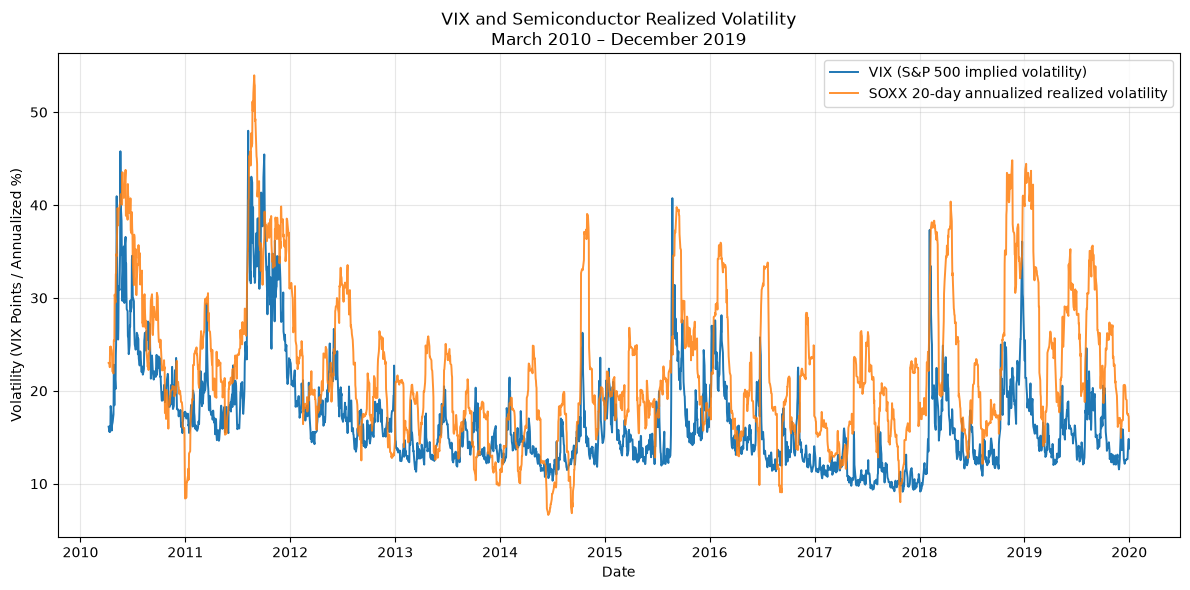

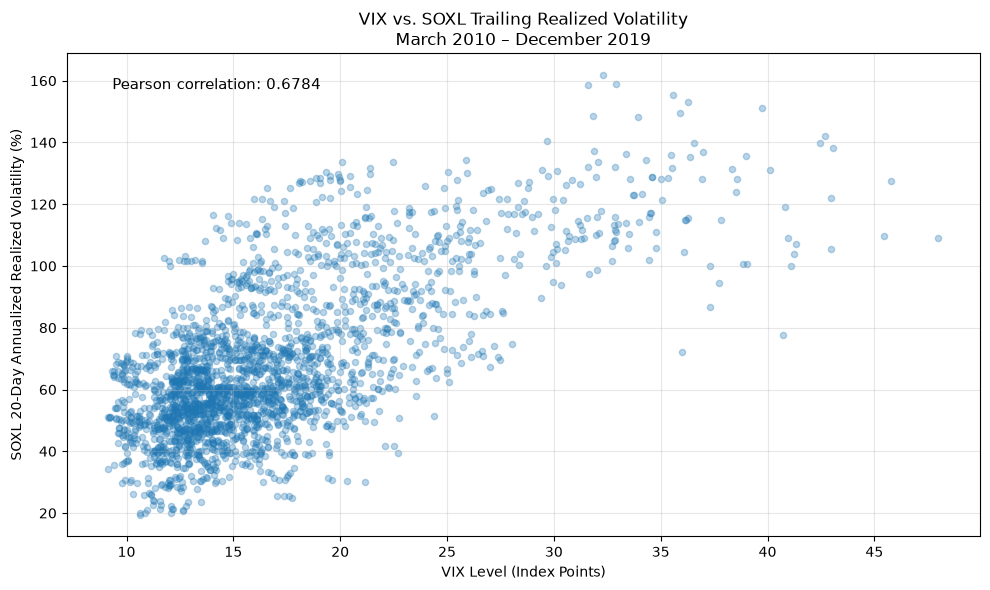

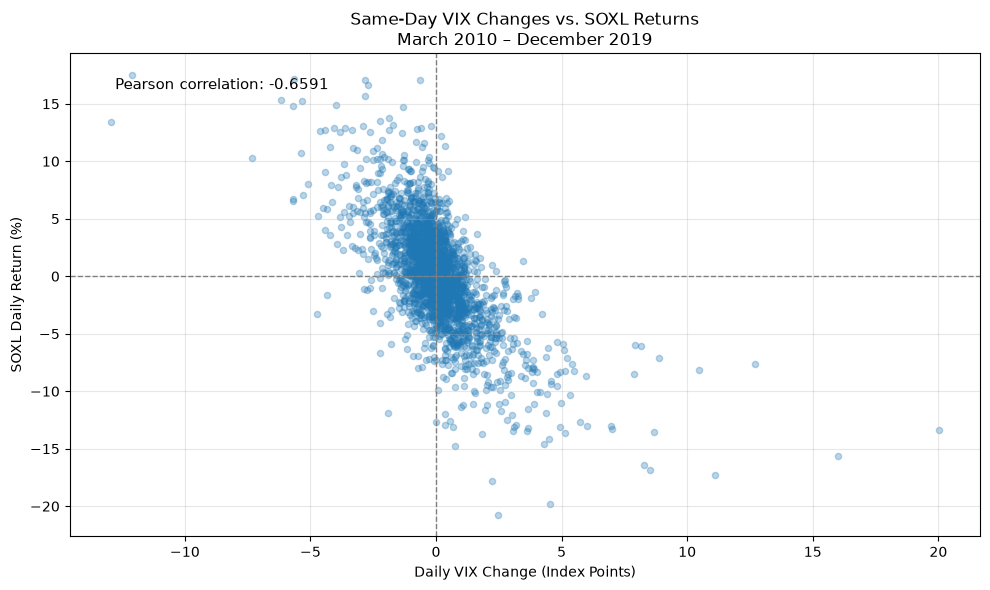

All three VIX visualizations generated successfully.
All VIX visualization validation checks passed.


In [27]:

# ============================================================
# 2.8.2 — Visualizing Historical VIX Relationships
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Preserve the existing analysis DataFrames.
vix_plot_data = (
    vix_volatility.sort_values("Date").copy()
)

vix_daily_plot = (
    vix_daily.sort_values("Date").copy()
)

# ------------------------------------------------------------
# Chart 1 — VIX vs. SOXX Realized Volatility Over Time
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    vix_plot_data["Date"],
    vix_plot_data["VIXCLS"],
    label="VIX (S&P 500 implied volatility)",
    linewidth=1.4
)

ax.plot(
    vix_plot_data["Date"],
    vix_plot_data["SOXX 20d Realized Vol (%)"],
    label="SOXX 20-day annualized realized volatility",
    linewidth=1.4,
    alpha=0.85
)

ax.set_title(
    "VIX and Semiconductor Realized Volatility\n"
    "March 2010 – December 2019"
)

ax.set_xlabel("Date")
ax.set_ylabel("Volatility (VIX Points / Annualized %)")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Chart 2 — VIX vs. SOXL Realized Volatility
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    vix_plot_data["VIXCLS"],
    vix_plot_data["SOXL 20d Realized Vol (%)"],
    alpha=0.3,
    s=20
)

ax.set_title(
    "VIX vs. SOXL Trailing Realized Volatility\n"
    "March 2010 – December 2019"
)

ax.set_xlabel("VIX Level (Index Points)")
ax.set_ylabel("SOXL 20-Day Annualized Realized Volatility (%)")

# Show the verified Pearson correlation.
ax.text(
    0.05,
    0.95,
    f"Pearson correlation: {vix_soxl_correlation:.4f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top"
)

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Chart 3 — Daily VIX Change vs. SOXL Daily Return
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    vix_daily_plot["VIX Daily Change (points)"],
    vix_daily_plot["SOXL Return (%)"],
    alpha=0.3,
    s=20
)

# Separate positive and negative market movements.
ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(
    x=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Same-Day VIX Changes vs. SOXL Returns\n"
    "March 2010 – December 2019"
)

ax.set_xlabel("Daily VIX Change (Index Points)")
ax.set_ylabel("SOXL Daily Return (%)")

ax.text(
    0.05,
    0.95,
    f"Pearson correlation: {vix_soxl_daily_correlation:.4f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top"
)

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Validation — Confirm Charts Use the Correct Observations
# ------------------------------------------------------------

assert len(vix_plot_data) == 2450
assert len(vix_daily_plot) == 2469

# Independently calculate the VIX/SOXL volatility correlation.
calculated_vol_correlation = np.corrcoef(
    vix_plot_data["VIXCLS"],
    vix_plot_data["SOXL 20d Realized Vol (%)"]
)[0, 1]

np.testing.assert_allclose(
    calculated_vol_correlation,
    vix_soxl_correlation,
    rtol=1e-10,
    atol=1e-10
)

# Independently calculate the daily-change correlation.
calculated_daily_correlation = np.corrcoef(
    vix_daily_plot["VIX Daily Change (points)"],
    vix_daily_plot["SOXL Return (%)"]
)[0, 1]

np.testing.assert_allclose(
    calculated_daily_correlation,
    vix_soxl_daily_correlation,
    rtol=1e-10,
    atol=1e-10
)

print("All three VIX visualizations generated successfully.")
print("All VIX visualization validation checks passed.")



### 2.8.3 — Final Findings and Research Implications

#### Summary of Findings

Section 2.8 examined historical relationships between VIX, semiconductor-sector realized volatility, and SOXL returns during the 2010–2019 development period.

**1. VIX and historical realized volatility**

The correlations between VIX and trailing 20-day annualized realized volatility were:

| Relationship | Pearson Correlation |
|---|---:|
| VIX vs. SOXX realized volatility | +0.6725 |
| VIX vs. SOXL realized volatility | +0.6784 |
| Daily VIX change vs. same-day SOXL return | -0.6591 |

VIX generally increased during periods of elevated semiconductor-sector volatility. However, SOXX and SOXL realized volatility also experienced movements that were not matched exactly by VIX.

This is expected because VIX represents forward-looking S&P 500 implied volatility, whereas our realized-volatility measures are based on historical semiconductor ETF returns.

**2. Positive relationship with SOXL realized volatility**

The scatterplot showed a positive relationship between VIX levels and SOXL's trailing 20-day realized volatility.

Higher VIX observations were generally associated with higher realized SOXL volatility, but there was considerable variation.

VIX alone therefore does not fully describe SOXL's historical volatility.

**3. Negative same-day relationship with SOXL returns**

Daily VIX changes had a Pearson correlation of -0.6591 with same-day SOXL returns.

The scatterplot showed that larger VIX increases frequently coincided with negative SOXL returns.

This relationship was not exact. Positive and negative SOXL returns occurred across different VIX-change observations.

**4. Research implications**

VIX appears relevant as a broader market-risk context indicator.

The historical evidence suggests that broader market uncertainty and semiconductor volatility often moved together.

However, we have not established whether VIX improves forecasts of future SOXL losses.

That requires a properly timed prediction exercise and comparison with models that use semiconductor-sector information without VIX.

#### Methodological Limitations

- The correlations are contemporaneous, not predictive.
- VIX and realized volatility describe different markets and horizons.
- Overlapping realized-volatility windows create statistical dependence.
- The results do not establish causality.
- They do not establish incremental predictive value from VIX.
- All exploratory observations are restricted to 2010–2019.

#### Section Status

**Section 2.8 analytical work completed and individually validated.**

The analysis includes annualized realized-volatility calculations, VIX changes, correlation measurements, three visualizations, and validation checks.

Final notebook-wide reproducibility verification remains outstanding.

**Next: Section 2.9 — Final Exploratory Findings, Limitations, and Validation.**



## 2.9 — Final Exploratory Findings and Validation

### 2.9.1 — Consolidated Research Findings

#### Objective

Summarize the main findings from Notebook 02 and identify their implications for the next stages of the SOXL Risk Analysis project.

The analysis is descriptive and uses the 2010–2019 development period only.

---

### 1. Daily Returns and Downside Risk (Section 2.2)

SOXL exhibited substantially greater daily-return variation than SOXX.

During the development period:

- SOXL daily return standard deviation: approximately 4.51%.
- SOXX daily return standard deviation: approximately 1.49%.
- SOXL worst observed daily return: -20.72%.
- SOXL losses of at least 10% occurred on approximately 2.07% of observed trading days.

These results establish that large SOXL losses were present in the historical development sample, even though its long-term investment performance was positive.

### 2. Historical Volatility (Section 2.3)

Historical volatility varied considerably over time.

Rolling-volatility charts demonstrated periods of relatively calm returns and periods of much greater daily variation.

Positive absolute-return autocorrelations were also observed at selected lags, consistent with volatility clustering.

This suggests that recent historical volatility may provide useful context for describing changing market conditions.

It does not establish that volatility clustering can successfully predict future losses.

### 3. Daily Leverage Relationships (Section 2.4)

SOXL and SOXS exhibited strong contemporaneous relationships with SOXX returns.

The observed regression slopes were approximately:

- SOXL: +3.0056
- SOXS: -3.0085

However, individual daily returns deviated from the illustrative leverage multiples.

SOXX is not necessarily the exact historical underlying benchmark, so these comparisons are not official fund tracking-error measurements.

### 4. Compounding and Path Dependence (Section 2.5)

Daily leveraged returns compounded over time, creating differences from simple cumulative leverage multiples.

For the hypothetical +3x daily SOXX investment, median compounding gaps were:

| Holding Period | Median Gap |
|---|---:|
| 5 trading days | -0.038 pp |
| 10 trading days | -0.153 pp |
| 20 trading days | -0.390 pp |

SOXL also experienced substantial negative returns across shorter holding periods.

Approximately 11.8% of historical five-day windows experienced a cumulative SOXL loss of at least 10%.

These findings support studying downside risk over multiple horizons instead of assuming that daily leverage relationships extend directly to multi-day returns.

### 5. Historical Drawdowns and Recovery (Section 2.6)

SOXL experienced a maximum historical drawdown of approximately -72.61%, compared with -30.50% for SOXX.

SOXL's worst drawdown required 751 trading-day intervals to recover its previous peak.

Recovery durations also differed across drawdown severity categories.

Among completed SOXL drawdowns:

- Shallow drawdowns had a median recovery duration of 3 trading days.
- Moderate drawdowns had a median of 15.5 days.
- Severe drawdowns had a median of 61.5 days.

These results demonstrate that strong cumulative investment growth can coexist with severe losses and prolonged recovery periods.

Recovery-duration summaries exclude unresolved episodes and must be interpreted accordingly.

### 6. Semiconductor-Sector Context (Section 2.7)

SOXX and NASDAQSOX exhibited a strong same-day return correlation of +0.9984.

Their mean absolute daily return difference was 0.0596 percentage points.

The two measures generally reflected similar semiconductor-sector movements, although their return definitions and cumulative growth differed.

Their strong relationship suggests potentially redundant information if both are included as explanatory variables in a future model.

This remains a modelling consideration, not a tested conclusion about predictive performance.

### 7. VIX Relationships (Section 2.8)

VIX exhibited positive contemporaneous correlations with semiconductor realized volatility.

The correlation between VIX and SOXL trailing 20-day annualized volatility was +0.6784.

Daily VIX changes were negatively correlated with same-day SOXL returns, with a correlation of -0.6591.

These findings suggest that broader market volatility conditions may provide useful context for understanding historical semiconductor risk.

However, no evidence of incremental future predictive power has been established.

---

### 8. Overall Research Conclusions

The exploratory analysis supports four main observations.

**First, SOXL has substantial historical downside exposure.**

Its daily-return distribution, rolling multi-day losses, and maximum drawdowns show that large negative outcomes occurred during the development period.

**Second, historical risk conditions changed over time.**

Realized volatility varied across the sample, and absolute-return autocorrelations were positive at several examined lags.

**Third, daily leverage does not fully describe multi-day performance.**

Compounding and path dependence affected the hypothetical leveraged investment paths, and actual ETF returns also reflected fund-specific and benchmark-related differences.

**Fourth, semiconductor-sector indicators and VIX provide related market context.**

Both may be relevant to future model development, but descriptive correlations do not establish their predictive usefulness.

### 9. Important Limitations

The analysis has several limitations that must remain visible in subsequent stages.

**Historical sample and selection**

All findings are restricted to the development period. Market conditions from 2010–2019 may not represent later periods.

**Overlapping observations**

Rolling returns and realized-volatility windows overlap. Their observations are statistically dependent.

**Benchmark differences**

SOXX is not necessarily SOXL's exact historical underlying benchmark. The historical SOXX predecessor regime also requires care.

**Data definitions**

ETF adjusted-price returns and semiconductor index-level returns are not identical financial quantities.

**Descriptive evidence**

Correlations, historical downside frequencies, and retrospective drawdowns do not establish forecasting performance.

**Information timing**

Future risk models must use only information available when each forecast would have been made. Same-day closing information cannot be treated as available before that day's close.

**Unresolved recovery episodes**

Drawdowns without observed recovery dates are right-censored and cannot be assigned completed recovery durations.

**Source limitations**

The project's previously documented market-data provenance, historical anomalies, and outstanding source-rights review remain relevant.

### 10. Implications for Later Project Stages

The exploratory results motivate further investigation of:

- Trailing realized volatility as a potential risk indicator.
- Recent semiconductor-sector returns and market conditions.
- VIX levels and changes.
- Short-horizon SOXL downside outcomes.
- The incremental value of VIX relative to simpler sector-based baselines.

These are candidate modelling directions, not validated predictive relationships.

The project's original evaluation design remains unchanged:

- **Development:** 2010–2019.
- **Walk-forward evaluation:** 2020–2025.
- **Final holdout:** January–October 30, 2026.

The 2026 holdout will remain reserved until the modelling methodology and evaluation choices are finalized.

**Next:** Perform final notebook-wide integrity and reproducibility checks before closing Stage 2.



### 2.9.2 — Final Integrity and Reproducibility Checks

#### Objective

Confirm that the exploratory analysis uses the intended historical periods and that its important intermediate results remain consistent.

Individual notebook sections already contain their own validation checks.

This final audit checks the larger analysis workflow.

#### What We Will Verify

**1. Date restrictions**

Every exploratory dataset must remain within the 2010–2019 development period.

No analysis table may include observations from the reserved 2026 holdout.

**2. Observation counts**

The main datasets must retain the expected numbers of observations.

This helps detect accidental filtering, duplicated rows, or changes to our historical alignment.

**3. Historical calculations**

The summary statistics for rolling holding periods, drawdowns, sector correlations, and VIX relationships must match our individually reviewed results.

**4. Research reproducibility**

After the audit, we will restart the Jupyter kernel and execute Notebook 02 from beginning to end.

A successful fresh-kernel execution provides evidence that the notebook does not depend on variables or manual commands from an earlier interactive session.

#### Important Distinction

Passing these checks verifies internal consistency and reproducibility under the current data and code.

It does not independently prove that all external financial source records are correct, or that the analysis provides predictive forecasting ability.


In [28]:

# ============================================================
# 2.9.2 — Final Exploratory Analysis Integrity Audit
# ============================================================

import numpy as np
import pandas as pd

development_start = pd.Timestamp("2010-01-01")
development_end = pd.Timestamp("2019-12-31")

# ------------------------------------------------------------
# Part A — Validate All Main Research Date Ranges
# ------------------------------------------------------------

research_frames = {
    "Development": (development, 2470),
    "Compounding history": (compounding_history, 2317),
    "Drawdown history": (drawdown_history, 2317),
    "Sector context": (sector_context, 2317),
    "Sector returns": (sector_returns, 2316),
    "VIX rolling volatility": (vix_volatility, 2450),
    "VIX daily changes": (vix_daily, 2469)
}

audit_rows = []

for name, (frame, expected_count) in research_frames.items():

    dates = pd.to_datetime(frame["Date"])

    # Every record must be inside the development period.
    assert dates.between(
        development_start, development_end
    ).all(), f"Date-range failure: {name}"

    # Each table must have the expected number of rows.
    assert len(frame) == expected_count, (
        f"Row-count failure: {name}"
    )

    # There must be no duplicate trading dates.
    assert dates.is_unique, (
        f"Duplicate dates found: {name}"
    )

    audit_rows.append({
        "Dataset": name,
        "Rows": len(frame),
        "First Date": dates.min().date(),
        "Last Date": dates.max().date(),
        "Check": "Passed"
    })

audit_summary = pd.DataFrame(audit_rows)

print("Development-Period Dataset Audit")
display(audit_summary)

# ------------------------------------------------------------
# Part B — Validate Rolling Holding Periods
# ------------------------------------------------------------

expected_windows = {
    5: 2312,
    10: 2307,
    20: 2297
}

for horizon, expected_count in expected_windows.items():

    subset = rolling_holding_periods[
        rolling_holding_periods["Holding Period (Days)"]
        == horizon
    ]

    assert len(subset) == expected_count

    assert pd.to_datetime(
        subset["Start Date"]
    ).between(development_start, development_end).all()

    assert pd.to_datetime(
        subset["End Date"]
    ).between(development_start, development_end).all()

    assert (
        pd.to_datetime(subset["Start Date"]).to_numpy()
        <
        pd.to_datetime(subset["End Date"]).to_numpy()
    ).all()

print("\nRolling holding-period counts verified.")

# ------------------------------------------------------------
# Part C — Verify Major Historical Findings
# ------------------------------------------------------------

# Drawdown values are compared with the rounded
# results previously reviewed in Section 2.6.
expected_drawdowns = {
    "SOXX": -30.496,
    "SOXL": -72.606,
    "SOXS": -99.980
}

for ticker, expected in expected_drawdowns.items():

    observed = historical_drawdown_summary.loc[
        ticker, "Maximum Drawdown (%)"
    ]

    np.testing.assert_allclose(
        observed,
        expected,
        atol=0.002,
        rtol=0
    )

# Ensure the final recovery summaries are consistent.
assert recovery_summary.loc[
    "SOXL", "Recovered Episodes"
] == 74

assert recovery_summary.loc[
    "SOXX", "Recovered Episodes"
] == 107

assert recovery_summary.loc[
    "SOXS", "Recovered Episodes"
] == 0

# Check the verified sector relationship.
np.testing.assert_allclose(
    sector_correlation,
    0.9984,
    atol=0.0001,
    rtol=0
)

# Check the verified VIX relationships.
np.testing.assert_allclose(
    vix_soxx_correlation,
    0.6725,
    atol=0.0001,
    rtol=0
)

np.testing.assert_allclose(
    vix_soxl_correlation,
    0.6784,
    atol=0.0001,
    rtol=0
)

np.testing.assert_allclose(
    vix_soxl_daily_correlation,
    -0.6591,
    atol=0.0001,
    rtol=0
)

# ------------------------------------------------------------
# Part D — Confirm the Historical Cutoff of Key Outputs
# ------------------------------------------------------------

for date_column in [
    "Peak Date",
    "Trough Date",
    "Recovery Date"
]:
    observed_dates = pd.to_datetime(
        drawdown_episodes[date_column]
    ).dropna()

    assert (observed_dates <= development_end).all()

print("Drawdown, recovery, sector, and VIX results verified.")
print("No post-2019 dates found in the audited research tables.")
print("\nAll Stage 2 final integrity checks passed.")


Development-Period Dataset Audit


,Dataset,Rows,First Date,Last Date,Check
0,Development,2470,2010-03-11,2019-12-31,Passed
1,Compounding history,2317,2010-10-18,2019-12-31,Passed
2,Drawdown history,2317,2010-10-18,2019-12-31,Passed
3,Sector context,2317,2010-10-18,2019-12-31,Passed
4,Sector returns,2316,2010-10-19,2019-12-31,Passed
5,VIX rolling volatility,2450,2010-04-09,2019-12-31,Passed
6,VIX daily changes,2469,2010-03-12,2019-12-31,Passed



Rolling holding-period counts verified.
Drawdown, recovery, sector, and VIX results verified.
No post-2019 dates found in the audited research tables.

All Stage 2 final integrity checks passed.
